Training a neuro evolution based model to learn to win 2048 game.

# Game

## Game functions

In [2]:
!pip install numpy torch pandas matplotlib

In [3]:
import random
import numpy as np

BOARD_SIZE = 4
EMPTY_TILE = 0

In [4]:
def spawn_tile(board):
  empty_tiles = np.argwhere(board == EMPTY_TILE)

  if len(empty_tiles) == 0: return board

  i, j = random.choice(empty_tiles.tolist())
  board[i, j] = random.choices([1, 2], weights=[0.9, 0.1], k=1)[0]

  return board

In [5]:
def generate_board():
  board = np.array([[EMPTY_TILE]*BOARD_SIZE for _ in range(BOARD_SIZE)])

  # The classic 2048 game begins on a 4×4 grid initialized with two random starting tiles placed in random empty cells.
  return spawn_tile(spawn_tile(board))

In [6]:
def show_board(board):
  for row in board:
    for tile in row:
      if tile == EMPTY_TILE:
        print('_', end=' ')
      else:
        print(1 << tile, end=' ')
    print()
  print()

In [7]:
board = generate_board()
show_board(board)

_ _ _ _ 
2 _ _ _ 
_ _ _ 2 
_ _ _ _ 



In [8]:
def clean(array):
  return [tile for tile in array if tile != EMPTY_TILE]

In [9]:
def combine(array):
  if len(array) == 1: return array, 0

  combined_array = []
  i = 0
  score = 0
  while i < len(array):
    if (i+1 < len(array) and array[i] == array[i+1]):
      combined_array.append(array[i]+1)
      score += 1 << combined_array[-1]
      i += 2
    else:
      combined_array.append(array[i])
      i += 1
  return combined_array, score

In [10]:
def fill(array):
  array += [EMPTY_TILE for _ in range(BOARD_SIZE-len(array))]
  return array

In [11]:
print(combine(clean([1, 1, 1, 0])))
print(fill(combine(clean([1, 1, 1, 0]))[0]))

([2, 1], 4)
[2, 1, 0, 0]


In [12]:
def move_left(board):
  moved_board = []
  total_score = 0
  for row in board:
    temp, score = combine(clean(row))
    moved_board.append(fill(temp))
    total_score += score
  return np.array(moved_board), total_score

show_board(move_left(board)[0])

_ _ _ _ 
2 _ _ _ 
2 _ _ _ 
_ _ _ _ 



In [13]:
def move_up(board):
  moved_board = []
  total_score = 0
  for col in range(BOARD_SIZE):
    temp, score = combine(clean(board[:,col]))
    moved_board.append(fill(temp))
    total_score += score
  return np.array(moved_board).T, total_score

show_board(move_up(board)[0])

2 _ _ 2 
_ _ _ _ 
_ _ _ _ 
_ _ _ _ 



In [14]:
def move_right(board):
  moved_board = []
  total_score = 0
  for row in board:
    temp, score = combine(clean(row[::-1]))
    moved_board.append(fill(temp)[::-1])
    total_score += score
  return np.array(moved_board), total_score

show_board(move_right(board)[0])

_ _ _ _ 
_ _ _ 2 
_ _ _ 2 
_ _ _ _ 



In [15]:
def move_down(board):
  moved_board = []
  total_score = 0
  for col in range(BOARD_SIZE):
    temp, score = combine(clean(board[:,col][::-1]))
    moved_board.append(fill(temp)[::-1])
    total_score += score
  return np.array(moved_board).T, total_score

show_board(move_down(board)[0])

_ _ _ _ 
_ _ _ _ 
_ _ _ _ 
2 _ _ 2 



In [16]:
move_funcs = {
    'move_up': move_up,
    'move_down': move_down,
    'move_left': move_left,
    'move_right': move_right,
}

In [17]:
def move(board, dir):
  move_func = move_funcs['move_'+dir]
  moved_board, score = move_func(board)
  if np.array_equal(moved_board, board): return moved_board, score

  return spawn_tile(moved_board), score

for dir in ['up', 'down', 'left', 'right']:
  show_board(move(board, dir)[0])

2 2 _ 2 
_ _ _ _ 
_ _ _ _ 
_ _ _ _ 

_ _ _ _ 
_ _ _ _ 
_ _ _ _ 
2 _ 2 2 

2 _ _ _ 
2 _ _ _ 
2 _ _ _ 
_ _ _ _ 

_ _ _ _ 
_ _ _ 2 
_ _ _ 2 
_ _ _ 2 



In [18]:
def check_game_over(board):
  moves = ['up', 'down', 'left', 'right']
  for dir in moves:
    move_func = move_funcs['move_'+dir]
    if not np.array_equal(move_func(board)[0], board):
      return False
  return True

check_game_over(np.array([[1,3,3,4],[2,3,4,5],[1,2,3,4],[2,3,4,5]]))

False

## Game loop

In [19]:
def request_move(*_):
  inp = int(input('Choose direction: (up->1, down->2, left->3, right->4): '))
  moves = {1: 'up', 2: 'down', 3: 'left', 4: 'right'}
  return moves[inp]

In [20]:
def game(board_seen=True):
  board = generate_board()

  while True:
    if board_seen: show_board(board)

    dir = request_move()

    board = move(board, dir)[0]

    if check_game_over(board):
      print('Game Over!')
      break

In [21]:
game()

_ _ _ _ 
2 _ _ _ 
_ _ 2 _ 
_ _ _ _ 

_ _ 4 _ 
_ _ _ _ 
_ _ _ _ 
2 _ 2 _ 

4 _ 4 _ 
_ _ _ _ 
_ _ _ _ 
4 _ _ _ 



ValueError: invalid literal for int() with base 10: ''

# Model

1) Making a neuro evolution based agent
2) PPO based agent

In [22]:
# checking how well the current game does 

import time

board = generate_board()

start = time.perf_counter()
iterations = 100_000

for _ in range(iterations):
    for direction in ("up", "down", "left", "right"):
        moved = {
            "up": move_up,
            "down": move_down,
            "left": move_left,
            "right": move_right,
        }[direction](board)

elapsed = time.perf_counter() - start

print(f"Time: {elapsed:.3f} seconds")
print(f"Move evaluations/sec: {iterations * 4 / elapsed:.0f}")


Time: 4.865 seconds
Move evaluations/sec: 82212


In [23]:
import torch
import torch.nn as nn
import copy
import time
import os
from concurrent.futures import ProcessPoolExecutor

## Base model

16 -> 8 -> 4

In [24]:
# 16 -> 8 -> 4
def initialize_model():
    return nn.Sequential(
        nn.Linear(in_features=16, out_features=8),
        nn.Tanh(),
        nn.Linear(in_features=8, out_features=4)
    )

In [25]:
board = generate_board()
show_board(board)

inp = torch.tensor(board.reshape(1, -1), dtype=torch.float32)
print(inp.shape)

model = initialize_model()
with torch.no_grad():
    print(model(inp))

_ _ _ _ 
_ 2 _ _ 
2 _ _ _ 
_ _ _ _ 

torch.Size([1, 16])
tensor([[ 0.1516,  0.3768, -0.2025,  0.3307]])


In [26]:
def is_illegal_move(board, dir):
    return np.array_equal(move(board, dir)[0], board)

Let's watch this dumb model play

In [27]:
moves = ['up', 'down', 'left', 'right']

In [28]:
@torch.inference_mode()
def request_model_move(board, model):
    inp = torch.tensor(board.reshape(1, 16)).float()
    logits = model(inp)[0]

    # Sort action indices in descending order of preference
    ranked_indices = torch.argsort(logits, descending=True).tolist()
    
    for idx in ranked_indices:
        dir = moves[idx]
        moved_board, score = move_funcs['move_'+dir](board)

        # Checking if the move is legal
        if not np.array_equal(moved_board, board):
            # Doing this here itself so that the game does not need to recompute the moved board
            return dir, score, moved_board
    
    # If none of the directions can change the board, game is over
    return None, 0, None

In [29]:
# Updating the game function for the ai model to work

def game(model, board_seen=True, max_steps=5000):
    board = generate_board()
    turns = 0
    total_score = 0

    while turns < max_steps:
        if board_seen:
            show_board(board)

        dir, score, moved_board = request_model_move(board, model)

        if board_seen:
            print(dir)

        if moved_board is None:
            if board_seen:
                print('Game over!')
            break
        
        board = spawn_tile(moved_board)
        turns += 1
        total_score += score
    
    if board_seen:
        show_board(board)
    
    max_exponent = np.max(board)
    max_tile = (1 << max_exponent) if max_exponent > 0 else 0

    return {
        'turns': turns,
        'max_tile': max_tile,
        'score': total_score
    }

In [30]:
model = initialize_model()

game(model)

_ _ _ 4 
_ _ _ _ 
_ _ _ _ 
_ _ _ 2 

left
4 _ _ _ 
_ _ _ _ 
_ _ _ _ 
2 2 _ _ 

right
_ _ _ 4 
_ _ _ _ 
_ _ _ _ 
_ 2 _ 4 

left
4 _ _ _ 
_ _ _ _ 
_ 2 _ _ 
2 4 _ _ 

right
_ 2 _ 4 
_ _ _ _ 
_ _ _ 2 
_ _ 2 4 

left
2 4 _ 2 
_ _ _ _ 
2 _ _ _ 
2 4 _ _ 

right
4 2 4 2 
_ _ _ _ 
_ _ _ 2 
_ _ 2 4 

up
4 2 4 4 
_ _ 2 4 
_ _ _ _ 
_ _ _ 2 

left
4 2 8 _ 
2 4 _ _ 
2 _ _ _ 
2 _ _ _ 

right
_ 4 2 8 
_ _ 2 4 
_ _ _ 2 
_ 2 _ 2 

left
4 2 8 _ 
2 4 _ _ 
2 _ _ _ 
4 2 _ _ 

right
_ 4 2 8 
_ _ 2 4 
_ _ 2 2 
_ _ 4 2 

left
4 2 8 _ 
2 4 _ _ 
4 _ 2 _ 
4 2 _ _ 

right
_ 4 2 8 
_ _ 2 4 
_ 2 4 2 
_ _ 4 2 

left
4 2 8 _ 
2 4 _ _ 
2 4 2 _ 
4 2 4 _ 

right
_ 4 2 8 
_ _ 2 4 
_ 2 4 2 
2 4 2 4 

left
4 2 8 _ 
2 4 _ 2 
2 4 2 _ 
2 4 2 4 

right
2 4 2 8 
_ 2 4 2 
_ 2 4 2 
2 4 2 4 

left
2 4 2 8 
2 4 2 _ 
2 4 2 2 
2 4 2 4 

left
2 4 2 8 
2 4 2 _ 
2 4 4 2 
2 4 2 4 

left
2 4 2 8 
2 4 2 4 
2 8 2 _ 
2 4 2 4 

down
_ _ _ _ 
4 8 _ _ 
4 8 4 8 
4 4 4 8 

right
_ 2 _ _ 
_ _ 4 8 
4 8 4 8 
_ 4 8 8 

left
2 _ _ _ 
4 8 2 _ 
4 8 4 8 


{'turns': 49, 'max_tile': np.int64(32), 'score': np.int64(260)}

The model is playing now :D

It's really dumb though. Got to a score of 64 by luck
Time to start writing out the neuroevolution code

## Neuro evolution

In [31]:
def clone_model(model, init_func=initialize_model):
    new_model = init_func()
    new_model.load_state_dict(copy.deepcopy(model.state_dict()))
    return new_model

In [32]:
with torch.no_grad():
    print(clone_model(model)(inp))

tensor([[-0.3112, -0.1716, -0.0021,  0.2890]])


In [33]:
def mutate(model, std_dev=0.01):
    with torch.no_grad():
        for param in model.parameters():
            if param.requires_grad:
                noise = torch.randn_like(param) * std_dev
                param.add_(noise)
    return model

200 models playing their own games one by one

In [34]:
num_models = 200

In [35]:
start_time = time.perf_counter()

for i in range(num_models):
    model = initialize_model()

    game(model, board_seen=False)

elapsed = time.perf_counter() - start_time
print(elapsed)

4.82809091199988


Let's make these models play a game at once parallely

In [36]:
def play_one_game(model, max_steps=5000):
    torch.set_num_threads(1)
    
    return game(model, board_seen=False, max_steps=max_steps)

In [37]:
def play_n_games(model, n=1):
    scores = [play_one_game(model) for _ in range(n)]
    return scores

In [38]:
@torch.inference_mode()
def play_n_games_batched(model, n=1, normalize_boards=True, max_steps=5000):
    torch.set_num_threads(1)

    # initialize n boards in a 3D numpy array 
    boards = np.array([generate_board() for _ in range(n)], dtype=np.int32)
    active = np.ones(n, dtype=bool) # tracks which games are still being played
    turns = np.zeros(n, dtype=np.int32)
    scores = np.zeros(n, dtype=np.int64)

    step = 0
    while np.any(active) and step < max_steps:
        step += 1
        active_idx = np.where(active)[0]

        # batch forward pass for all active games
        batch_inputs = boards[active_idx].reshape(-1, 16)
        if normalize_boards: 
            inp = torch.from_numpy(batch_inputs / 15.0).float()
        else:
            inp = torch.from_numpy(batch_inputs).float()
        logits = model(inp)

        # sorting action for each active game
        ranked_moves = torch.argsort(logits, dim=1, descending=True).tolist()

        # apply moves
        for k, i in enumerate(active_idx):
            moved = None
            move_score = 0

            for action_idx in ranked_moves[k]:
                dir = moves[action_idx]
                mb, ms = move_funcs['move_'+dir](boards[i])
                if not np.array_equal(mb, boards[i]):
                    moved = mb
                    move_score += ms
                    break
            
            if moved is None:
                active[i] = False # Game over as there are no legal moves left
            else:
                boards[i] = spawn_tile(moved)
                turns[i] += 1
                scores[i] += move_score
        
    # Compiling results in exactly the same form as before
    results = []
    for i in range(n):
        max_exponent = np.max(boards[i])
        max_tile = (1 << max_exponent) if max_exponent > 0 else 0
        results.append({
            'turns': turns[i],
            'max_tile': int(max_tile),
            'score': scores[i]
        })
    
    return results

In [39]:
def evaluate_models_parallel(models, n=1, num_workers=None):
    if num_workers is None:
        num_workers = min(len(models), os.cpu_count() or 4)
    
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        results = list(executor.map(play_n_games_batched, models, [n]*len(models)))
    
    return results

In [40]:
population = [initialize_model() for _ in range(num_models)]
num_workers = os.cpu_count()

start_time = time.perf_counter()
results = evaluate_models_parallel(population, n=1, num_workers=num_workers)
elapsed = time.perf_counter() - start_time

print(elapsed)

1.5655743849999908


In [41]:
results[:5]

[[{'turns': np.int32(287), 'max_tile': 256, 'score': np.int64(3364)}],
 [{'turns': np.int32(160), 'max_tile': 128, 'score': np.int64(1532)}],
 [{'turns': np.int32(297), 'max_tile': 256, 'score': np.int64(3512)}],
 [{'turns': np.int32(177), 'max_tile': 256, 'score': np.int64(2116)}],
 [{'turns': np.int32(303), 'max_tile': 256, 'score': np.int64(3556)}]]

In [42]:
# Now we can actually start writing the function that would train these models and choose the elites. 
# Basically the actual neuro evolution

NUM_MODELS = 50
NUM_WORKERS = os.cpu_count()
PARENTS = 10
ELITES = 2
STD_DEV = 0.1
FRESH_CANDIDATES = 2
TOTAL_GENS = 1000

GAMES = 3
PARENT_GAMES = 10
ELITE_GAMES = 100

In [43]:
def create_random_models(n, init_func=initialize_model):
    return [init_func() for _ in range(n)]

In [44]:
def create_mutated_offsprings(parents, count, init_func=initialize_model):
    offsprings = []
    for _ in range(count):
        parent = random.choice(parents)
        offspring = mutate(clone_model(parent, init_func))
        offsprings.append(offspring)
    return offsprings

In [45]:
sort_key = lambda g: (g[0]['win_rate'], g[0]['highest_tile'], g[0]['avg_score'], g[0]['avg_moves'])

In [46]:
import heapq

def rank_models(results):                                                                                                        
    for model_id, games in enumerate(results):                                                                                   
        # Only assign model_id if not already assigned                                                                           
        if 'model_id' not in games[0]:                                                                                           
            games[0]['model_id'] = model_id                                                                                      
                                                                                                                                    
        n = len(games)                                                                                                           
        games[0]['win_rate'] = sum(1 for g in games if g['max_tile'] >= 2048) / n                                                
        games[0]['highest_tile'] = max(g['max_tile'] for g in games)                                                             
        games[0]['avg_score'] = sum(g['score'] for g in games) / n                                                               
        games[0]['avg_moves'] = sum(g['turns'] for g in games) / n                                                               
                                                                                                                                    
    return heapq.nlargest(PARENTS + ELITES, results, key=sort_key)

In [47]:
import numpy as np                                                                                                               
                                                                                                                                    
def generate_report(results, print_table=True):                                                                                  
    if not results:                                                                                                              
        return {}                                                                                                                
                                                                                                                                    
    n_models = len(results)                                                                                                      
                                                                                                                                    
    if print_table:                                                                                                              
        print("=" * 115)                                                                                                         
        header = f"{'Model':^7} | {'Win Rate':^9} | {'Avg Score':^10} | {'Median':^9} | {'Best Score':^10} | {'Score Std':^10} | {'Best Tile':^9} | {'Avg Moves':^9}"                                                                                               
        print(header)                                                                                                            
        print("-" * 115)                                                                                                         
                                                                                                                                    
    all_scores, all_tiles, all_moves = [], [], []                                                                                
    model_summaries = []                                                                                                         
                                                                                                                                    
    for i, games in enumerate(results):                                                                                          
        model_id = games[0].get('model_id', i)                                                                                   
        scores = [g['score'] for g in games]                                                                                     
        tiles = [g['max_tile'] for g in games]                                                                                   
        moves = [g['turns'] for g in games]                                                                                      
                                                                                                                                    
        all_scores.extend(scores)                                                                                                
        all_tiles.extend(tiles)                                                                                                  
        all_moves.extend(moves)                                                                                                  
                                                                                                                                    
        win_rate = sum(1 for t in tiles if t >= 2048) / len(tiles)                                                               
        avg_score = float(np.mean(scores))                                                                                       
        median_score = float(np.median(scores))                                                                                  
        best_score = int(max(scores))                                                                                            
        score_std = float(np.std(scores))                                                                                        
        best_tile = int(max(tiles))                                                                                              
        avg_moves = float(np.mean(moves))                                                                                        
                                                                                                                                    
        if print_table:                                                                                                          
            print(f"{model_id:^7} | {win_rate:^9.1%} | {avg_score:^10.1f} | {median_score:^9.1f} | {best_score:^10d} | {score_std:^10.1f} | {best_tile:^9d} | {avg_moves:^9.1f}")                                                                         
                                                                                                                                    
        model_summaries.append({                                                                                                 
            'model_id': model_id,                                                                                                
            'win_rate': win_rate,                                                                                                
            'avg_score': avg_score,                                                                                              
            'median_score': median_score,                                                                                        
            'best_score': best_score,                                                                                            
            'score_std': score_std,                                                                                              
            'best_tile': best_tile,                                                                                              
            'avg_moves': avg_moves                                                                                               
        })                                                                                                                       
                                                                                                                                    
    # Overall generation metrics                                                                                                 
    overall_win_rate = sum(1 for t in all_tiles if t >= 2048) / len(all_tiles)                                                   
    overall_avg_score = float(np.mean(all_scores))                                                                               
    overall_median_score = float(np.median(all_scores))                                                                          
    overall_best_score = int(max(all_scores))                                                                                    
    overall_score_std = float(np.std(all_scores))                                                                                
    overall_best_tile = int(max(all_tiles))                                                                                      
    overall_avg_moves = float(np.mean(all_moves))                                                                                
                                                                                                                                    
    if print_table:                                                                                                              
        print("=" * 115)                                                                                                         
        print(f"Summary (across {n_models} models, {len(results[0])} games each):")                                              
        print(f"  • Average Win Rate:   {overall_win_rate:.1%}")                                                                 
        print(f"  • Average Score:      {overall_avg_score:.1f}")                                                                
        print(f"  • Average Median:     {overall_median_score:.1f}")                                                             
        print(f"  • Best Score Seen:    {overall_best_score}")                                                                   
        print(f"  • Highest Tile Seen:  {overall_best_tile}")                                                                    
        print(f"  • Average Moves:      {overall_avg_moves:.1f}")                                                                
        print("=" * 115)                                                                                                         
        print()                                                                                                                  
                                                                                                                                    
    # Returned dictionary ready for logging / graphing                                                                           
    return {                                                                                                                     
        'win_rate': overall_win_rate,                                                                                            
        'avg_score': overall_avg_score,                                                                                          
        'median_score': overall_median_score,                                                                                    
        'best_score': overall_best_score,                                                                                        
        'score_std': overall_score_std,                                                                                          
        'best_tile': overall_best_tile,                                                                                          
        'avg_moves': overall_avg_moves,                                                                                          
        'models': model_summaries                                                                                                
    }

In [48]:
def train(init_func=initialize_model):                                                                                                                     
    population = create_random_models(NUM_MODELS, init_func)                                                                                
    history = []                                                                                                                 
    parent_history = []                                                                                                          
    elite_history = []                                                                                                           
                                                                                                                                    
    # Track the top 3 best models of all time                                                                                    
    top_3_all_time = []  # List of dicts: {'model', 'epoch', 'model_id', 'highest_tile', 'avg_score', ...}                       
                                                                                                                                    
    def update_hall_of_fame(candidate_model, candidate_games, epoch):                                                            
        cand_key = (                                                                                                             
            candidate_games[0]['win_rate'],                                                                                      
            candidate_games[0]['highest_tile'],                                                                                  
            candidate_games[0]['avg_score'],                                                                                     
            candidate_games[0]['avg_moves']                                                                                      
        )                                                                                                                        
        entry = {                                                                                                                
            'model': clone_model(candidate_model, init_func),                                                                               
            'epoch': epoch,                                                                                                      
            'model_id': candidate_games[0].get('model_id'),                                                                      
            'highest_tile': candidate_games[0]['highest_tile'],                                                                  
            'avg_score': candidate_games[0]['avg_score'],                                                                        
            'avg_moves': candidate_games[0]['avg_moves'],                                                                        
            'win_rate': candidate_games[0]['win_rate'],                                                                          
            '_key': cand_key                                                                                                     
        }                                                                                                                        
        top_3_all_time.append(entry)                                                                                             
        top_3_all_time.sort(key=lambda x: x['_key'], reverse=True)                                                               
        if len(top_3_all_time) > 3:                                                                                              
            top_3_all_time.pop()                                                                                                 
                                                                                                                                    
    with ProcessPoolExecutor(max_workers=NUM_WORKERS) as executor:                                                               
        for epoch in range(1, TOTAL_GENS + 1):                                                                                   
            # 1. Evaluate population on initial games (e.g., 3 games)                                                            
            results = list(executor.map(play_n_games_batched, population, [GAMES] * len(population)))                            
                                                                                                                                    
            # 2. Rank candidates                                                                                                 
            ranked = rank_models(results)                                                                                        
                                                                                                                                    
            # 3. Log population metrics (silent)                                                                                 
            epoch_summary = generate_report(ranked, print_table=False)                                                           
            epoch_summary['epoch'] = epoch                                                                                       
            history.append(epoch_summary)                                                                                        
                                                                                                                                    
            # 4. Extract parents and elites                                                                                      
            elites = [population[ranked[i][0]['model_id']] for i in range(ELITES)]                                               
            elite_games_so_far = [list(ranked[i]) for i in range(ELITES)]                                                        
                                                                                                                                    
            parents = [population[ranked[i][0]['model_id']] for i in range(PARENTS)]                                             
            parent_games_so_far = [list(ranked[i]) for i in range(PARENTS)]                                                      
                                                                                                                                    
            # Check if this generation's #1 model qualifies for Top 3 All-Time                                                   
            update_hall_of_fame(population[ranked[0][0]['model_id']], ranked[0], epoch)                                          
                                                                                                                                    
            # 5. Milestone: Parents Report (Accumulate previous 3 games + play remaining 7)                                      
            if epoch % 25 == 0:                                                                                                  
                extra_needed = max(0, PARENT_GAMES - len(parent_games_so_far[0]))                                                
                if extra_needed > 0:                                                                                             
                    extra_results = list(executor.map(play_n_games_batched, parents, [extra_needed] * len(parents)))             
                    parent_results = [                                                                                           
                        prev + new for prev, new in zip(parent_games_so_far, extra_results)                                      
                    ]                                                                                                            
                else:                                                                                                            
                    parent_results = parent_games_so_far                                                                         
                                                                                                                                    
                # --- RE-RANK PARENTS BASED ON ALL 10 GAMES ---                                                                  
                parent_results = rank_models(parent_results)                                                                     
                                                                                                                                    
                # Re-elect elites from the 10-game results so high-tile models aren't missed!                                    
                elites = [population[parent_results[i][0]['model_id']] for i in range(ELITES)]                                   
                elite_games_so_far = [list(parent_results[i]) for i in range(ELITES)]                                            
                                                                                                                                    
                # Check if the top 10-game parent qualifies for Top 3 All-Time                                                   
                update_hall_of_fame(elites[0], parent_results[0], epoch)                                                         
                                                                                                                                    
                print(f"EPOCH {epoch}: Parents Report ({len(parent_results[0])} games each):")                                   
                p_report = generate_report(parent_results, print_table=True)                                                     
                p_report['epoch'] = epoch                                                                                        
                parent_history.append(p_report)                                                                                  
                                                                                                                                    
            # 6. Milestone: Elites Report                                                                                        
            if epoch % 50 == 0:                                                                                                  
                extra_needed = max(0, ELITE_GAMES - len(elite_games_so_far[0]))                                                  
                if extra_needed > 0:                                                                                             
                    extra_results = list(executor.map(play_n_games_batched, elites, [extra_needed] * len(elites)))               
                    elite_results = [                                                                                            
                        prev + new for prev, new in zip(elite_games_so_far, extra_results)                                       
                    ]                                                                                                            
                else:                                                                                                            
                    elite_results = elite_games_so_far                                                                           
                                                                                                                                    
                print("=" * 115)                                                                                                 
                print(f"EPOCH {epoch}: Elites Report ({len(elite_results[0])} games each):")                                     
                e_report = generate_report(elite_results, print_table=True)                                                      
                e_report['epoch'] = epoch                                                                                        
                elite_history.append(e_report)                                                                                   
                print("=" * 115)                                                                                                 
                                                                                                                                    
            # 7. Next generation reproduction                                                                                    
            offspring_count = NUM_MODELS - ELITES - PARENTS                                                                      
            offsprings = create_mutated_offsprings(parents, offspring_count, init_func)                                                     
            fresh_models = create_random_models(FRESH_CANDIDATES, init_func)                                                                
                                                                                                                                    
            population = elites + offsprings + fresh_models                                                                      
                                                                                                                                    
    # Print summary of all-time champions                                                                                        
    print("=" * 90)                                                                                                              
    print("🏆 ALL-TIME TOP 3 BEST MODELS 🏆")                                                                                    
    print(f"{'Rank':^6} | {'Origin Epoch':^14} | {'Best Tile':^11} | {'Avg Score':^12} | {'Avg Moves':^11}")                     
    print("-" * 90)                                                                                                              
    for r, champ in enumerate(top_3_all_time, 1):                                                                                
        print(f" #{r:^4} | Epoch {champ['epoch']:^8} | {champ['highest_tile']:^11d} | {champ['avg_score']:^12.1f} | {champ['avg_moves']:^11.1f}")                                                                                                      
    print("=" * 90)                                                                                                              
                                                                                                                                    
    return history, parent_history, elite_history, top_3_all_time

In [62]:
history, parent_history, elite_history, top_3_models = train()

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
   0    |   0.0%    |   4247.6   |  3216.0   |   10080    |   2620.5   |   1024    |   317.9  
   7    |   0.0%    |   3250.8   |  3476.0   |    6524    |   1903.0   |    512    |   260.5  
   1    |   0.0%    |   4586.0   |  5300.0   |    6504    |   1765.5   |    512    |   340.0  
  16    |   0.0%    |   3509.6   |  3026.0   |    6740    |   1766.0   |    512    |   278.4  
   4    |   0.0%    |   2654.8   |  2300.0   |    4904    |   1596.4   |    512    |   224.9  
   3    |   0.0%    |   3168.8   |  2822.0   |    5192    |   1110.6   |    512    |   265.3  
  25    |   0.0%    |   3443.6   |  3718.0   |    5324    |   1217.5   |    512    |   275.4  
  37    |   0.0%    |   2857.2   |  1890.0   |    6372    |   1785.5   |    512   

In [49]:
import pandas as pd                                                                                                              
import matplotlib.pyplot as plt                                                                                                  
                                                                                                                                    
def plot(history):
    df_history = pd.DataFrame(history)                                                                                               
                                                                                                                                    
    _, axes = plt.subplots(2, 2, figsize=(14, 10))                                                                                 
                                                                                                                                        
    # 1. Average vs Best Score                                                                                                       
    axes[0, 0].plot(df_history['epoch'], df_history['avg_score'], label='Avg Score', color='blue')                                   
    axes[0, 0].plot(df_history['epoch'], df_history['best_score'], label='Best Score', color='green', linestyle='--')                
    axes[0, 0].set_title('Score Progression')                                                                                        
    axes[0, 0].set_xlabel('Epoch')                                                                                                   
    axes[0, 0].set_ylabel('Score')
    axes[0, 0].legend()
    axes[0, 0].grid(True)

    # 2. Highest Tile Reached
    axes[0, 1].plot(df_history['epoch'], df_history['best_tile'], label='Best Tile', color='purple')
    axes[0, 1].set_title('Highest Tile Reached')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Tile Value')
    axes[0, 1].set_yscale('log', base=2)  # Log2 scale is ideal for 2048 tiles
    axes[0, 1].grid(True)

    # 3. Average Moves Survived
    axes[1, 0].plot(df_history['epoch'], df_history['avg_moves'], label='Avg Moves', color='orange')
    axes[1, 0].set_title('Moves Survived per Game')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Turns')
    axes[1, 0].grid(True)

    # 4. Win Rate (Reaching 2048)
    axes[1, 1].plot(df_history['epoch'], df_history['win_rate'] * 100, label='Win Rate (%)', color='red')
    axes[1, 1].set_title('Win Rate (% Reaching 2048)')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Win %')
    axes[1, 1].grid(True)

    plt.tight_layout()
    plt.show()

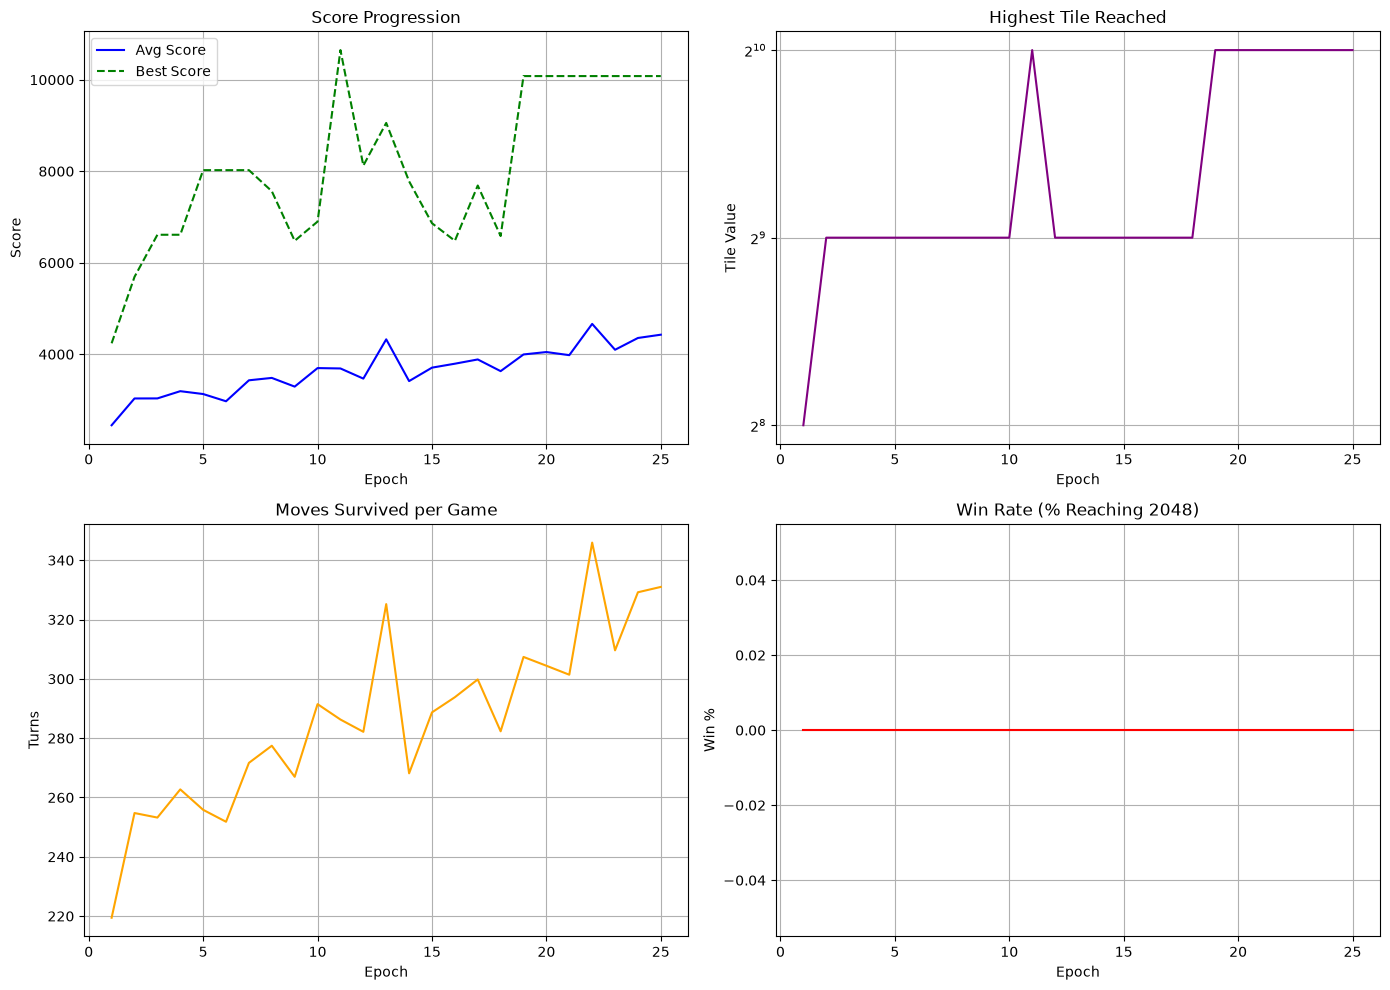

In [64]:
plot(history)

## Speeding up everything

In [50]:
# precomputing all table combinations assuming tile exponents from 0 to 14
ROW_TABLE = {}                                                                                                                   
                                                                                                                                     
for a in range(15):                                                                                                              
    for b in range(15):                                                                                                          
        for c in range(15):                                                                                                      
            for d in range(15):                                                                                                  
                # Filter out 0 (empty tile)                                                                                      
                row = [x for x in (a, b, c, d) if x != 0]                                                                        
                combined = []                                                                                                    
                score = 0                                                                                                        
                i = 0                                                                                                            
                while i < len(row):                                                                                              
                    if i + 1 < len(row) and row[i] == row[i + 1]:                                                                
                        new_val = row[i] + 1                                                                                     
                        combined.append(new_val)                                                                                 
                        score += (1 << new_val)                                                                                  
                        i += 2                                                                                                   
                    else:                                                                                                        
                        combined.append(row[i])                                                                                  
                        i += 1                                                                                                   
                # Pad remaining cells with 0                                                                                     
                combined += [0] * (4 - len(combined))                                                                            
                ROW_TABLE[(a, b, c, d)] = (tuple(combined), score)

In [51]:
# Fast move functions based on the pre computed boards
def move_board_left(b):                                                                                                          
    score = 0                                                                                                                    
    res = np.empty((4, 4), dtype=np.int32)                                                                                       
    for r in range(4):                                                                                                           
        new_r, s = ROW_TABLE[(b[r, 0], b[r, 1], b[r, 2], b[r, 3])]                                                               
        res[r, 0], res[r, 1], res[r, 2], res[r, 3] = new_r                                                                       
        score += s                                                                                                               
    return res, score                                                                                                            
                                                                                                                                    
def move_board_right(b):                                                                                                         
    score = 0                                                                                                                    
    res = np.empty((4, 4), dtype=np.int32)                                                                                       
    for r in range(4):                                                                                                           
        new_r, s = ROW_TABLE[(b[r, 3], b[r, 2], b[r, 1], b[r, 0])]                                                               
        res[r, 3], res[r, 2], res[r, 1], res[r, 0] = new_r                                                                       
        score += s                                                                                                               
    return res, score                                                                                                            
                                                                                                                                    
def move_board_up(b):                                                                                                            
    score = 0                                                                                                                    
    res = np.empty((4, 4), dtype=np.int32)                                                                                       
    for c in range(4):                                                                                                           
        new_c, s = ROW_TABLE[(b[0, c], b[1, c], b[2, c], b[3, c])]                                                               
        res[0, c], res[1, c], res[2, c], res[3, c] = new_c                                                                       
        score += s                                                                                                               
    return res, score                                                                                                            
                                                                                                                                    
def move_board_down(b):                                                                                                          
    score = 0                                                                                                                    
    res = np.empty((4, 4), dtype=np.int32)                                                                                       
    for c in range(4):                                                                                                           
        new_c, s = ROW_TABLE[(b[3, c], b[2, c], b[1, c], b[0, c])]                                                               
        res[3, c], res[2, c], res[1, c], res[0, c] = new_c                                                                       
        score += s                                                                                                               
    return res, score                                                                                                            
                                                                                                                                    
move_funcs = {                                                                                                                   
    'move_up': move_board_up,                                                                                                         
    'move_down': move_board_down,                                                                                                     
    'move_left': move_board_left,                                                                                                     
    'move_right': move_board_right                                                                                                    
}

In [52]:
def spawn_tile(board):                                                                                                           
    empty = np.flatnonzero(board == 0)                                                                                           
    if len(empty) == 0:                                                                                                          
        return board                                                                                                             
    idx = empty[np.random.randint(len(empty))]                                                                                   
    # Spawns exponent 1 (val 2) with 90% probability, or exponent 2 (val 4) with 10%                                             
    board.flat[idx] = 1 if np.random.rand() < 0.9 else 2                                                                         
    return board                                                                                                                 
                                                                                                                                    
def generate_board():                                                                                                            
    board = np.zeros((4, 4), dtype=np.int32)                                                                                     
    return spawn_tile(spawn_tile(board))                                                                                         
                                                                                                                                    
def show_board(board):                                                                                                           
    for row in board:                                                                                                            
        for tile in row:                                                                                                         
            if tile == 0:                                                                                                        
                print('_', end=' ')                                                                                              
            else:                                                                                                                
                print(1 << tile, end=' ')                                                                                        
        print()                                                                                                                  
    print()

# fast cloning
def clone_model(model, init_func=initialize_model):
    new_model = init_func()
    for p_new, p_orig in zip(new_model.parameters(), model.parameters()):
        p_new.data.copy_(p_orig.data)
    return new_model

In [53]:
def analyze_model_strategy(model, num_test_games=5):                                                                             
    """                                                                                                                          
    Analyzes whether the model learned specific strategies (e.g. corner trapping).                                               
    """                                                                                                                          
    move_counts = {'up': 0, 'down': 0, 'left': 0, 'right': 0}                                                                    
    corner_retention = []                                                                                                        
                                                                                                                                    
    for game_num in range(1, num_test_games + 1):
        board = generate_board()
        turns = 0
        
        while turns < 5000:
            d, _, next_b = request_model_move(board, model)

            if game_num == 1:
                print(d) 
                show_board(board)

            if next_b is None:
                break
            move_counts[d] += 1
            board = spawn_tile(next_b)
            turns += 1
            
            # Check if largest tile is in one of the 4 corners
            max_val = np.max(board)
            corners = [board[0, 0], board[0, 3], board[3, 0], board[3, 3]]
            corner_retention.append(max_val in corners)
            
        print(f"Game {game_num} Finished -> Max Tile: {1 << np.max(board)} | Moves: {turns}")
        
    total_moves = sum(move_counts.values())
    print("\n--- Move Distribution Analysis ---")
    for move, count in move_counts.items():
        print(f"  • {move.upper():5s}: {count:5d} ({count / total_moves * 100:.1f}%)")
        
    corner_pct = sum(corner_retention) / len(corner_retention) * 100
    print(f"\nCorner Retention: Highest tile was in a corner {corner_pct:.1f}% of the time.")
    if corner_pct > 75:
        print("The model has learned the classic 2048 Corner Strategy!")   

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
  32    |   0.0%    |   3376.4   |  3252.0   |    5036    |   949.0    |    512    |   274.5  
  28    |   0.0%    |   3372.0   |  2670.0   |    7728    |   1900.3   |    512    |   273.0  
  27    |   0.0%    |   3337.2   |  3354.0   |    7108    |   2088.9   |    512    |   272.8  
   3    |   0.0%    |   3229.6   |  2610.0   |    6468    |   2103.4   |    512    |   260.8  
  33    |   0.0%    |   3228.4   |  2922.0   |    7956    |   1946.7   |    512    |   269.5  
  36    |   0.0%    |   2961.2   |  2868.0   |    7212    |   1733.6   |    512    |   247.1  
  12    |   0.0%    |   2846.4   |  2686.0   |    6160    |   1305.8   |    512    |   239.9  
  23    |   0.0%    |   2534.4   |  2104.0   |    5156    |   1299.2   |    512   

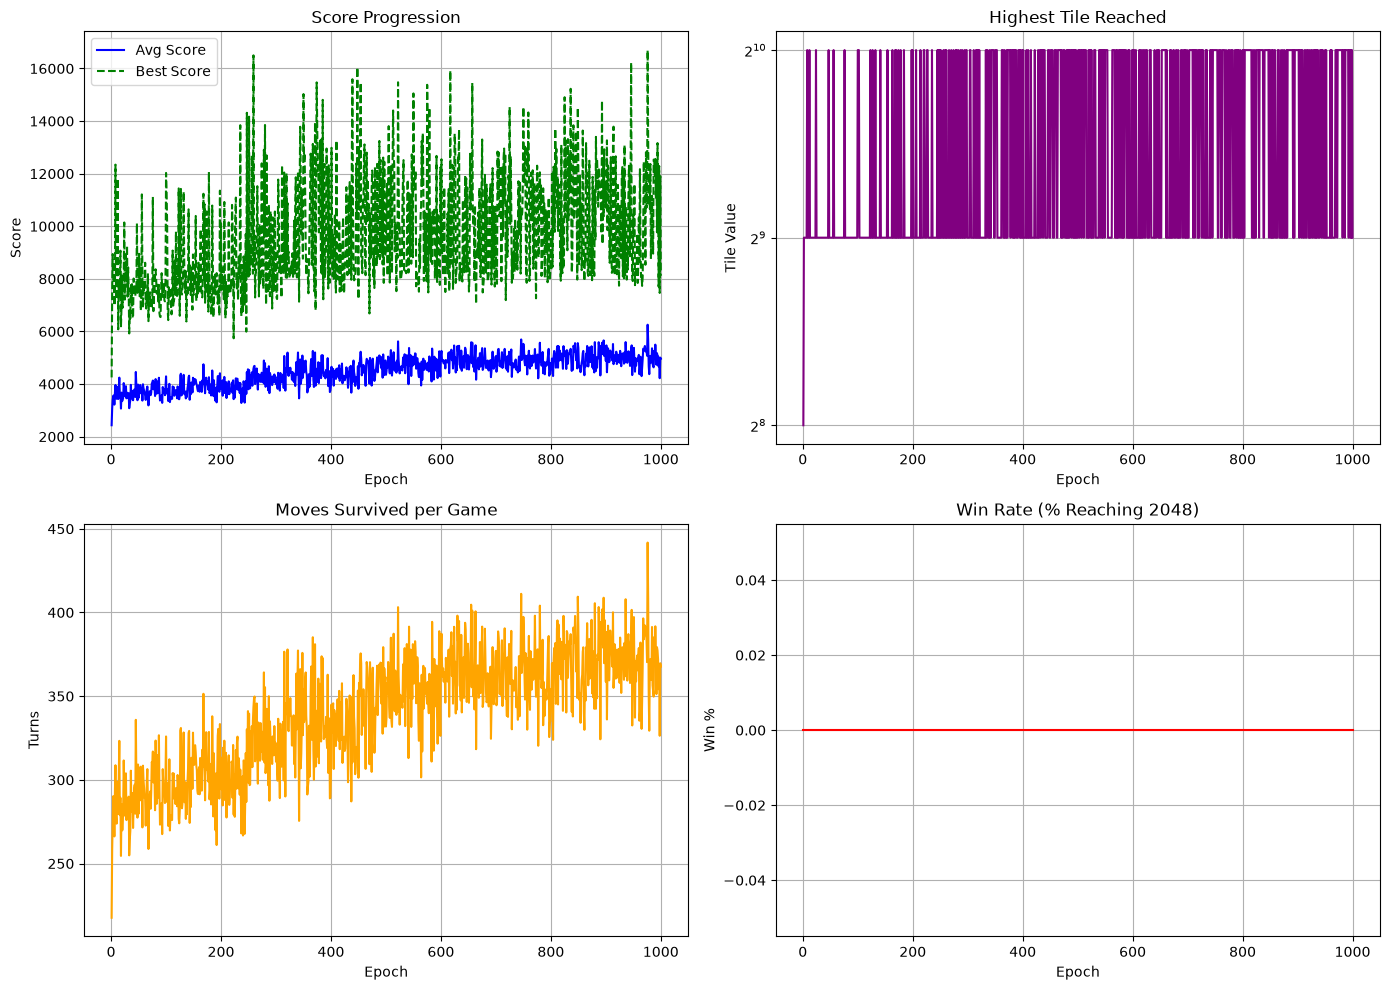

Analyzing best model out of all:
_ _ 2 _ 
4 _ _ _ 
_ _ _ _ 
_ _ _ _ 



ValueError: too many values to unpack (expected 2)

In [97]:
history, parent_history, elite_history, top_3_models = train()

print('Plotting graph:')
plot(history)

print('='*115)
print('Analyzing best model out of all:')
champion = top_3_models[0]['model']
analyze_model_strategy(champion)

In [101]:
analyze_model_strategy(champion)

left
_ 2 _ _ 
2 _ _ _ 
_ _ _ _ 
_ _ _ _ 

down
2 _ _ _ 
2 _ _ _ 
_ _ _ _ 
2 _ _ _ 

left
_ _ _ _ 
_ _ _ _ 
2 2 _ _ 
4 _ _ _ 

left
_ 2 _ _ 
_ _ _ _ 
4 _ _ _ 
4 _ _ _ 

left
2 _ _ _ 
_ 2 _ _ 
4 _ _ _ 
4 _ _ _ 

left
2 2 _ _ 
2 _ _ _ 
4 _ _ _ 
4 _ _ _ 

down
4 _ _ _ 
2 _ _ _ 
4 _ _ 2 
4 _ _ _ 

down
_ _ _ _ 
4 _ _ _ 
2 _ _ 2 
8 _ _ 2 

left
_ _ _ _ 
4 2 _ _ 
2 _ _ _ 
8 _ _ 4 

down
_ _ _ _ 
4 2 _ _ 
2 4 _ _ 
8 4 _ _ 

left
_ _ _ _ 
4 _ _ _ 
2 2 2 _ 
8 8 _ _ 

left
_ _ 2 _ 
4 _ _ _ 
4 2 _ _ 
16 _ _ _ 

left
2 2 _ _ 
4 _ _ _ 
4 2 _ _ 
16 _ _ _ 

down
4 _ _ _ 
4 _ _ _ 
4 2 _ _ 
16 2 _ _ 

down
_ _ _ _ 
4 2 _ _ 
8 _ _ _ 
16 4 _ _ 

left
_ _ _ _ 
4 _ _ _ 
8 2 _ _ 
16 4 4 _ 

left
_ _ _ _ 
4 _ _ _ 
8 2 2 _ 
16 8 _ _ 

down
_ _ _ _ 
4 _ _ _ 
8 4 2 _ 
16 8 _ _ 

left
_ _ _ _ 
4 _ 2 _ 
8 4 _ _ 
16 8 2 _ 

up
_ _ _ _ 
4 2 _ _ 
8 4 _ _ 
16 8 2 4 

left
4 2 2 4 
8 4 _ _ 
16 8 _ _ 
_ _ _ 2 

left
4 4 4 2 
8 4 _ _ 
16 8 _ _ 
2 _ _ _ 

left
8 4 2 _ 
8 4 _ _ 
16 8 _ _ 
2 _ 2 _ 

down
8 4 2 _ 
8 4 _ _ 
1

Clearly the models are getting their scores out of luck

## Making the model wider

16 -> 32 -> 4

In [54]:
def initialize_model_2():
    return nn.Sequential(
        nn.Linear(in_features=16, out_features=32),
        nn.Tanh(),
        nn.Linear(in_features=32, out_features=4)
    )

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
   4    |   0.0%    |   4102.4   |  3008.0   |   10132    |   3130.6   |   1024    |   297.8  
  20    |   0.0%    |   3566.8   |  3530.0   |    6820    |   1716.2   |    512    |   282.4  
  39    |   0.0%    |   3511.2   |  3150.0   |    6624    |   1949.9   |    512    |   279.8  
  15    |   0.0%    |   3510.0   |  3428.0   |    6772    |   1493.8   |    512    |   283.9  
  17    |   0.0%    |   3254.8   |  3166.0   |    6204    |   1760.2   |    512    |   261.4  
   6    |   0.0%    |   3109.2   |  2306.0   |    6628    |   1968.4   |    512    |   255.3  
   3    |   0.0%    |   3108.4   |  2986.0   |    6984    |   1906.1   |    512    |   257.3  
  14    |   0.0%    |   3048.0   |  2764.0   |    7452    |   1773.9   |    512   

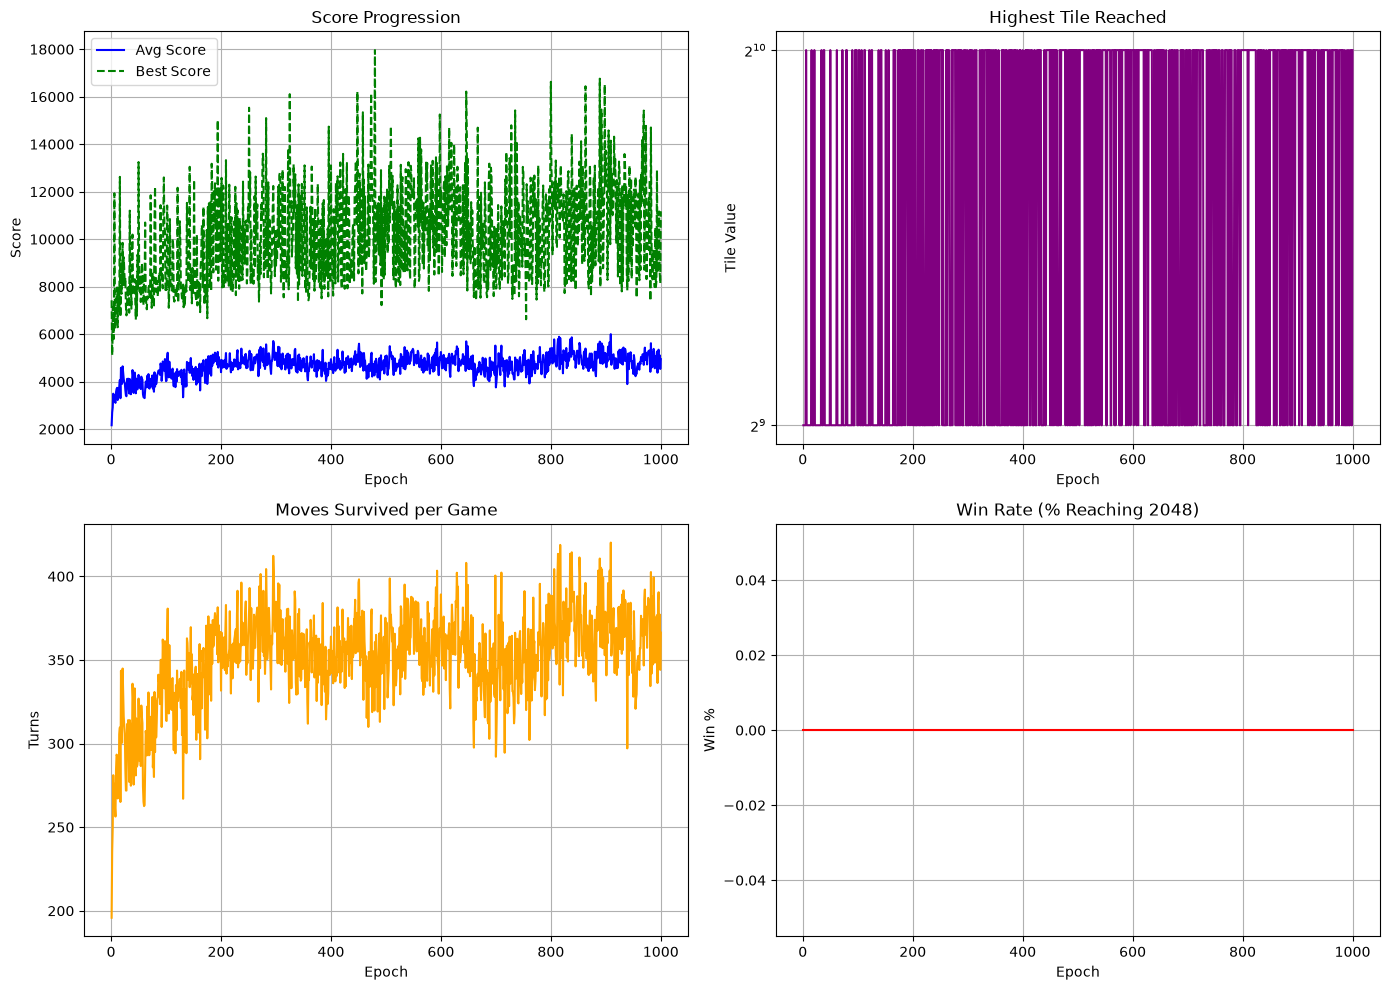

In [110]:
history, parent_history, elite_history, top_3_models = train(initialize_model_2)
plot(history)

In [114]:
champion = top_3_models[1]['model']
analyze_model_strategy(champion)

down
_ 2 _ 2 
_ _ _ _ 
_ _ _ _ 
_ _ _ _ 

down
_ _ _ _ 
_ _ _ 2 
_ _ _ _ 
_ 2 _ 2 

down
_ _ _ _ 
_ _ _ _ 
_ _ 2 _ 
_ 2 _ 4 

down
_ 4 _ _ 
_ _ _ _ 
_ _ _ _ 
_ 2 2 4 

down
_ _ _ _ 
_ 4 _ _ 
_ 4 _ _ 
_ 2 2 4 

right
_ _ _ _ 
_ _ _ _ 
_ 8 _ 2 
_ 2 2 4 

left
_ _ _ _ 
_ _ 4 _ 
_ _ 8 2 
_ _ 4 4 

left
_ _ _ _ 
4 _ _ _ 
8 2 _ 2 
8 _ _ _ 

right
_ _ _ _ 
4 _ _ _ 
8 4 2 _ 
8 _ _ _ 

down
_ _ _ _ 
_ _ _ 4 
_ 8 4 2 
2 _ _ 8 

down
_ _ 2 _ 
_ _ _ 4 
_ _ _ 2 
2 8 4 8 

down
_ _ _ _ 
_ 2 _ 4 
_ _ 2 2 
2 8 4 8 

down
_ _ _ _ 
_ _ _ 4 
2 2 2 2 
2 8 4 8 

right
_ _ _ 2 
_ _ _ 4 
_ 2 2 2 
4 8 4 8 

down
_ _ _ 2 
_ _ _ 4 
_ 2 2 4 
4 8 4 8 

down
_ _ _ _ 
_ _ 2 2 
_ 2 2 8 
4 8 4 8 

down
_ _ _ _ 
_ _ 2 _ 
_ 2 4 2 
4 8 4 16 

down
_ _ _ _ 
2 _ _ _ 
_ 2 2 2 
4 8 8 16 

down
_ _ 2 _ 
_ _ _ _ 
2 2 2 2 
4 8 8 16 

down
_ _ _ _ 
2 _ _ _ 
2 2 4 2 
4 8 8 16 

down
_ _ _ _ 
_ 2 _ _ 
4 2 4 2 
4 8 8 16 

right
_ _ _ _ 
_ _ 2 _ 
_ 4 4 2 
8 8 8 16 

down
_ 2 _ _ 
_ _ _ 2 
_ _ 8 2 
_ 8 16 16 

right
_ _ _ _ 
_ _ _ 2

## Adding another hidden layer as 1 layer is not enough to hold this capacity

16 -> 16 -> 8 -> 4

In [55]:
def initialize_model_3():
    return nn.Sequential(
        nn.Linear(in_features=16, out_features=16),
        nn.Tanh(),
        nn.Linear(in_features=16, out_features=8),
        nn.Tanh(),
        nn.Linear(in_features=8, out_features=4)
    )

In [116]:
history, parent_history, elite_history, top_3_models = train(initialize_model_2)
plot(history)

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
   7    |   0.0%    |   3075.6   |  2676.0   |    5236    |   1114.6   |    512    |   257.7  
   5    |   0.0%    |   2460.8   |  2174.0   |    5512    |   1192.8   |    512    |   216.9  
  16    |   0.0%    |   2341.2   |  1576.0   |    6568    |   1735.0   |    512    |   209.0  
  31    |   0.0%    |   2648.0   |  2534.0   |    4312    |   1151.2   |    256    |   237.1  
  24    |   0.0%    |   2616.0   |  2272.0   |    4308    |   1136.9   |    256    |   233.4  
  36    |   0.0%    |   2592.4   |  2568.0   |    4100    |   836.9    |    256    |   230.7  
   8    |   0.0%    |   2467.6   |  2548.0   |    4260    |   1016.5   |    256    |   223.6  
  39    |   0.0%    |   2139.6   |  2002.0   |    4228    |   1001.4   |    256   

KeyboardInterrupt: 

## Normalizing the inputs of the board for better output

In [56]:
TOTAL_GENS = 300

### 16 -> 8 -> 4

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
  39    |   0.0%    |   4286.4   |  3390.0   |   11240    |   3067.5   |   1024    |   323.1  
  38    |   0.0%    |   4711.6   |  4734.0   |    7688    |   1602.7   |    512    |   352.4  
  12    |   0.0%    |   3962.0   |  4140.0   |    6420    |   1920.0   |    512    |   300.2  
  28    |   0.0%    |   3933.6   |  3656.0   |    6664    |   1694.1   |    512    |   304.4  
  14    |   0.0%    |   3680.4   |  3478.0   |    6448    |   1211.7   |    512    |   293.7  
  23    |   0.0%    |   3649.2   |  2768.0   |    7092    |   2332.5   |    512    |   286.7  
  10    |   0.0%    |   3205.6   |  2202.0   |    7800    |   2247.5   |    512    |   264.1  
  21    |   0.0%    |   3168.4   |  3168.0   |    5408    |   1267.4   |    512   

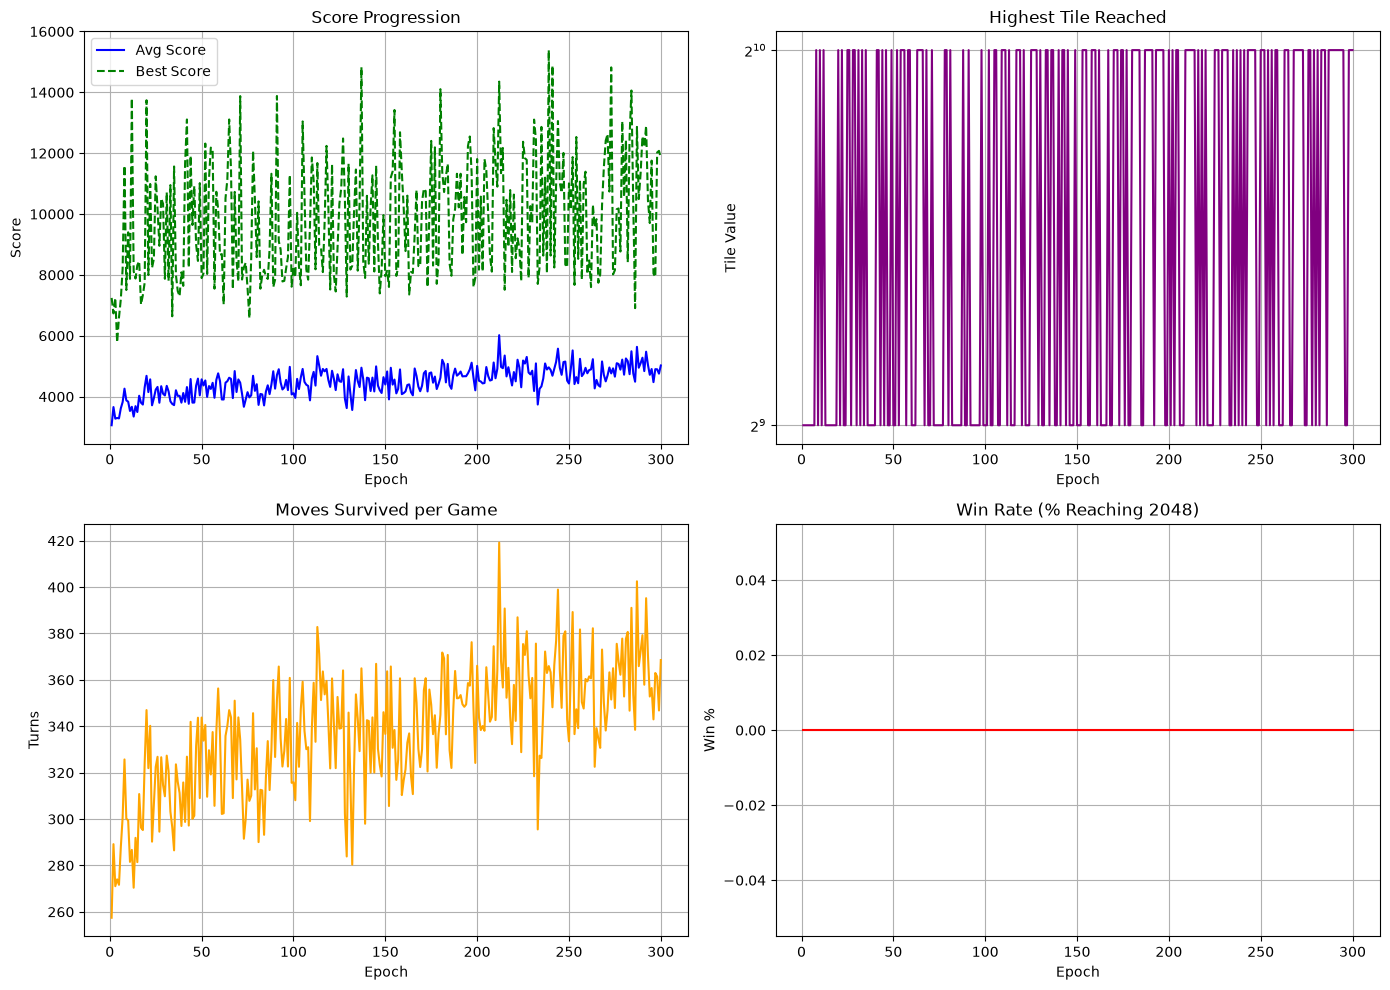

In [136]:
history, _, _, _ = train()
plot(history)

### 16 -> 32 -> 4

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
  39    |   0.0%    |   3573.6   |  3164.0   |    7388    |   1470.0   |    512    |   286.5  
  38    |   0.0%    |   3301.2   |  2926.0   |    6568    |   1612.0   |    512    |   267.6  
   6    |   0.0%    |   3110.8   |  3120.0   |    6200    |   1674.4   |    512    |   255.5  
  20    |   0.0%    |   3106.4   |  3032.0   |    7184    |   1507.8   |    512    |   258.9  
  33    |   0.0%    |   3066.0   |  2812.0   |    7148    |   1564.4   |    512    |   259.8  
  21    |   0.0%    |   3017.2   |  2388.0   |    6736    |   2153.6   |    512    |   246.2  
  12    |   0.0%    |   2792.0   |  2806.0   |    5620    |   1260.9   |    512    |   241.2  
   3    |   0.0%    |   2643.6   |  2446.0   |    5828    |   1175.6   |    512   

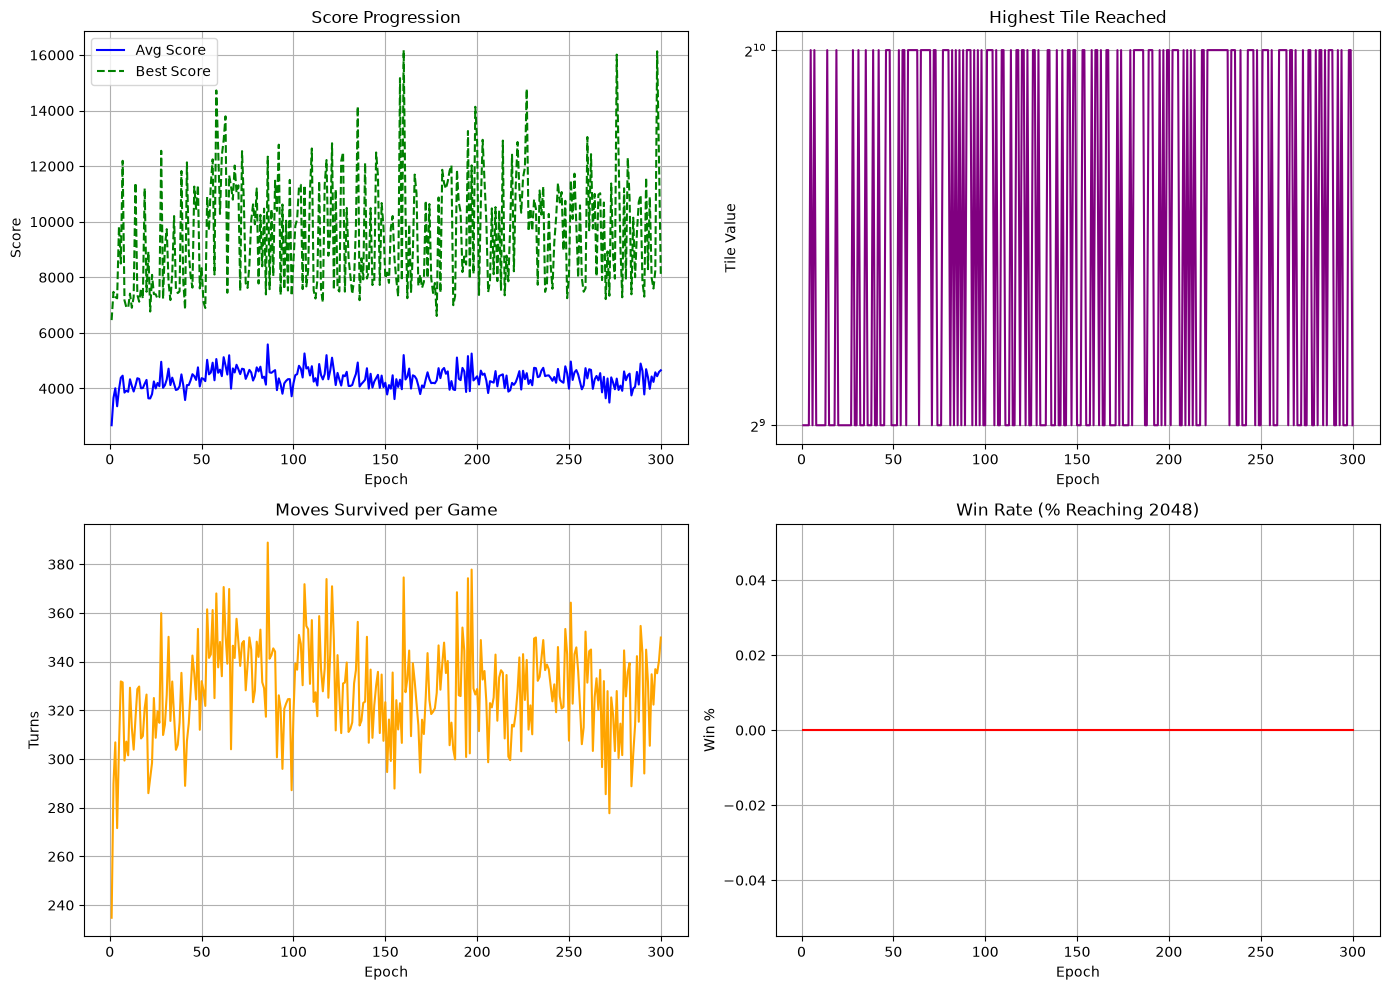

In [137]:
# doing the same for model 2
history, _, _, _ = train(initialize_model_2)
plot(history)

### 16 -> 16 -> 8 -> 4

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
  34    |   0.0%    |   5382.4   |  4790.0   |   12084    |   3236.1   |   1024    |   385.0  
  20    |   0.0%    |   4478.0   |  3910.0   |    8140    |   1915.4   |    512    |   341.1  
  35    |   0.0%    |   4224.4   |  3700.0   |    7276    |   1548.6   |    512    |   325.6  
  27    |   0.0%    |   4173.6   |  3576.0   |    7384    |   1352.2   |    512    |   325.2  
  10    |   0.0%    |   3808.8   |  3880.0   |    6744    |   1635.8   |    512    |   291.8  
  14    |   0.0%    |   3622.4   |  2996.0   |    7428    |   1797.6   |    512    |   284.9  
  11    |   0.0%    |   3576.4   |  2980.0   |    7900    |   1690.5   |    512    |   283.9  
  13    |   0.0%    |   3459.6   |  3586.0   |    5324    |   954.2    |    512   

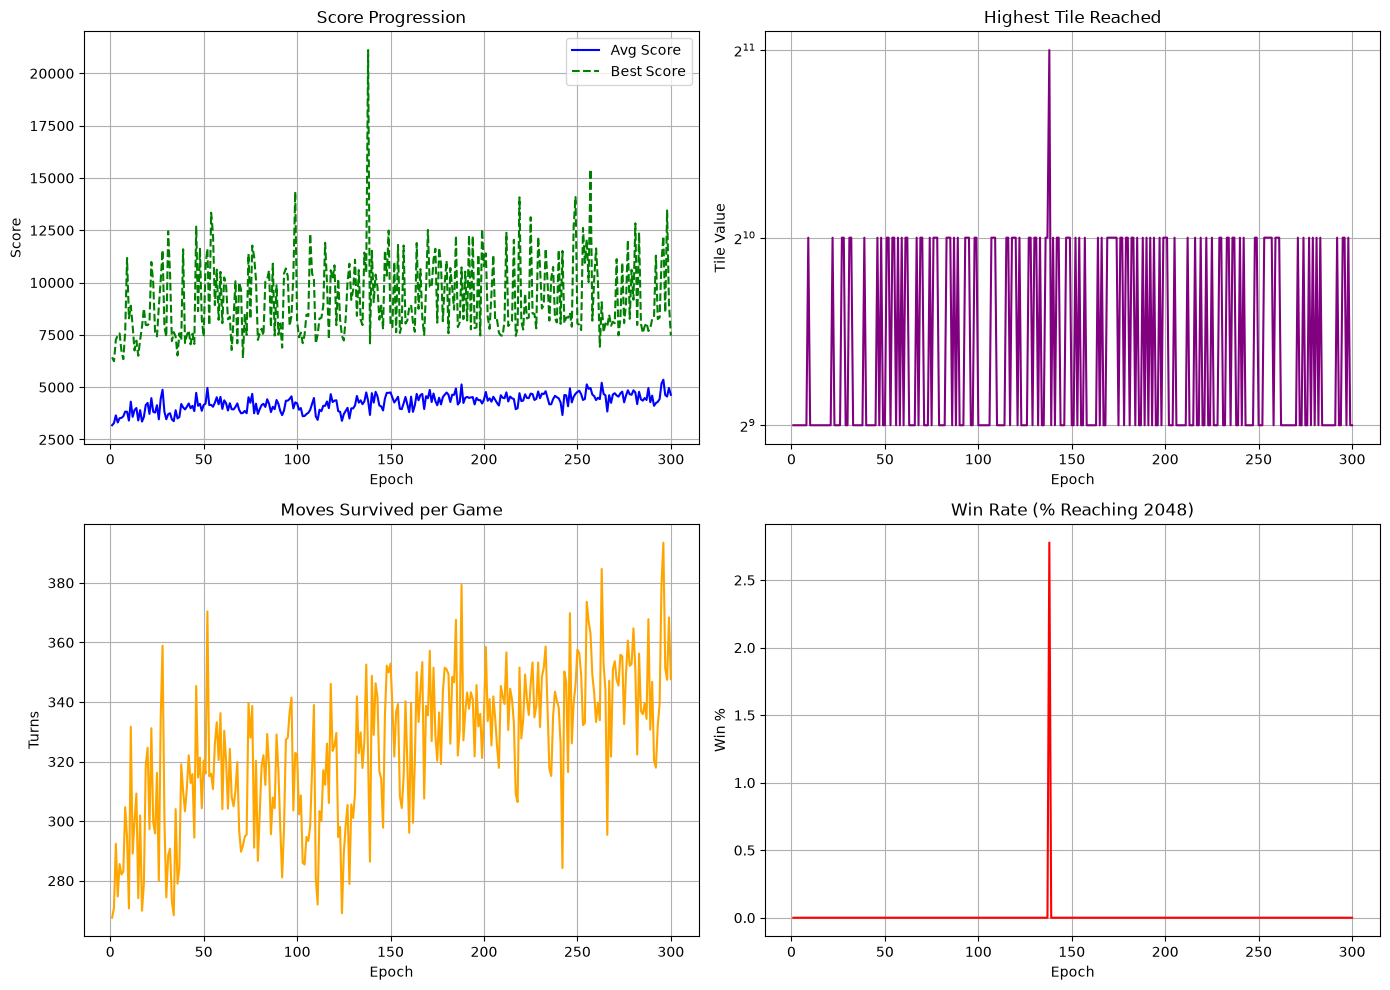

In [138]:
# doing the same for model 3
history, _, _, _ = train(initialize_model_3)
plot(history)

### 16 -> 64 -> 32 -> 4

In [57]:
def initialize_model_4():
    return nn.Sequential(
        nn.Linear(in_features=16, out_features=64),
        nn.Tanh(),
        nn.Linear(in_features=64, out_features=32),
        nn.Tanh(),
        nn.Linear(in_features=32, out_features=4),
    )

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
  11    |   0.0%    |   3492.4   |  3380.0   |    6748    |   1419.4   |    512    |   281.3  
   1    |   0.0%    |   3252.8   |  3328.0   |    6508    |   1576.2   |    512    |   265.7  
  24    |   0.0%    |   3162.4   |  2702.0   |    6920    |   1913.0   |    512    |   260.5  
  35    |   0.0%    |   2946.4   |  3032.0   |    5640    |   1372.3   |    512    |   253.1  
  10    |   0.0%    |   2914.8   |  2840.0   |    6384    |   1389.4   |    512    |   246.2  
   7    |   0.0%    |   2853.2   |  2494.0   |    7540    |   1765.3   |    512    |   241.1  
  21    |   0.0%    |   2742.4   |  2348.0   |    5756    |   1347.3   |    512    |   236.9  
   9    |   0.0%    |   2620.0   |  2046.0   |    6256    |   1530.9   |    512   

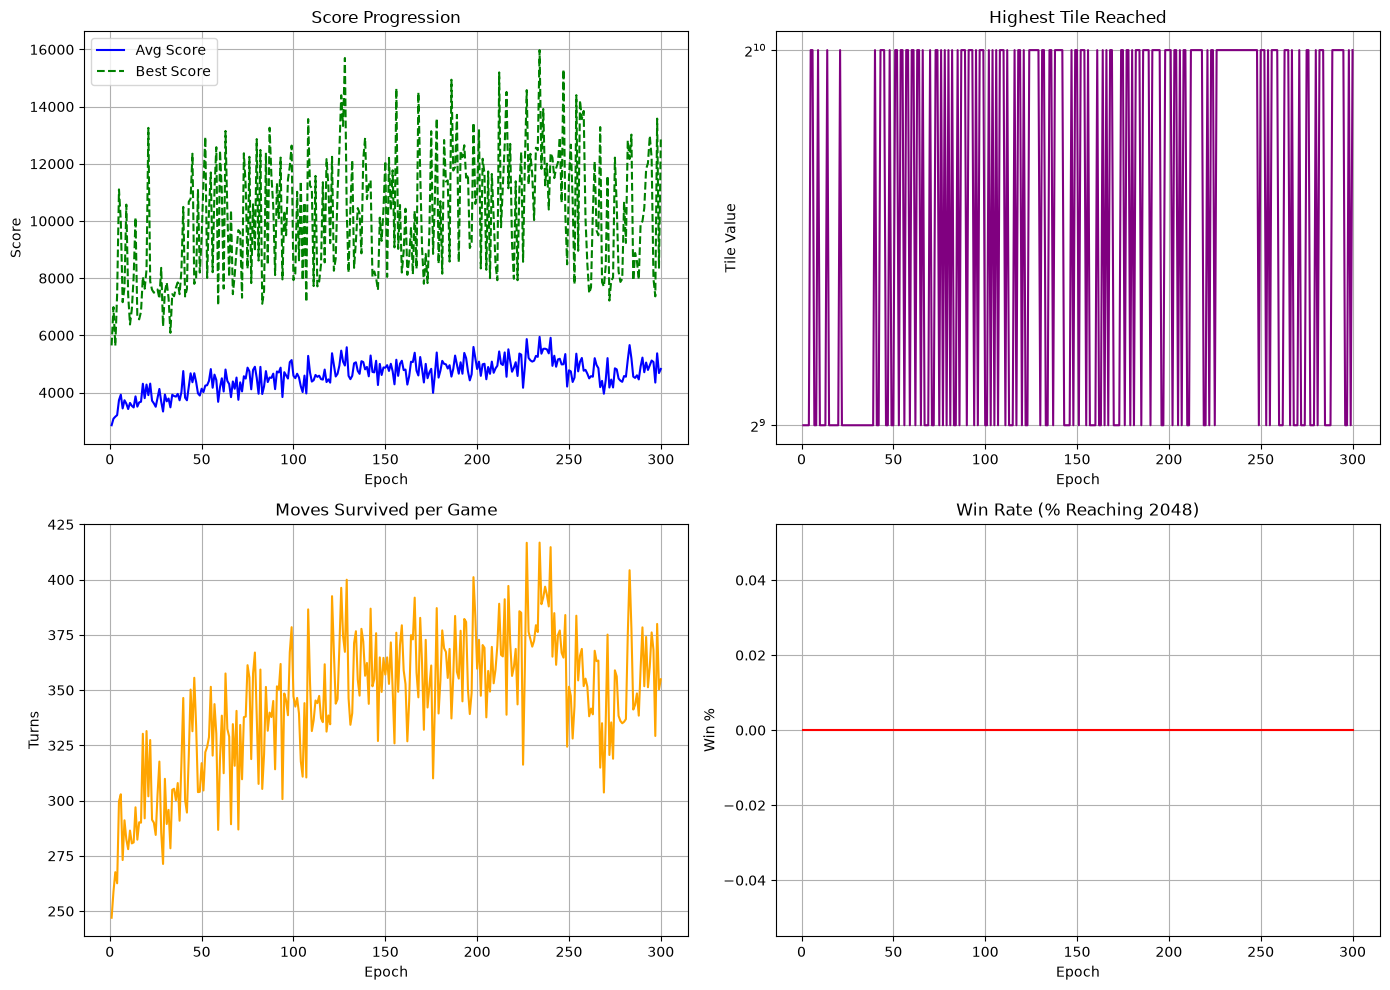

In [143]:
history, _, _, _ = train(initialize_model_4)
plot(history)

### 16 -> 64 -> 32 -> 16 -> 4

In [58]:
def initialize_model_5():
    return nn.Sequential(
        nn.Linear(in_features=16, out_features=64),
        nn.Tanh(),
        nn.Linear(in_features=64, out_features=32),
        nn.Tanh(),
        nn.Linear(in_features=32, out_features=16),
        nn.Tanh(),
        nn.Linear(in_features=16, out_features=4),
    )

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
  39    |   0.0%    |   3953.6   |  3346.0   |    8492    |   2193.8   |    512    |   315.0  
   3    |   0.0%    |   3800.0   |  3228.0   |    7440    |   2053.3   |    512    |   299.8  
   1    |   0.0%    |   3720.4   |  3322.0   |    7308    |   1847.6   |    512    |   286.6  
  13    |   0.0%    |   3575.6   |  2806.0   |    5992    |   1588.9   |    512    |   287.8  
  18    |   0.0%    |   3534.0   |  3614.0   |    5160    |   1051.4   |    512    |   288.3  
   2    |   0.0%    |   3492.8   |  3398.0   |    5692    |   1114.0   |    512    |   284.6  
  15    |   0.0%    |   3285.2   |  2842.0   |    7204    |   1953.4   |    512    |   270.1  
  33    |   0.0%    |   3203.2   |  2806.0   |    5980    |   1313.8   |    512   

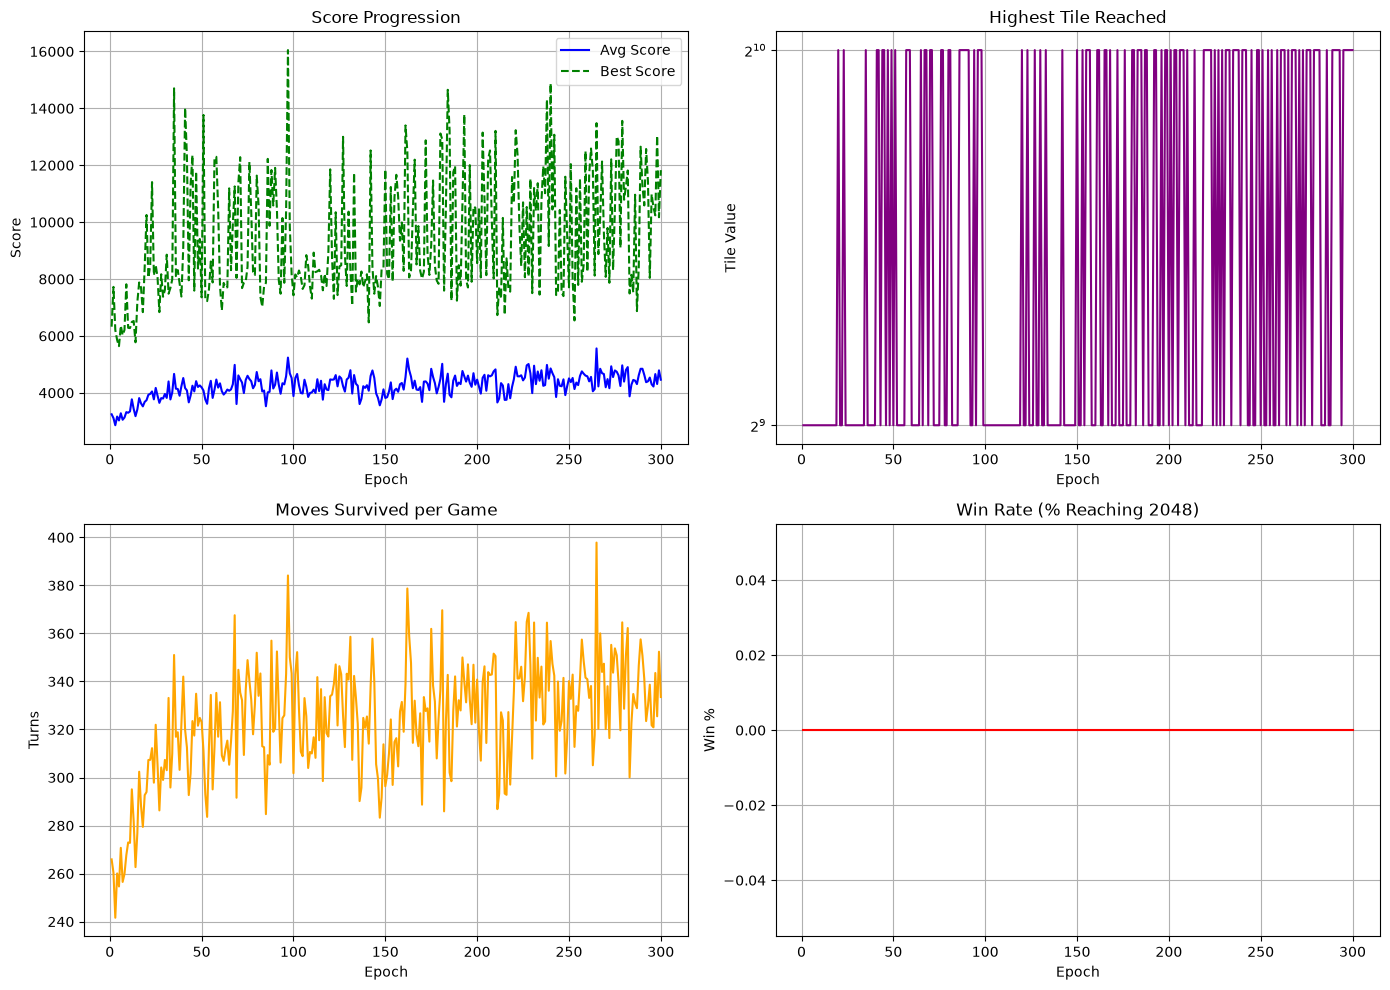

In [150]:
history, _, _, _ = train(initialize_model_5)
plot(history)

### 16 -> 64 -> 128 -> 64 -> 4

In [59]:
def initialize_model_6():
    return nn.Sequential(
        nn.Linear(in_features=16, out_features=64),
        nn.Tanh(),
        nn.Linear(in_features=64, out_features=128),
        nn.Tanh(),
        nn.Linear(in_features=128, out_features=64),
        nn.Tanh(),
        nn.Linear(in_features=64, out_features=4),
    )

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
  20    |   0.0%    |   3899.6   |  3646.0   |    7884    |   2182.8   |    512    |   312.4  
  23    |   0.0%    |   3652.4   |  3628.0   |    5600    |   789.7    |    512    |   298.4  
  30    |   0.0%    |   3169.6   |  3630.0   |    5448    |   1494.1   |    512    |   253.0  
   2    |   0.0%    |   3033.2   |  2454.0   |    7024    |   1722.6   |    512    |   257.0  
   6    |   0.0%    |   2974.8   |  2718.0   |    5732    |   1315.4   |    512    |   248.2  
   7    |   0.0%    |   2498.0   |  1726.0   |    5460    |   1454.2   |    512    |   222.9  
  33    |   0.0%    |   2422.4   |  2092.0   |    5136    |   1430.3   |    512    |   211.7  
   3    |   0.0%    |   2093.2   |  1626.0   |    5172    |   1250.8   |    512   

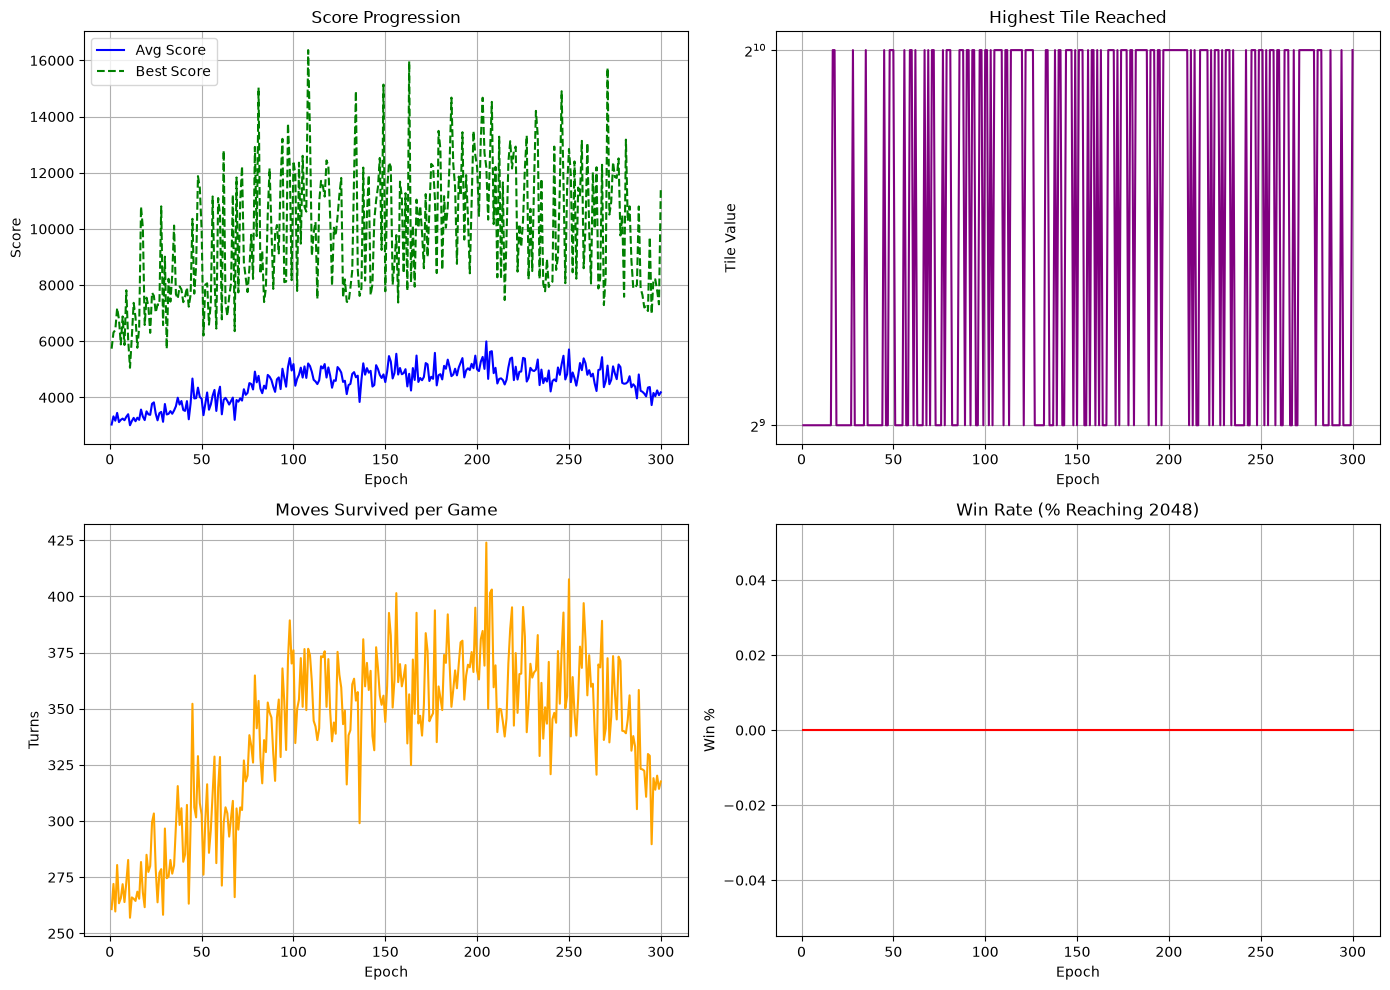

In [152]:
history, _, _, _ = train(initialize_model_6)
plot(history)

## Changing the activation function for improvements

16 -> 16 -> 8 -> 4

Same size but activation in hidden layers is Leaky Relu

### Model 1: (16 -> 16 -> 8 -> 4)

In [60]:
def initialize_leakyrelu_model():
    return nn.Sequential(
        nn.Linear(in_features=16, out_features=16),
        nn.LeakyReLU(),
        nn.Linear(in_features=16, out_features=8),
        nn.LeakyReLU(),
        nn.Linear(in_features=8, out_features=4),
    )

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
  18    |   0.0%    |   4521.2   |  5236.0   |    6284    |   1394.4   |    512    |   337.2  
  20    |   0.0%    |   3700.0   |  3612.0   |    6328    |   1485.3   |    512    |   296.4  
  19    |   0.0%    |   3499.2   |  2990.0   |    6924    |   1968.2   |    512    |   280.4  
  15    |   0.0%    |   3399.2   |  3012.0   |    7552    |   1884.7   |    512    |   277.7  
  17    |   0.0%    |   3110.8   |  3280.0   |    5548    |   1305.3   |    512    |   260.5  
  28    |   0.0%    |   3066.4   |  3196.0   |    5172    |   1147.9   |    512    |   253.3  
  35    |   0.0%    |   2920.4   |  2018.0   |    6880    |   1959.9   |    512    |   249.6  
   4    |   0.0%    |   2716.8   |  2360.0   |    6032    |   1385.8   |    512   

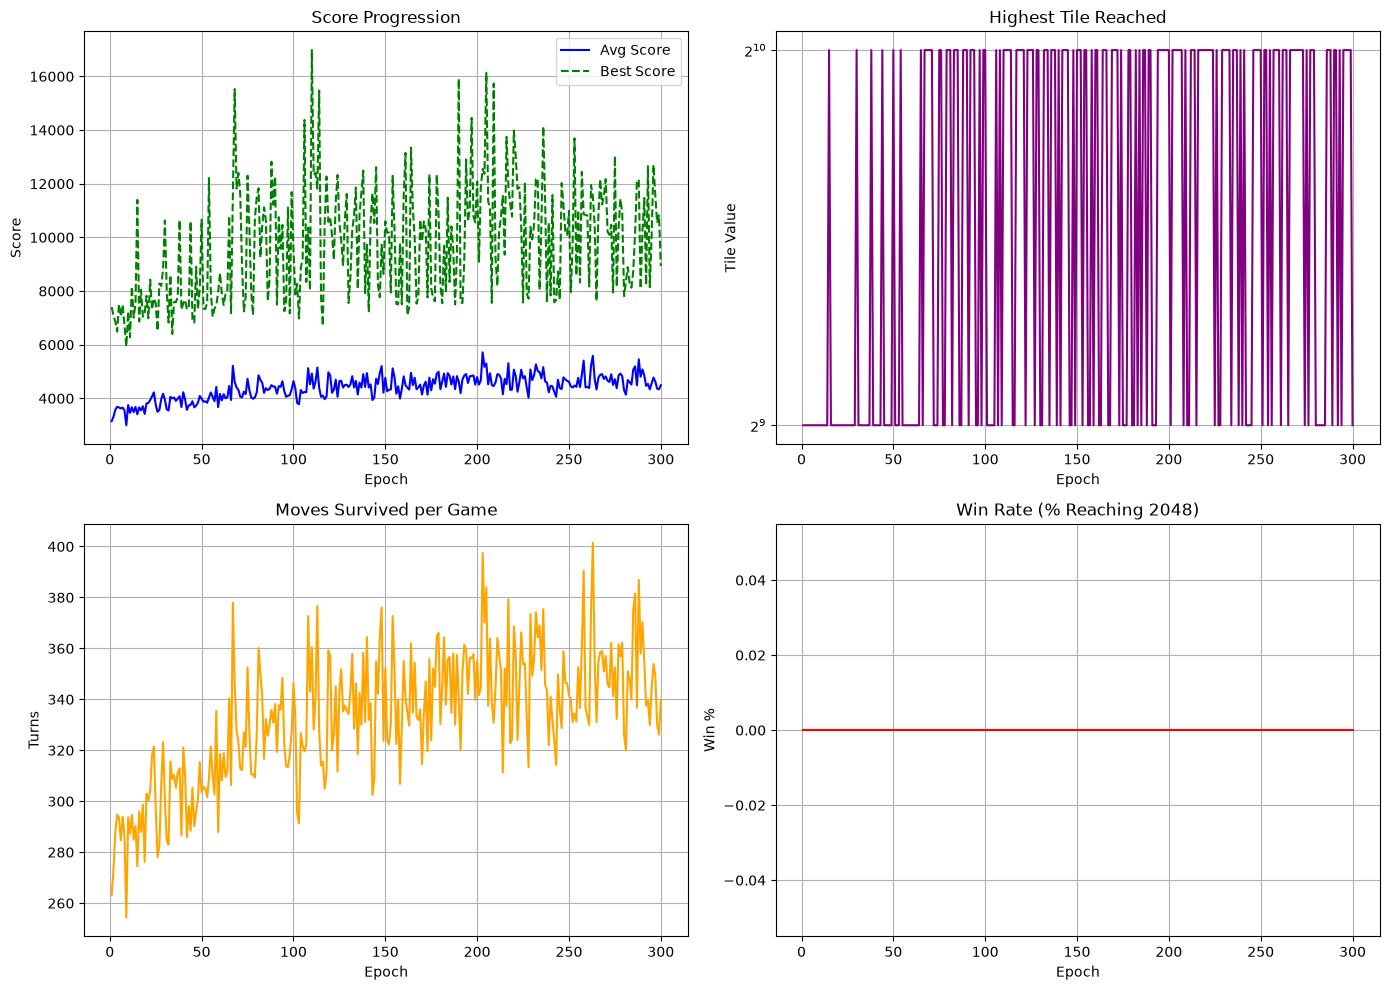

In [141]:
history, _, _, _ = train(initialize_leakyrelu_model)
plot(history)

### Model 2: (16 -> 64 -> 32 -> 4)

In [61]:
def initialize_leakyrelu_model_2():
    return nn.Sequential(
        nn.Linear(in_features=16, out_features=64),
        nn.LeakyReLU(),
        nn.Linear(in_features=64, out_features=32),
        nn.LeakyReLU(),
        nn.Linear(in_features=32, out_features=4),
    )

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
  15    |   0.0%    |   4368.8   |  4548.0   |    8252    |   2071.3   |    512    |   328.8  
  17    |   0.0%    |   4276.8   |  3902.0   |    8196    |   2350.9   |    512    |   324.6  
   0    |   0.0%    |   4098.4   |  4542.0   |    6508    |   1892.2   |    512    |   314.7  
  29    |   0.0%    |   3728.8   |  3280.0   |    7112    |   1991.7   |    512    |   290.2  
  31    |   0.0%    |   3631.6   |  2774.0   |    8952    |   2277.1   |    512    |   287.8  
   2    |   0.0%    |   3458.0   |  3428.0   |    7520    |   2014.3   |    512    |   274.5  
  23    |   0.0%    |   3242.8   |  3054.0   |    6172    |   1338.3   |    512    |   264.0  
   3    |   0.0%    |   3051.6   |  2196.0   |    6056    |   1983.2   |    512   

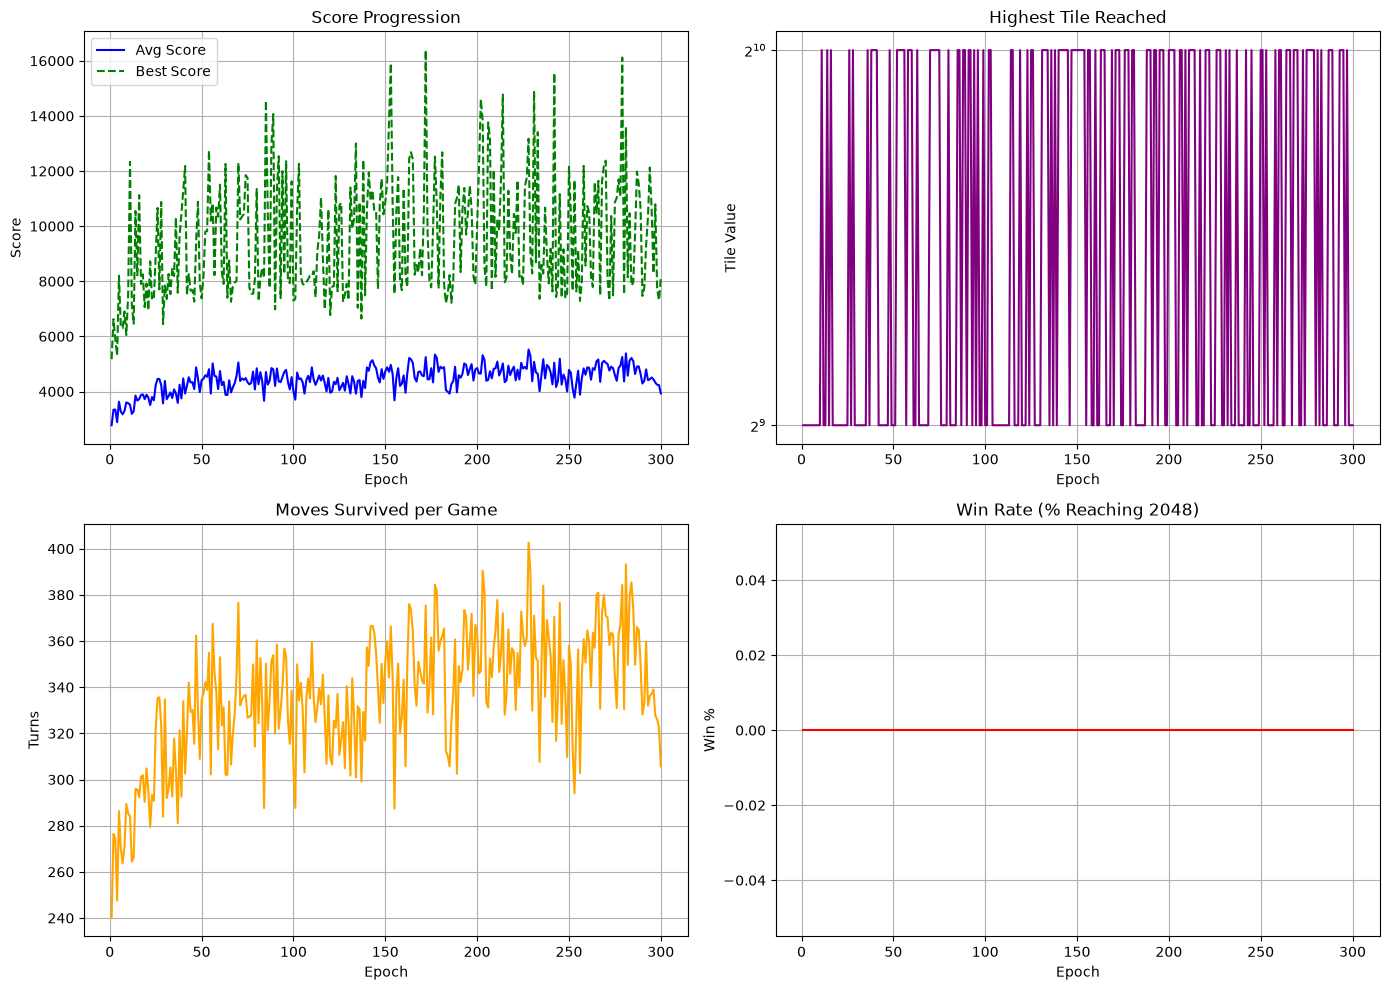

In [145]:
history, _, _, _ = train(initialize_leakyrelu_model_2)
plot(history)

### 16 -> 64 -> 32 -> 16 -> 4

In [62]:
def initialize_leakyrelu_model_3():
    return nn.Sequential(
        nn.Linear(in_features=16, out_features=64),
        nn.LeakyReLU(),
        nn.Linear(in_features=64, out_features=32),
        nn.LeakyReLU(),
        nn.Linear(in_features=32, out_features=16),
        nn.LeakyReLU(),
        nn.Linear(in_features=16, out_features=4),
    )

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
   5    |   0.0%    |   3861.6   |  3654.0   |    6196    |   1767.0   |    512    |   300.8  
  11    |   0.0%    |   3834.8   |  3420.0   |    6736    |   1424.8   |    512    |   303.8  
  12    |   0.0%    |   3676.0   |  3402.0   |    8028    |   1692.6   |    512    |   299.4  
  29    |   0.0%    |   3593.6   |  3298.0   |    6824    |   1572.6   |    512    |   283.8  
   4    |   0.0%    |   3369.6   |  2958.0   |    6420    |   1943.7   |    512    |   266.1  
  17    |   0.0%    |   3367.2   |  2118.0   |    7128    |   2097.3   |    512    |   266.4  
  37    |   0.0%    |   3356.0   |  3378.0   |    5000    |   1051.3   |    512    |   275.5  
  35    |   0.0%    |   3021.6   |  2584.0   |    6308    |   1665.0   |    512   

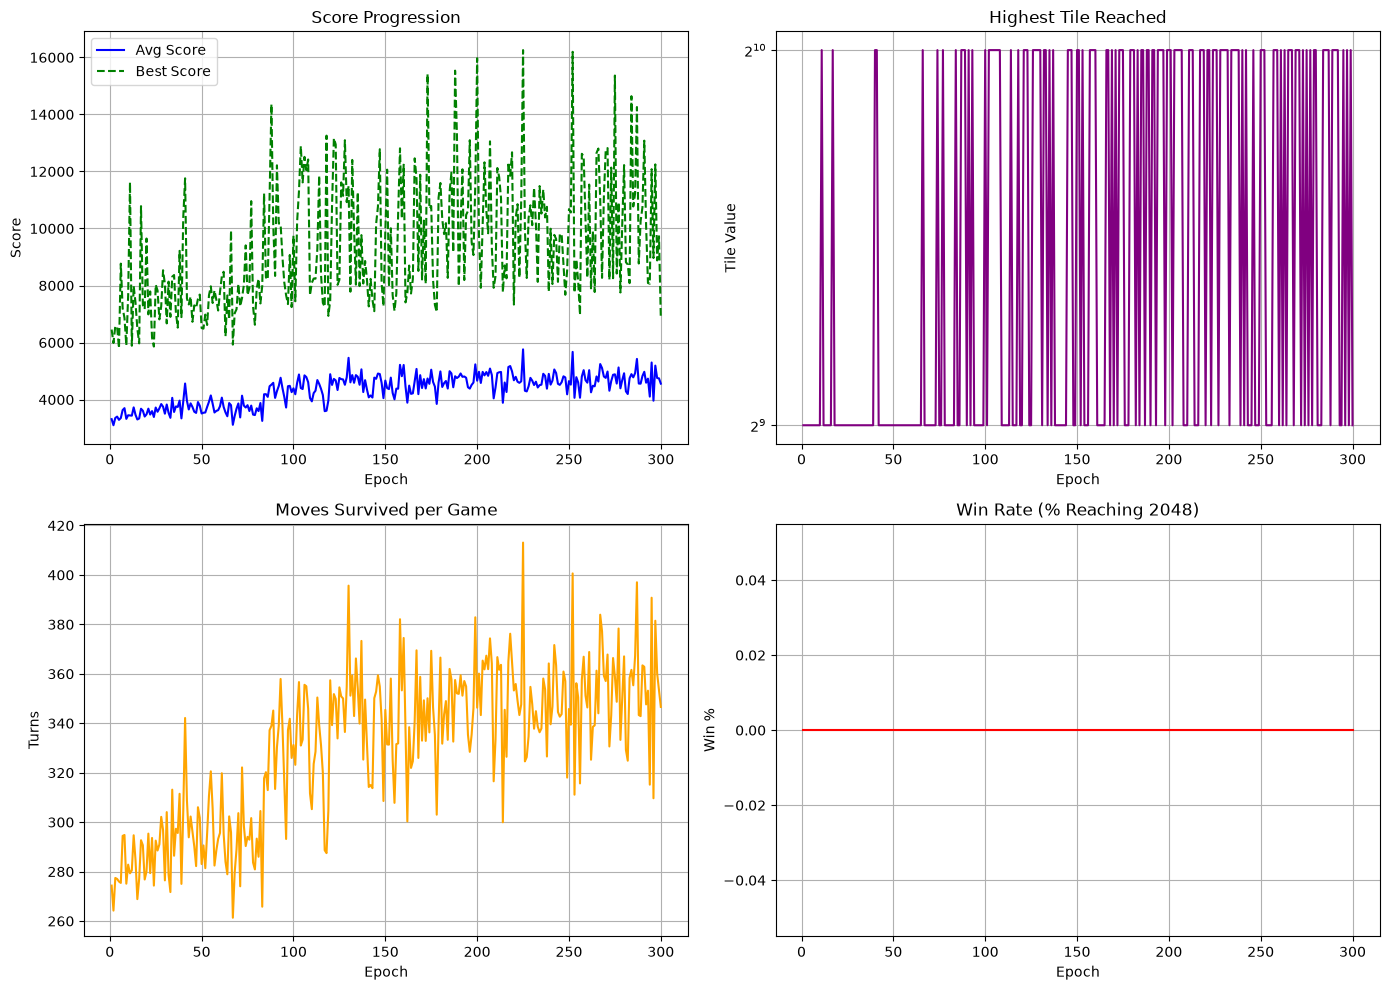

In [154]:
history, _, _, _ = train(initialize_leakyrelu_model_3)
plot(history)

### 16 -> 64 -> 128 -> 64 -> 4

In [63]:
def initialize_leakyrelu_model_4():
    return nn.Sequential(
        nn.Linear(in_features=16, out_features=64),
        nn.LeakyReLU(),
        nn.Linear(in_features=64, out_features=128),
        nn.LeakyReLU(),
        nn.Linear(in_features=128, out_features=64),
        nn.LeakyReLU(),
        nn.Linear(in_features=64, out_features=4),
    )

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
   1    |   0.0%    |   3397.2   |  3502.0   |    6180    |   1634.6   |    512    |   276.1  
  32    |   0.0%    |   3294.8   |  3112.0   |    6204    |   1160.3   |    512    |   277.2  
  34    |   0.0%    |   3059.2   |  3000.0   |    7064    |   1548.7   |    512    |   252.3  
  25    |   0.0%    |   2960.4   |  2578.0   |    6640    |   1624.6   |    512    |   244.7  
  29    |   0.0%    |   2574.0   |  2270.0   |    5760    |   1615.7   |    512    |   222.4  
  37    |   0.0%    |   2315.2   |  1908.0   |    4636    |   1186.0   |    512    |   204.1  
  31    |   0.0%    |   2906.0   |  3102.0   |    4248    |   1081.9   |    256    |   251.7  
  19    |   0.0%    |   2792.8   |  2810.0   |    4288    |   979.1    |    256   

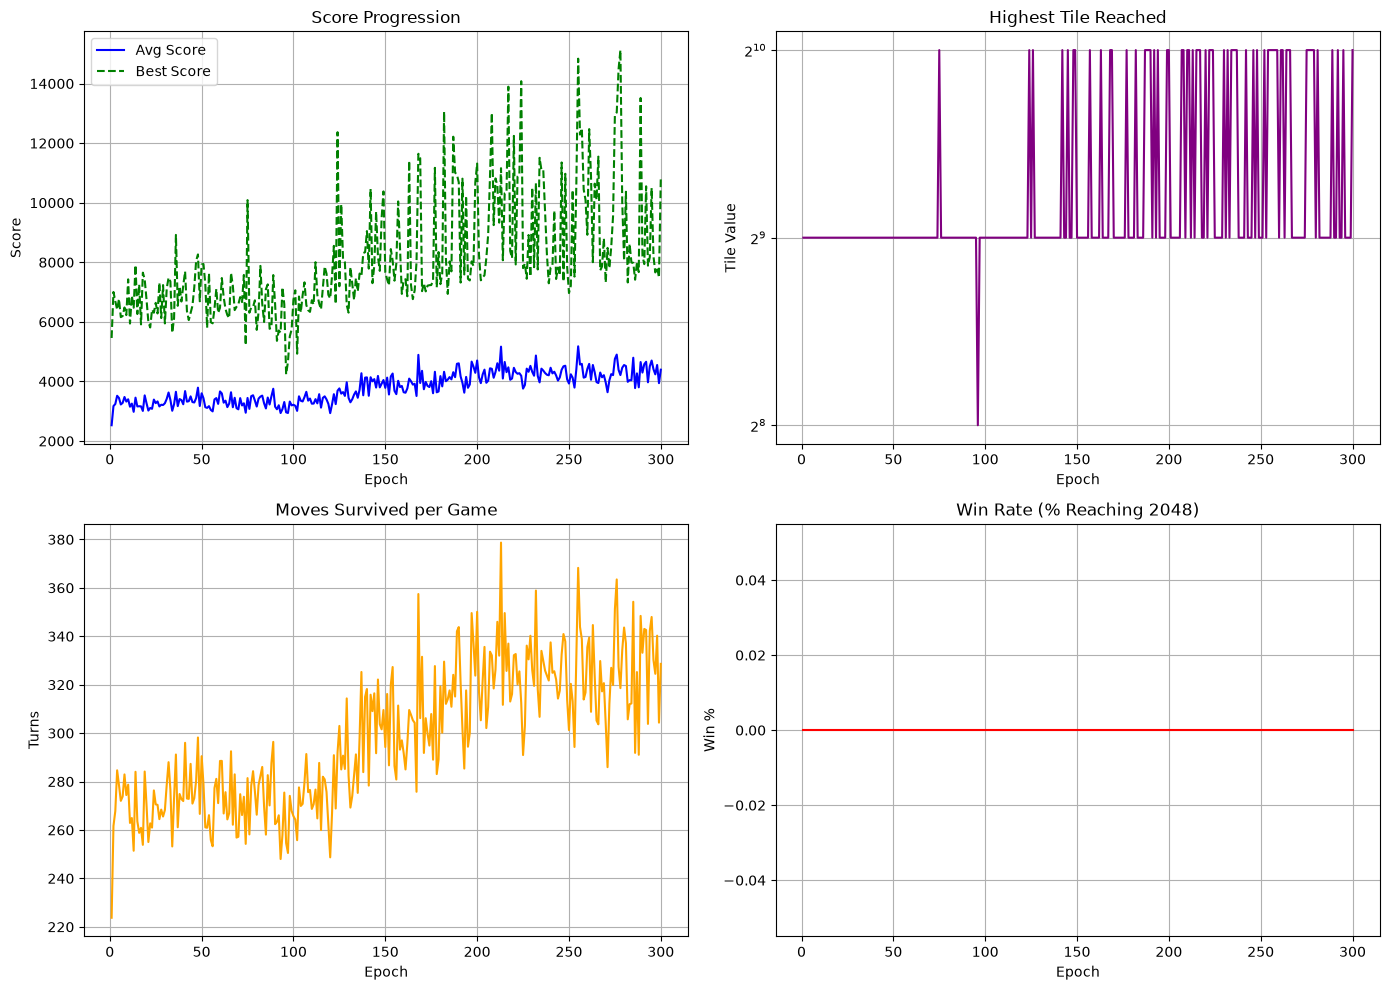

In [159]:
history, _, _, _ = train(initialize_leakyrelu_model_4)
plot(history)

### 16 -> 64 -> 128 -> 64 -> 32 -> 4

In [64]:
def initialize_leakyrelu_model_5():
    return nn.Sequential(
        nn.Linear(in_features=16, out_features=64),
        nn.LeakyReLU(),
        nn.Linear(in_features=64, out_features=128),
        nn.LeakyReLU(),
        nn.Linear(in_features=128, out_features=64),
        nn.LeakyReLU(),
        nn.Linear(in_features=64, out_features=32),
        nn.LeakyReLU(),
        nn.Linear(in_features=32, out_features=4),
    )

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
  17    |   0.0%    |   3526.8   |  3352.0   |    7748    |   2041.3   |    512    |   285.0  
  38    |   0.0%    |   3232.0   |  2970.0   |    6044    |   1762.3   |    512    |   269.4  
  35    |   0.0%    |   3216.8   |  3192.0   |    6456    |   1591.1   |    512    |   272.0  
   1    |   0.0%    |   3061.6   |  2892.0   |    5816    |   1196.9   |    512    |   260.6  
   6    |   0.0%    |   2979.6   |  2486.0   |    5736    |   1546.9   |    512    |   244.7  
  13    |   0.0%    |   2638.4   |  2100.0   |    5524    |   1454.8   |    512    |   233.9  
  22    |   0.0%    |   2392.8   |  2108.0   |    4768    |   1305.6   |    512    |   210.2  
  28    |   0.0%    |   2973.2   |  3012.0   |    4220    |   998.5    |    256   

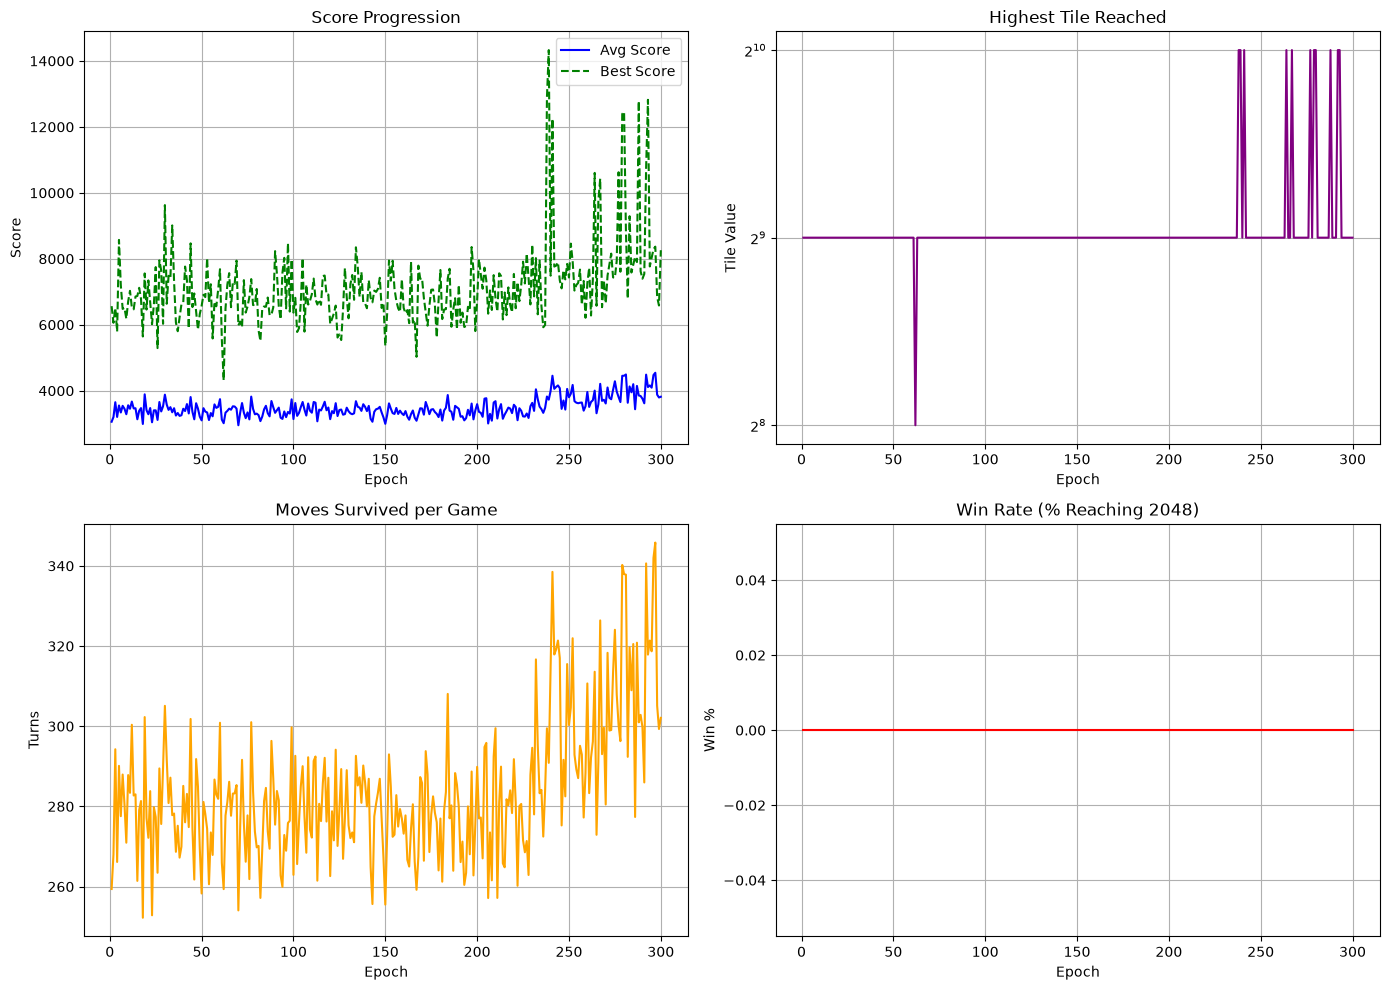

In [161]:
history, _, _, _ = train(initialize_leakyrelu_model_5)
plot(history)

## Running model 3 and 4 of leaky relu activation and model 5 and 6 of tanh activation for higher epochs

In [65]:
TOTAL_GENS = 2000

### Tanh activations:

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Avg Score  |  Median   | Best Score | Score Std  | Best Tile | Avg Moves
-------------------------------------------------------------------------------------------------------------------
   3    |   0.0%    |   3390.0   |  3084.0   |    6912    |   1680.0   |    512    |   278.0  
  15    |   0.0%    |   3117.2   |  3084.0   |    4664    |   1048.8   |    512    |   262.2  
  18    |   0.0%    |   3087.6   |  2736.0   |    6132    |   1415.4   |    512    |   265.2  
   7    |   0.0%    |   3085.6   |  2414.0   |    7108    |   2050.1   |    512    |   253.7  
  10    |   0.0%    |   3080.4   |  3170.0   |    4708    |   1088.2   |    512    |   259.2  
  23    |   0.0%    |   2775.6   |  2686.0   |    5660    |   1288.3   |    512    |   236.7  
   1    |   0.0%    |   2555.2   |  1892.0   |    6840    |   1593.8   |    512    |   224.4  
  34    |   0.0%    |   2545.2   |  2026.0   |    6872    |   1718.6   |    512   

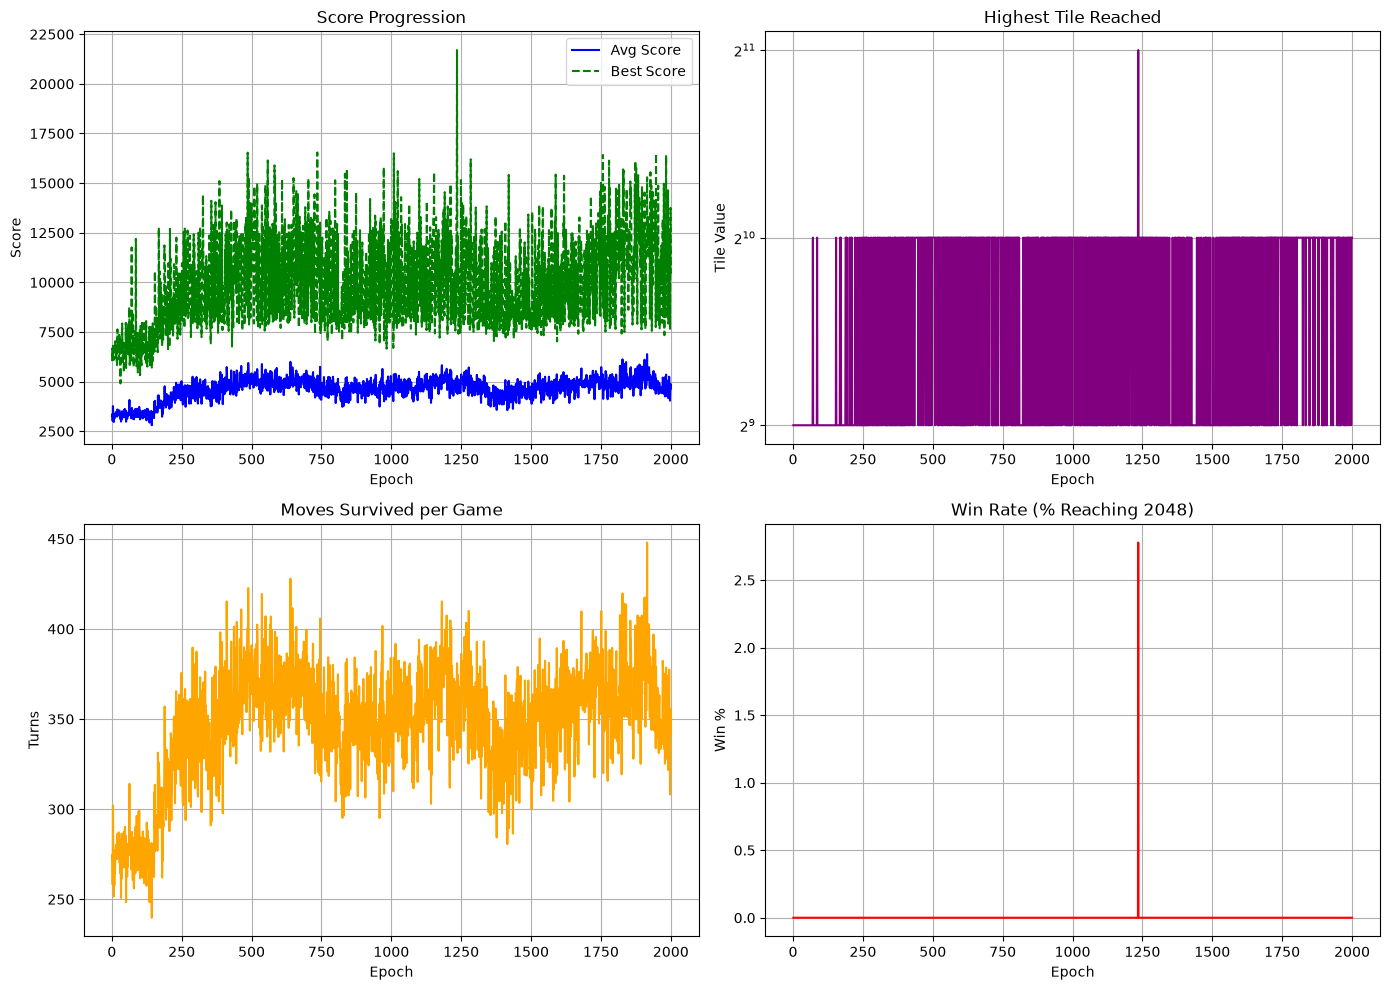

In [166]:
history, parent_history, elite_history, tanh_model_5_champions = train(initialize_model_5)
plot(history)

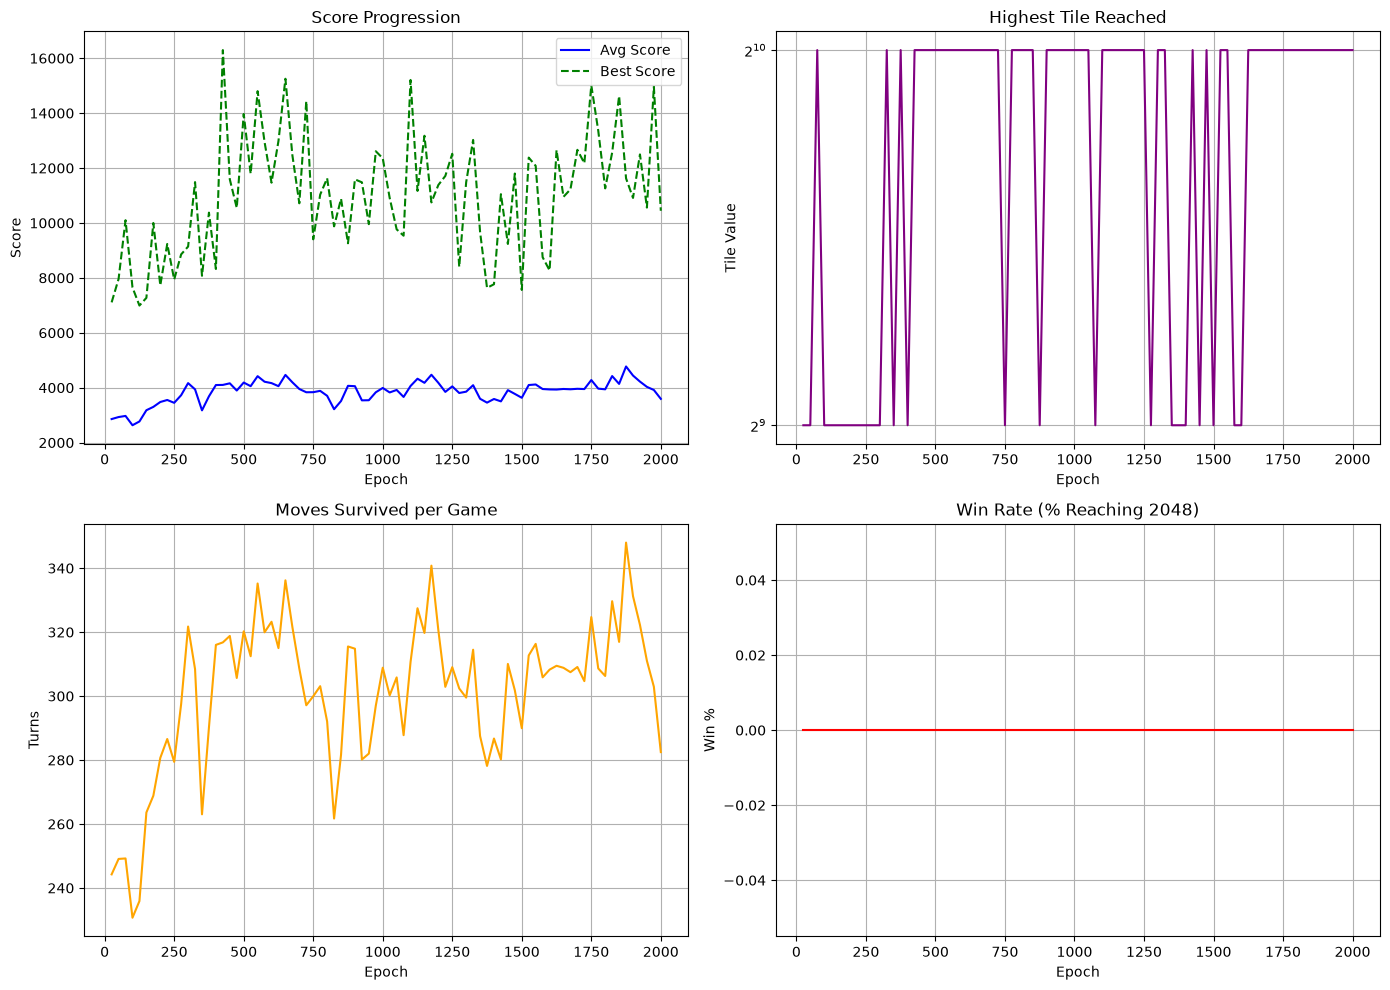

In [175]:
plot(parent_history)

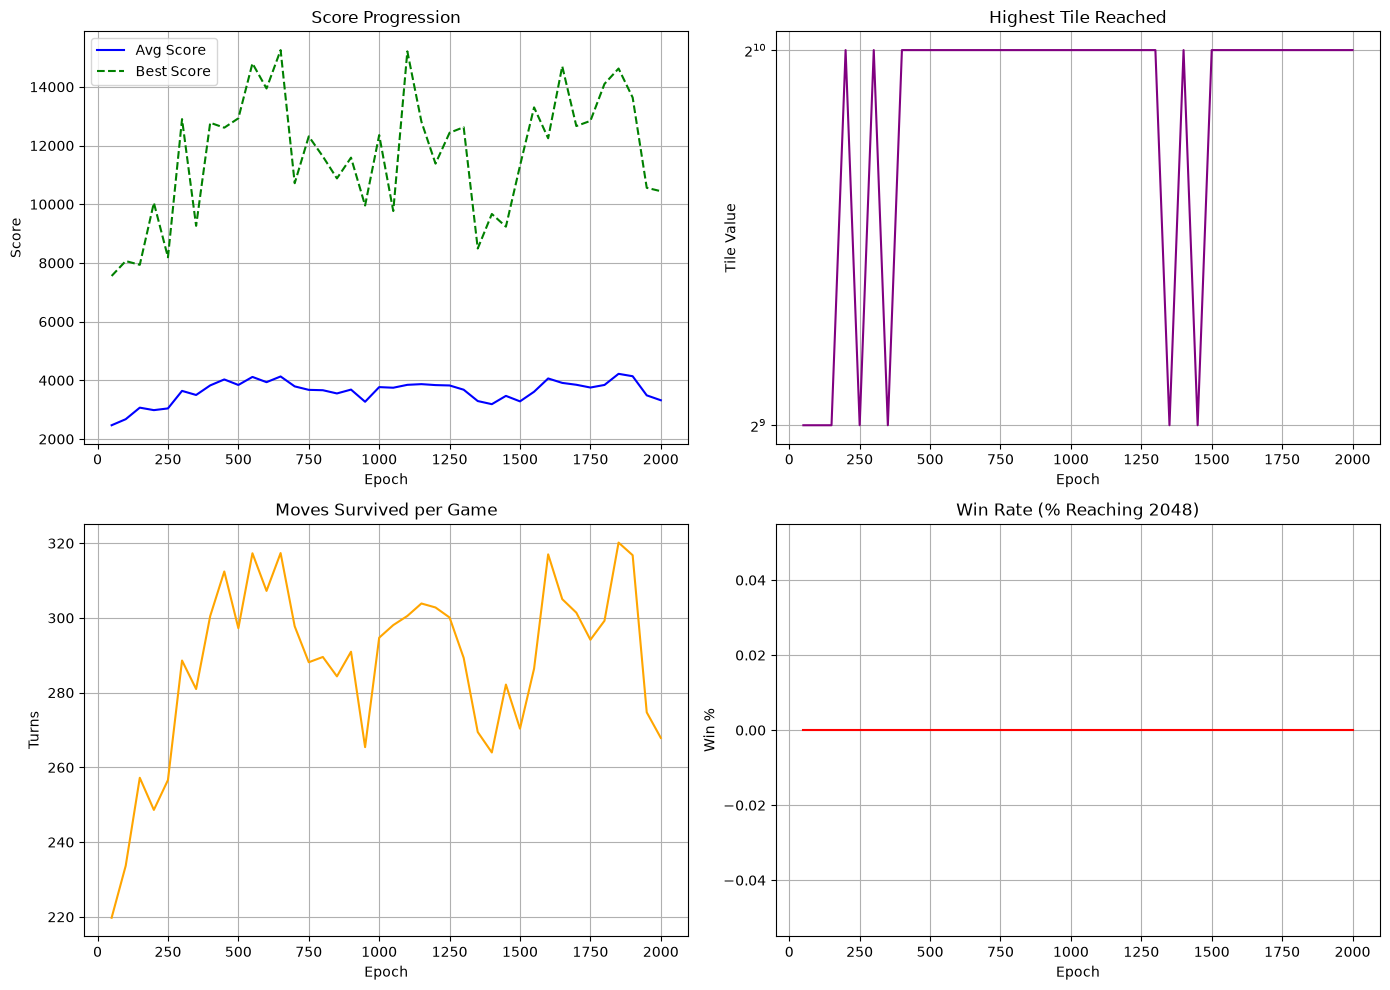

In [176]:
plot(elite_history)

In [174]:
analyze_model_strategy(tanh_model_5_champions[2]['model'])

left
_ _ 2 _ 
_ _ _ _ 
_ _ _ _ 
_ 2 _ _ 

left
2 _ _ _ 
_ _ _ _ 
_ 2 _ _ 
2 _ _ _ 

left
2 _ _ _ 
_ 2 _ _ 
2 _ _ _ 
2 _ _ _ 

left
2 _ _ _ 
2 _ _ _ 
2 _ _ _ 
2 2 _ _ 

up
2 _ 2 _ 
2 _ _ _ 
2 _ _ _ 
4 _ _ _ 

left
4 _ 2 _ 
2 2 _ _ 
4 _ _ _ 
_ _ _ _ 

down
4 2 2 _ 
4 _ _ _ 
4 _ _ _ 
_ _ _ _ 

up
_ _ 4 _ 
_ _ _ _ 
4 _ _ _ 
8 2 2 _ 

left
4 2 4 _ 
8 _ 2 _ 
_ _ _ 2 
_ _ _ _ 

left
4 2 4 _ 
8 2 _ _ 
2 _ _ _ 
_ _ 2 _ 

up
4 2 4 2 
8 2 _ _ 
2 _ _ _ 
2 _ _ _ 

left
4 4 4 2 
8 _ _ 4 
4 _ _ _ 
_ _ _ _ 

down
8 4 2 _ 
8 4 _ _ 
4 _ _ _ 
2 _ _ _ 

up
_ _ _ _ 
16 _ _ 2 
4 _ _ _ 
2 8 2 _ 

left
16 8 2 2 
4 _ _ _ 
2 _ _ _ 
_ 2 _ _ 

left
16 8 4 _ 
4 _ _ _ 
2 _ 2 _ 
2 _ _ _ 

up
16 8 4 2 
4 _ _ _ 
4 _ _ _ 
2 _ _ _ 

down
16 8 4 2 
8 2 _ _ 
2 _ _ _ 
_ _ _ _ 

up
2 _ _ _ 
16 _ _ _ 
8 8 _ _ 
2 2 4 2 

left
2 8 4 2 
16 2 2 _ 
8 _ _ _ 
2 _ _ _ 

left
2 8 4 2 
16 4 _ _ 
8 _ 2 _ 
2 _ _ _ 

left
2 8 4 2 
16 4 _ _ 
8 2 _ _ 
2 2 _ _ 

up
2 8 4 2 
16 4 _ _ 
8 2 _ _ 
4 _ _ 2 

up
2 8 4 4 
16 4 _ _ 
8 2 _ _ 
4 _ 2 _

# Changing the scoring mechanism:

Okay so clearly the models are being stalled currently cause of lucky seed plays. So instead of letting the models be chosen by luck and then be scored so nicely for the highest tile they got that game, let's use median score. 

Each player will now play 5 games each, for which they get scored based on median tiles. On the basis of that, let's train the above architecture for 500 epochs to see if the learning curve is similar.

In [66]:
NUM_MODELS = 50                                                                                                                  
GAMES = 5 # Population plays 5 games each epoch                                                                         
PARENTS = 10                                                                                                                     
PARENT_GAMES = 10 # Parents play 10 games total (5 initial + 5 extra)                                                           
ELITES = 2                                                                                                                       
ELITE_GAMES = 50 # Elites play 50 games total (10 initial + 40 extra)
SCORE_BUCKET = 100

In [67]:
import numpy as np                                                                                                               
                                                                                                                                     
def rank_models(results):                                                                                                        
    for model_id, games in enumerate(results):                                                                                   
        if 'model_id' not in games[0]:                                                                                           
            games[0]['model_id'] = model_id                                                                                      
                                                                                                                                    
        n = len(games)                                                                                                           
        scores = [g['score'] for g in games]                                                                                     
        tiles = [g['max_tile'] for g in games]                                                                                   
        moves = [g['turns'] for g in games]                                                                                      
                                                                                                                                    
        win_rate = sum(1 for t in tiles if t >= 2048) / n                                                                        
        median_tile = float(np.median(tiles))                                                                                    
        avg_score = float(np.mean(scores))                                                                                       
        highest_tile = max(tiles)                                                                                                
        avg_moves = float(np.mean(moves))                                                                                        
                                                                                                                                    
        # 1. Round average score to the nearest SCORE_BUCKET (e.g. 100)                                                          
        # 1020 -> 1000, 1000 -> 1000 (Ties on score, letting highest_tile break it!)                                             
        score_tier = round(avg_score / SCORE_BUCKET) * SCORE_BUCKET                                                              
                                                                                                                                    
        games[0]['win_rate'] = win_rate                                                                                          
        games[0]['median_tile'] = median_tile                                                                                    
        games[0]['avg_score'] = avg_score                                                                                        
        games[0]['score_tier'] = score_tier                                                                                      
        games[0]['highest_tile'] = highest_tile                                                                                  
        games[0]['avg_moves'] = avg_moves                                                                                        
                                                                                                                                    
    # Priority Order: Win Rate -> Median Tile -> Rounded Score Tier -> Highest Tile -> Avg Moves                                 
    sort_key = lambda g: (                                                                                                       
        round(g[0]['win_rate'], 2),                                                                                              
        g[0]['median_tile'],                                                                                                     
        g[0]['score_tier'],                                                                                                      
        g[0]['highest_tile'],                                                                                                    
        round(g[0]['avg_moves'], 1)                                                                                              
    )                                                                                                                            
                                                                                                                                    
    return sorted(results, key=sort_key, reverse=True)

In [68]:
def generate_report(results, print_table=True):                                                                                  
    if not results:                                                                                                              
        return {}                                                                                                                
                                                                                                                                    
    n_models = len(results)                                                                                                      
    n_games = len(results[0])                                                                                                    
                                                                                                                                    
    if print_table:                                                                                                              
        print("=" * 118)                                                                                                         
        header = f"{'Model':^7} | {'Win Rate':^9} | {'Median Tile':^12} | {'Avg Score':^10} | {'Best Score':^10} | {'Score Std':^10} | {'Best Tile':^9} | {'Avg Moves':^9}"                                                                                   
        print(header)                                                                                                            
        print("-" * 118)                                                                                                         
                                                                                                                                    
    all_scores, all_tiles, all_moves = [], [], []                                                                                
    model_summaries = []                                                                                                         
                                                                                                                                    
    for i, games in enumerate(results):                                                                                          
        model_id = games[0].get('model_id', i)                                                                                   
        scores = [g['score'] for g in games]                                                                                     
        tiles = [g['max_tile'] for g in games]                                                                                   
        moves = [g['turns'] for g in games]                                                                                      
                                                                                                                                    
        all_scores.extend(scores)                                                                                                
        all_tiles.extend(tiles)                                                                                                  
        all_moves.extend(moves)                                                                                                  
                                                                                                                                    
        win_rate = games[0].get('win_rate', sum(1 for t in tiles if t >= 2048) / len(tiles))                                     
        median_tile = games[0].get('median_tile', float(np.median(tiles)))                                                       
        highest_tile = games[0].get('highest_tile', max(tiles))                                                                  
        avg_score = games[0].get('avg_score', sum(scores) / len(scores))                                                         
        best_score = max(scores)                                                                                                 
        score_std = float(np.std(scores))                                                                                        
        avg_moves = games[0].get('avg_moves', sum(moves) / len(moves))                                                           
                                                                                                                                    
        if print_table:                                                                                                          
            print(f"{model_id:^7} | {win_rate:^9.1%} | {int(median_tile):^12d} | {avg_score:^10.1f} | {best_score:^10d} | {score_std:^10.1f} | {highest_tile:^9d} | {avg_moves:^9.1f}")                                                                      
                                                                                                                                    
        model_summaries.append({                                                                                                 
            'model_id': model_id,                                                                                                
            'win_rate': win_rate,                                                                                                
            'median_tile': median_tile,                                                                                          
            'avg_score': avg_score,                                                                                              
            'best_score': best_score,                                                                                            
            'score_std': score_std,                                                                                              
            'highest_tile': highest_tile,                                                                                        
            'avg_moves': avg_moves                                                                                               
        })                                                                                                                       
                                                                                                                                    
    overall_win_rate = sum(1 for t in all_tiles if t >= 2048) / len(all_tiles)                                                   
    overall_median_tile = int(np.median(all_tiles))                                                                              
    overall_avg_score = float(np.mean(all_scores))                                                                               
    overall_best_score = int(max(all_scores))                                                                                    
    overall_score_std = float(np.std(all_scores))                                                                                
    overall_best_tile = int(max(all_tiles))                                                                                      
    overall_avg_moves = float(np.mean(all_moves))                                                                                
                                                                                                                                    
    if print_table:                                                                                                              
        print("=" * 118)                                                                                                         
        print(f"Summary (across {n_models} models, {n_games} games each):")                                                      
        print(f"  • Average Win Rate:   {overall_win_rate:.1%}")                                                                 
        print(f"  • Overall Median Tile:{overall_median_tile}")                                                                  
        print(f"  • Average Score:      {overall_avg_score:.1f}")                                                                
        print(f"  • Best Score Seen:    {overall_best_score}")                                                                   
        print(f"  • Highest Tile Seen:  {overall_best_tile}")                                                                    
        print(f"  • Average Moves:      {overall_avg_moves:.1f}")                                                                
        print("=" * 118)                                                                                                         
        print()                                                                                                                  
                                                                                                                                    
    return {                                                                                                                     
        'win_rate': overall_win_rate,                                                                                            
        'median_tile': overall_median_tile,                                                                                      
        'avg_score': overall_avg_score,                                                                                          
        'best_score': overall_best_score,                                                                                        
        'score_std': overall_score_std,                                                                                          
        'best_tile': overall_best_tile,                                                                                          
        'avg_moves': overall_avg_moves,                                                                                          
        'models': model_summaries                                                                                                
    }

In [69]:
def train(init_func=initialize_model):                                                                                           
    # 1. Initialize population using init_func                                                                                   
    population = create_random_models(NUM_MODELS, init_func)                                                                     
    history = []                                                                                                                 
    parent_history = []                                                                                                          
    elite_history = []                                                                                                           
    top_3_all_time = []                                                                                                          
                                                                                                                                    
    def update_hall_of_fame(candidate_model, candidate_games, epoch):                                                            
        cand_key = (                                                                                                             
            round(candidate_games[0]['win_rate'], 2),                                                                            
            candidate_games[0]['median_tile'],                                                                                   
            candidate_games[0]['score_tier'],                                                                                    
            candidate_games[0]['highest_tile'],                                                                                  
            round(candidate_games[0]['avg_moves'], 1)                                                                            
        )                                                                                                                        
        entry = {                                                                                                                
            # Clone model using init_func                                                                                        
            'model': clone_model(candidate_model, init_func),                                                                    
            'epoch': epoch,                                                                                                      
            'type': 'All-Time Champion',                                                                                         
            'model_id': candidate_games[0].get('model_id'),                                                                      
            'median_tile': candidate_games[0]['median_tile'],                                                                    
            'highest_tile': candidate_games[0]['highest_tile'],                                                                  
            'avg_score': candidate_games[0]['avg_score'],                                                                        
            'avg_moves': candidate_games[0]['avg_moves'],                                                                        
            'win_rate': candidate_games[0]['win_rate'],                                                                          
            '_key': cand_key                                                                                                     
        }                                                                                                                        
        top_3_all_time.append(entry)                                                                                             
        top_3_all_time.sort(key=lambda x: x['_key'], reverse=True)                                                               
        if len(top_3_all_time) > 3:                                                                                              
            top_3_all_time.pop()                                                                                                 
                                                                                                                                    
    with ProcessPoolExecutor(max_workers=NUM_WORKERS) as executor:                                                               
        for epoch in range(1, TOTAL_GENS + 1):                                                                                   
            # 1. All 50 models play 5 initial games                                                                              
            results = list(executor.map(play_n_games_batched, population, [GAMES] * len(population)))                            
                                                                                                                                    
            # 2. Rank candidates (Median Tile -> Score Tier -> Highest Tile)                                                     
            ranked = rank_models(results)                                                                                        
                                                                                                                                    
            # 3. Log generation progress (silent)                                                                                
            epoch_summary = generate_report(ranked, print_table=False)                                                           
            epoch_summary['epoch'] = epoch                                                                                       
            history.append(epoch_summary)                                                                                        
                                                                                                                                    
            # 4. Extract parents and elites (with their 5 initial games)                                                         
            elites = [population[ranked[i][0]['model_id']] for i in range(ELITES)]                                               
            elite_games_so_far = [list(ranked[i]) for i in range(ELITES)]                                                        
                                                                                                                                    
            parents = [population[ranked[i][0]['model_id']] for i in range(PARENTS)]                                             
            parent_games_so_far = [list(ranked[i]) for i in range(PARENTS)]                                                      
                                                                                                                                    
            update_hall_of_fame(population[ranked[0][0]['model_id']], ranked[0], epoch)                                          
                                                                                                                                    
            # 5. Milestone: Parents Report (5 existing + 5 extra = 10 games)                                                     
            if epoch % 25 == 0:                                                                                                  
                extra_needed = max(0, PARENT_GAMES - len(parent_games_so_far[0]))                                                
                if extra_needed > 0:                                                                                             
                    extra_results = list(executor.map(play_n_games_batched, parents, [extra_needed] * len(parents)))             
                    parent_results = [                                                                                           
                        prev + new for prev, new in zip(parent_games_so_far, extra_results)                                      
                    ]                                                                                                            
                else:                                                                                                            
                    parent_results = parent_games_so_far                                                                         
                                                                                                                                    
                # Re-rank parents based on all 10 games                                                                          
                parent_results = rank_models(parent_results)                                                                     
                                                                                                                                    
                # Re-elect elites from the 10-game test                                                                          
                elites = [population[parent_results[i][0]['model_id']] for i in range(ELITES)]                                   
                elite_games_so_far = [list(parent_results[i]) for i in range(ELITES)]                                            
                                                                                                                                    
                update_hall_of_fame(elites[0], parent_results[0], epoch)                                                         
                                                                                                                                    
                print(f"EPOCH {epoch}: Parents Report ({len(parent_results[0])} games each):")                                   
                p_report = generate_report(parent_results, print_table=True)                                                     
                p_report['epoch'] = epoch                                                                                        
                parent_history.append(p_report)                                                                                  
                                                                                                                                    
            # 6. Milestone: Elites Report (10 existing + 40 extra = 50 games)                                                    
            if epoch % 50 == 0:                                                                                                  
                extra_needed = max(0, ELITE_GAMES - len(elite_games_so_far[0]))                                                  
                if extra_needed > 0:                                                                                             
                    extra_results = list(executor.map(play_n_games_batched, elites, [extra_needed] * len(elites)))               
                    elite_results = [                                                                                            
                        prev + new for prev, new in zip(elite_games_so_far, extra_results)                                       
                    ]                                                                                                            
                else:                                                                                                            
                    elite_results = elite_games_so_far                                                                           
                                                                                                                                    
                # Re-rank elites based on all 50 games                                                                           
                elite_results = rank_models(elite_results)                                                                       
                update_hall_of_fame(elites[0], elite_results[0], epoch)                                                          
                                                                                                                                    
                print("=" * 118)                                                                                                 
                print(f"EPOCH {epoch}: Elites Report ({len(elite_results[0])} games each):")                                     
                e_report = generate_report(elite_results, print_table=True)                                                      
                e_report['epoch'] = epoch                                                                                        
                elite_history.append(e_report)                                                                                   
                print("=" * 118)                                                                                                 
                                                                                                                                    
            # 7. Next generation reproduction using init_func                                                                    
            offspring_count = NUM_MODELS - ELITES - PARENTS                                                                      
            offsprings = create_mutated_offsprings(parents, offspring_count, init_func)                                          
            fresh_models = create_random_models(FRESH_CANDIDATES, init_func)                                                     
                                                                                                                                    
            population = elites + offsprings + fresh_models                                                                      
                                                                                                                                    
    # --- COMPILE FINAL CHAMPIONS LIST (Top 3 All-Time + Final Generation Elites) ---                                            
    latest_elites_info = []                                                                                                      
    for i in range(ELITES):                                                                                                      
        source_game = elite_games_so_far[i] if (TOTAL_GENS % 50 == 0) else (parent_games_so_far[i] if (TOTAL_GENS % 25 == 0) else ranked[i])                                                                                                                         
        latest_elites_info.append({                                                                                              
            'model': clone_model(elites[i], init_func),                                                                          
            'epoch': TOTAL_GENS,                                                                                                 
            'type': f'Latest Gen Elite #{i+1}',                                                                                  
            'model_id': source_game[0].get('model_id'),
            'median_tile': source_game[0]['median_tile'],
            'highest_tile': source_game[0]['highest_tile'],
            'avg_score': source_game[0]['avg_score'],
            'avg_moves': source_game[0]['avg_moves'],
            'win_rate': source_game[0]['win_rate']
        })

    # Combined list: [All-Time #1, All-Time #2, All-Time #3, Final Elite #1, Final Elite #2]
    all_champions = top_3_all_time + latest_elites_info

    print("=" * 105)
    print("🏆 SAVED MODELS (Top 3 All-Time + Final Generation Elites) 🏆")                                                       
    print(f"{'Idx':^5} | {'Category':^20} | {'Origin Epoch':^14} | {'Median Tile':^13} | {'Highest Tile':^14} | {'Avg Score':^11}")
    print("-" * 105)
    for idx, c in enumerate(all_champions):
        print(f"[{idx}]   | {c['type']:^20} | Epoch {c['epoch']:^8} | {int(c['median_tile']):^13d} | {c['highest_tile']:^14d} | {c['avg_score']:^11.1f}")
    print("=" * 105)

    return history, parent_history, elite_history, all_champions

In [70]:
def analyze_model_strategy(model, num_test_games=5):                                                                             
    """                                                                                                                          
    Plays num_test_games, picks the BEST game among them to display step-by-step,                                                
    and prints overall move distributions and corner retention.                                                                  
    """                                                                                                                          
    move_counts = {'up': 0, 'down': 0, 'left': 0, 'right': 0}                                                                    
    corner_retention = []                                                                                                        
    recorded_games = []                                                                                                          
                                                                                                                                    
    for game_num in range(1, num_test_games + 1):                                                                                
        board = generate_board()                                                                                                 
        turns = 0                                                                                                                
        total_score = 0                                                                                                          
        game_history = []  # Stores (direction, board_state) for replay                                                          
                                                                                                                                    
        while turns < 5000:                                                                                                      
            d, move_score, next_b = request_model_move(board, model)                                                             
            if next_b is None:                                                                                                   
                break                                                                                                            
                                                                                                                                    
            # Record move & board snapshot                                                                                       
            game_history.append((d, board.copy()))                                                                               
                                                                                                                                    
            move_counts[d] += 1                                                                                                  
            total_score += move_score                                                                                            
            board = spawn_tile(next_b)                                                                                           
            turns += 1                                                                                                           
                                                                                                                                    
            # Check if largest tile is in one of the 4 corners                                                                   
            max_val = np.max(board)                                                                                              
            corners = [board[0, 0], board[0, 3], board[3, 0], board[3, 3]]                                                       
            corner_retention.append(max_val in corners)                                                                          
                                                                                                                                    
        max_exponent = np.max(board)                                                                                             
        max_tile = (1 << max_exponent) if max_exponent > 0 else 0                                                                
                                                                                                                                    
        recorded_games.append({                                                                                                  
            'game_num': game_num,                                                                                                
            'history': game_history,                                                                                             
            'final_board': board.copy(),                                                                                         
            'max_tile': max_tile,                                                                                                
            'score': total_score,                                                                                                
            'turns': turns                                                                                                       
        })                                                                                                                       
                                                                                                                                    
    # 1. Identify the BEST game (highest tile -> highest score -> most moves)                                                    
    best_game = max(                                                                                                             
        recorded_games,                                                                                                          
        key=lambda g: (g['max_tile'], g['score'], g['turns'])                                                                    
    )                                                                                                                            
                                                                                                                                    
    # 2. Replay the BEST game step-by-step                                                                                       
    print("=" * 70)                                                                                                              
    print(f"🎬 STEP-BY-STEP REPLAY OF THE BEST GAME (Game {best_game['game_num']})")                                             
    print(f"Max Tile: {best_game['max_tile']} | Final Score: {best_game['score']} | Moves: {best_game['turns']}")                
    print("=" * 70)                                                                                                              
                                                                                                                                    
    for step, (d, b) in enumerate(best_game['history']):                                                                         
        print(f"Move #{step + 1}: {d}")                                                                                          
        show_board(b)                                                                                                            
                                                                                                                                    
    print("Final Board (Game Over):")                                                                                            
    show_board(best_game['final_board'])                                                                                         
                                                                                                                                    
    # 3. Print overall summary across all test games                                                                             
    print("=" * 70)                                                                                                              
    print(f"📊 SUMMARY OF ALL {num_test_games} GAMES")                                                                           
    print("=" * 70)                                                                                                              
    for g in recorded_games:                                                                                                     
        star = " 🌟 (BEST)" if g['game_num'] == best_game['game_num'] else ""                                                    
        print(f"Game {g['game_num']} Finished -> Max Tile: {g['max_tile']:4d} | Score: {g['score']:6d} | Moves: {g['turns']:4d}{star}")                                                                                                            
                                                                                                                                    
    total_moves = sum(move_counts.values())                                                                                      
    print("\n--- Move Distribution Analysis ---")                                                                                
    for move, count in move_counts.items():                                                                                      
        pct = (count / total_moves * 100) if total_moves > 0 else 0                                                              
        print(f"  • {move.upper():5s}: {count:5d} ({pct:.1f}%)")                                                                 
                                                                                                                                    
    corner_pct = (sum(corner_retention) / len(corner_retention) * 100) if corner_retention else 0                                
    print(f"\nCorner Retention: Highest tile was in a corner {corner_pct:.1f}% of the time.")                                    
    if corner_pct > 75:                                                                                                          
        print("💡 The model has learned the classic 2048 Corner Strategy!")

In [71]:
TOTAL_GENS = 500

In [194]:
history, parent_history, elite_history, tanh_model_5_champions_2 = train(initialize_model_5)

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Median Tile  | Avg Score  | Best Score | Score Std  | Best Tile | Avg Moves
----------------------------------------------------------------------------------------------------------------------
  38    |   0.0%    |     256      |   4061.6   |    7448    |   1900.2   |    512    |   316.0  
  10    |   0.0%    |     256      |   3902.0   |    7100    |   1756.1   |    512    |   314.4  
  13    |   0.0%    |     256      |   3917.2   |    7780    |   1972.3   |    512    |   310.5  
  32    |   0.0%    |     256      |   3542.0   |    7700    |   2125.7   |    512    |   277.9  
   7    |   0.0%    |     256      |   3443.2   |    5748    |   1344.5   |    512    |   280.5  
   6    |   0.0%    |     256      |   3395.2   |    6836    |   1607.6   |    512    |   277.5  
  29    |   0.0%    |     256      |   3224.4   |    6516    |   1416.8   |    512    |   273.1  
  41    |   0.0%    |     256      |   3159.2   |    45

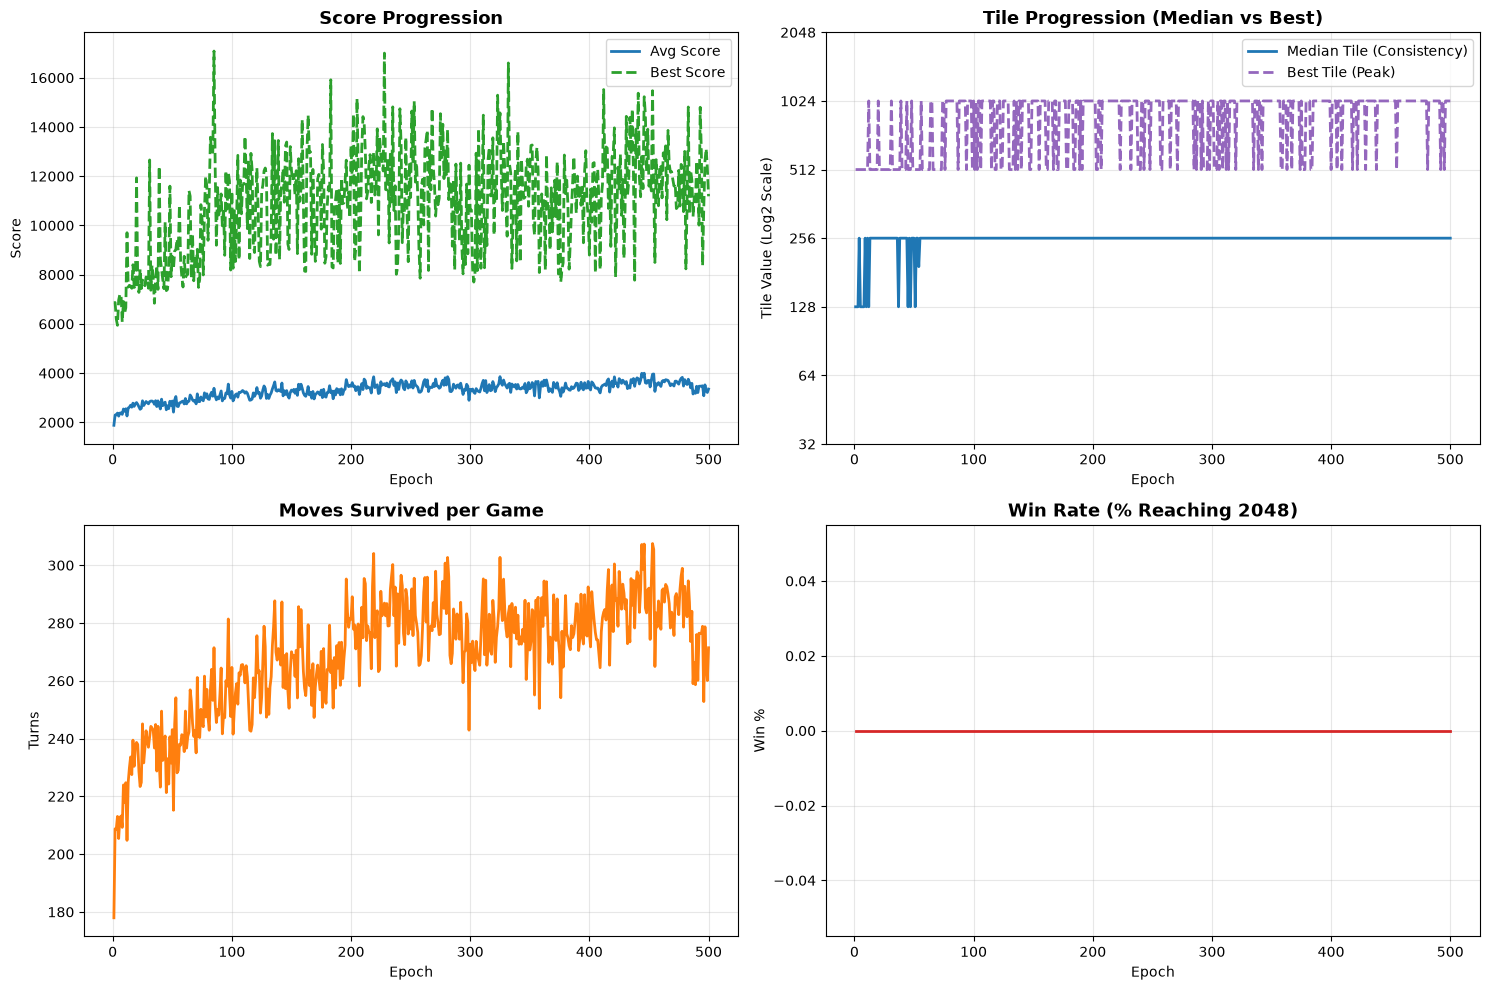

In [200]:
plot(history)

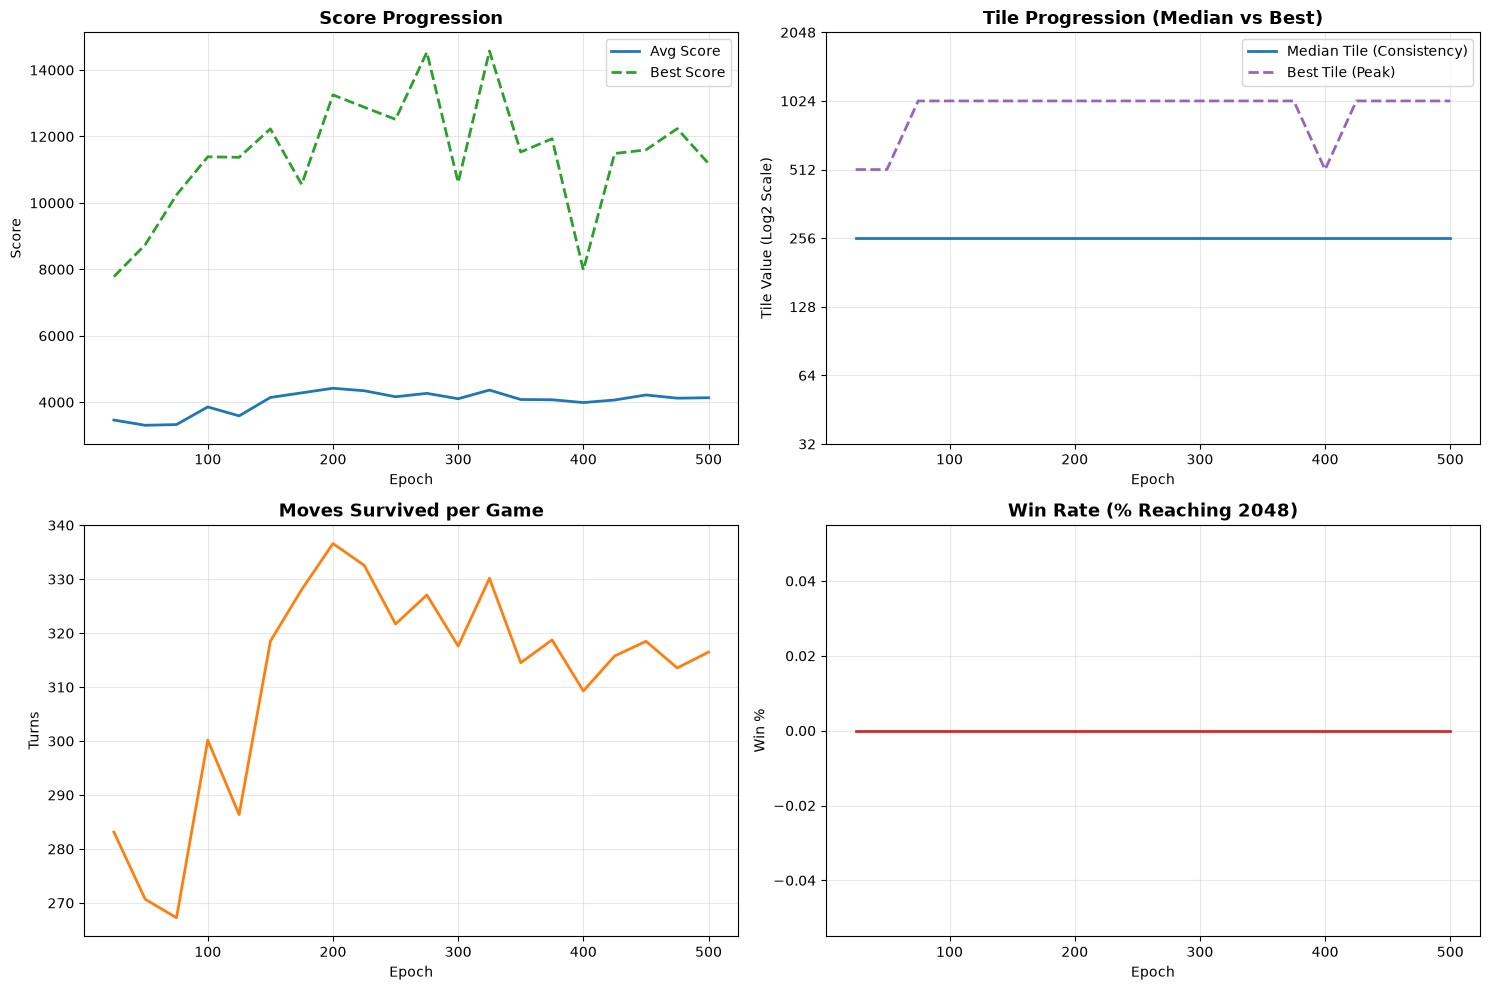

In [201]:
plot(parent_history)

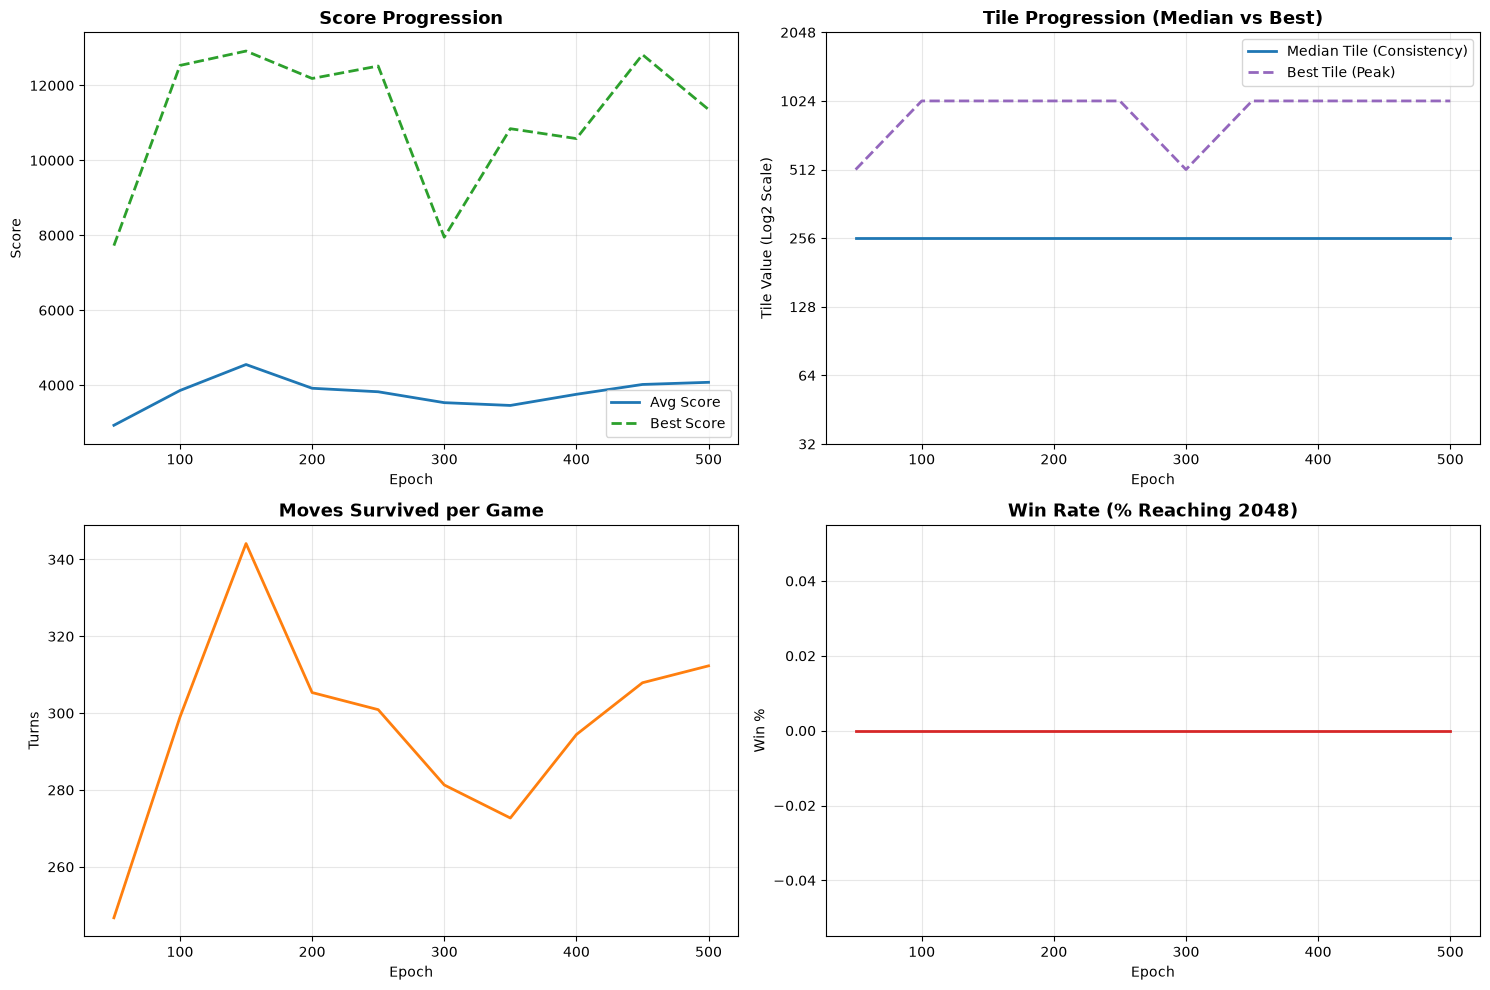

In [202]:
plot(elite_history)

In [203]:
# 1. Analyze the #1 All-Time Champion                                                                                            
analyze_model_strategy(tanh_model_5_champions_2[0]['model'])                                                                                    
                                                                                                                                    
# 2. Analyze the #1 Elite from the Final Generation                                                                              
analyze_model_strategy(tanh_model_5_champions_2[3]['model'])                                                                                    
                                                                                                                                    
# 3. Analyze the #2 Elite from the Final Generation                                                                              
analyze_model_strategy(tanh_model_5_champions_2[4]['model'])

🎬 STEP-BY-STEP REPLAY OF THE BEST GAME (Game 5)
Max Tile: 128 | Final Score: 1356 | Moves: 140
Move #1: left
_ _ _ _ 
_ _ 2 _ 
_ _ _ _ 
_ 2 _ _ 

Move #2: left
_ _ _ _ 
2 _ _ _ 
_ _ _ 2 
2 _ _ _ 

Move #3: left
_ _ _ 2 
2 _ _ _ 
2 _ _ _ 
2 _ _ _ 

Move #4: left
2 _ _ 2 
2 _ _ _ 
2 _ _ _ 
2 _ _ _ 

Move #5: down
4 _ _ _ 
2 4 _ _ 
2 _ _ _ 
2 _ _ _ 

Move #6: left
_ _ _ _ 
4 2 _ _ 
2 _ _ _ 
4 4 _ _ 

Move #7: up
2 _ _ _ 
4 2 _ _ 
2 _ _ _ 
8 _ _ _ 

Move #8: left
2 2 _ _ 
4 _ _ 2 
2 _ _ _ 
8 _ _ _ 

Move #9: left
4 _ 2 _ 
4 2 _ _ 
2 _ _ _ 
8 _ _ _ 

Move #10: left
4 2 _ _ 
4 2 2 _ 
2 _ _ _ 
8 _ _ _ 

Move #11: left
4 2 _ 2 
4 4 _ _ 
2 _ _ _ 
8 _ _ _ 

Move #12: left
4 4 _ _ 
8 _ _ _ 
2 _ _ _ 
8 _ _ 2 

Move #13: down
8 _ _ _ 
8 4 _ _ 
2 _ _ _ 
8 2 _ _ 

Move #14: up
_ _ _ _ 
16 _ _ _ 
2 4 2 _ 
8 2 _ _ 

Move #15: left
16 4 2 _ 
2 2 2 _ 
8 _ _ _ 
_ _ _ _ 

Move #16: right
16 4 2 2 
4 2 _ _ 
8 _ _ _ 
_ _ _ _ 

Move #17: left
_ 16 4 4 
_ _ 4 2 
_ _ 2 8 
_ _ _ _ 

Move #18: up
16 8 _ _ 
4 2 _ 

In [72]:
import pandas as pd                                                                                                              
import matplotlib.pyplot as plt                                                                                                  
                                                                                                                                    
def plot(history, save_path='training_progress.png'):                                                                            
    df_history = pd.DataFrame(history)                                                                                           
                                                                                                                                    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))                                                                             
                                                                                                                                    
    # 1. Score Progression (Avg vs Best)                                                                                         
    axes[0, 0].plot(df_history['epoch'], df_history['avg_score'], label='Avg Score', color='#1f77b4', linewidth=2)               
    axes[0, 0].plot(df_history['epoch'], df_history['best_score'], label='Best Score', color='#2ca02c', linestyle='--', linewidth=2)                                                                                                                       
    axes[0, 0].set_title('Score Progression', fontsize=13, fontweight='bold')                                                    
    axes[0, 0].set_xlabel('Epoch')                                                                                               
    axes[0, 0].set_ylabel('Score')                                                                                               
    axes[0, 0].legend()                                                                                                          
    axes[0, 0].grid(True, alpha=0.3)                                                                                             
                                                                                                                                    
    # 2. Tile Progression (Median vs Best) <-- UPDATED HERE                                                                      
    axes[0, 1].plot(df_history['epoch'], df_history['median_tile'], label='Median Tile (Consistency)', color='#1f77b4', linewidth=2)                                                                                                                       
    axes[0, 1].plot(df_history['epoch'], df_history['best_tile'], label='Best Tile (Peak)', color='#9467bd', linestyle='--', linewidth=2)                                                                                                                       
    axes[0, 1].set_title('Tile Progression (Median vs Best)', fontsize=13, fontweight='bold')                                    
    axes[0, 1].set_xlabel('Epoch')                                                                                               
    axes[0, 1].set_ylabel('Tile Value (Log2 Scale)')                                                                             
    axes[0, 1].set_yscale('log', base=2)                                                                                         
    # Set readable power-of-two ticks                                                                                            
    axes[0, 1].set_yticks([32, 64, 128, 256, 512, 1024, 2048])                                                                   
    axes[0, 1].get_yaxis().set_major_formatter(plt.ScalarFormatter())                                                            
    axes[0, 1].legend()                                                                                                          
    axes[0, 1].grid(True, alpha=0.3)                                                                                             
                                                                                                                                    
    # 3. Average Moves Survived                                                                                                  
    axes[1, 0].plot(df_history['epoch'], df_history['avg_moves'], label='Avg Moves', color='#ff7f0e', linewidth=2)               
    axes[1, 0].set_title('Moves Survived per Game', fontsize=13, fontweight='bold')                                              
    axes[1, 0].set_xlabel('Epoch')                                                                                               
    axes[1, 0].set_ylabel('Turns')                                                                                               
    axes[1, 0].grid(True, alpha=0.3)                                                                                             
                                                                                                                                    
    # 4. Win Rate (% Reaching 2048)                                                                                              
    axes[1, 1].plot(df_history['epoch'], df_history['win_rate'] * 100, label='Win Rate (%)', color='#d62728', linewidth=2)       
    axes[1, 1].set_title('Win Rate (% Reaching 2048)', fontsize=13, fontweight='bold')                                           
    axes[1, 1].set_xlabel('Epoch')                                                                                               
    axes[1, 1].set_ylabel('Win %')                                                                                               
    axes[1, 1].grid(True, alpha=0.3)                                                                                             
                                                                                                                                    
    plt.tight_layout()                                                                                                           
                                                                                                                                    
    if save_path:                                                                                                                
        plt.savefig(save_path, dpi=300, bbox_inches='tight')                                                                     
                                                                                                                                    
    plt.show()

## Changing the metrics again: 

The median tile metric works much better, but it still saturates. So let's introduce better metrics

Win Rate -> Median Tile -> Corner Retention % -> Risk-Adjusted Score Tier -> Empty Cells -> Score / Move

In [73]:
@torch.inference_mode()                                                                                                          
def play_n_games_batched(model, n=1, normalize_boards=True, max_steps=5000):                                                     
    torch.set_num_threads(1)                                                                                                     
                                                                                                                                    
    boards = np.array([generate_board() for _ in range(n)], dtype=np.int32)                                                      
    active = np.ones(n, dtype=bool)                                                                                              
    turns = np.zeros(n, dtype=np.int32)                                                                                          
    scores = np.zeros(n, dtype=np.int64)                                                                                         
                                                                                                                                    
    # --- NEW METRICS ACCUMULATORS ---                                                                                           
    corner_turns = np.zeros(n, dtype=np.int32)                                                                                   
    empty_cell_sum = np.zeros(n, dtype=np.int64)                                                                                 
                                                                                                                                    
    step = 0                                                                                                                     
    while np.any(active) and step < max_steps:                                                                                   
        step += 1                                                                                                                
        active_idx = np.where(active)[0]                                                                                         
                                                                                                                                    
        # 1. Track board health before move                                                                                      
        cur_boards = boards[active_idx]                                                                                          
        max_tiles = np.max(cur_boards, axis=(1, 2))                                                                              
        corners = cur_boards[:, [0, 0, 3, 3], [0, 3, 0, 3]]                                                                      
        in_corner = np.any(corners == max_tiles[:, None], axis=1)                                                                
        empty_counts = np.sum(cur_boards == 0, axis=(1, 2))                                                                      
                                                                                                                                    
        corner_turns[active_idx] += in_corner                                                                                    
        empty_cell_sum[active_idx] += empty_counts                                                                               
                                                                                                                                    
        # 2. Batch forward pass                                                                                                  
        batch_inputs = cur_boards.reshape(-1, 16)                                                                                
        if normalize_boards:                                                                                                     
            inp = torch.from_numpy(batch_inputs / 15.0).float()                                                                  
        else:                                                                                                                    
            inp = torch.from_numpy(batch_inputs).float()                                                                         
        logits = model(inp)                                                                                                      
                                                                                                                                    
        ranked_moves = torch.argsort(logits, dim=1, descending=True).tolist()                                                    
                                                                                                                                    
        for k, i in enumerate(active_idx):                                                                                       
            moved = None                                                                                                         
            move_score = 0                                                                                                       
                                                                                                                                    
            for action_idx in ranked_moves[k]:                                                                                   
                dir = moves[action_idx]                                                                                          
                mb, ms = move_funcs['move_'+dir](boards[i])                                                                      
                if not np.array_equal(mb, boards[i]):                                                                            
                    moved = mb                                                                                                   
                    move_score += ms                                                                                             
                    break                                                                                                        
                                                                                                                                    
            if moved is None:                                                                                                    
                active[i] = False                                                                                                
            else:                                                                                                                
                boards[i] = spawn_tile(moved)                                                                                    
                turns[i] += 1                                                                                                    
                scores[i] += move_score                                                                                          
                                                                                                                                    
    results = []                                                                                                                 
    for i in range(n):                                                                                                           
        max_exponent = np.max(boards[i])                                                                                         
        max_tile = (1 << max_exponent) if max_exponent > 0 else 0                                                                
        t = max(1, turns[i])                                                                                                     
        results.append({                                                                                                         
            'turns': turns[i],                                                                                                   
            'max_tile': int(max_tile),                                                                                           
            'score': scores[i],                                                                                                  
            'corner_ratio': float(corner_turns[i] / t),                                                                          
            'avg_empty_cells': float(empty_cell_sum[i] / t)                                                                      
        })                                                                                                                       
                                                                                                                                    
    return results

In [74]:
def rank_models(results):                                                                                                        
    for model_id, games in enumerate(results):                                                                                   
        if 'model_id' not in games[0]:                                                                                           
            games[0]['model_id'] = model_id                                                                                      
                                                                                                                                    
        n = len(games)                                                                                                           
        scores = [g['score'] for g in games]                                                                                     
        tiles = [g['max_tile'] for g in games]                                                                                   
        moves = [g['turns'] for g in games]                                                                                      
        corner_ratios = [g.get('corner_ratio', 0.0) for g in games]                                                              
        empty_cells = [g.get('avg_empty_cells', 0.0) for g in games]                                                             
                                                                                                                                    
        win_rate = sum(1 for t in tiles if t >= 2048) / n                                                                        
        median_tile = float(np.median(tiles))                                                                                    
        avg_score = float(np.mean(scores))                                                                                       
        score_std = float(np.std(scores))                                                                                        
        highest_tile = max(tiles)                                                                                                
        avg_moves = float(np.mean(moves))                                                                                        
        avg_corner_ratio = float(np.mean(corner_ratios))                                                                         
        avg_empty = float(np.mean(empty_cells))                                                                                  
                                                                                                                                    
        # Risk-adjusted score: penalizes erratic, high-variance models                                                           
        reliable_score = max(0.0, avg_score - 0.5 * score_std)                                                                   
        score_tier = round(reliable_score / SCORE_BUCKET) * SCORE_BUCKET                                                         
                                                                                                                                    
        # Corner tier: 10% brackets (0.9, 0.8, etc.)                                                                             
        corner_tier = round(avg_corner_ratio, 1)                                                                                 
                                                                                                                                    
        # Merge efficiency: score per move                                                                                       
        score_per_move = avg_score / max(1.0, avg_moves)                                                                         
                                                                                                                                    
        games[0]['win_rate'] = win_rate                                                                                          
        games[0]['median_tile'] = median_tile                                                                                    
        games[0]['avg_score'] = avg_score                                                                                        
        games[0]['score_std'] = score_std                                                                                        
        games[0]['score_tier'] = score_tier                                                                                      
        games[0]['highest_tile'] = highest_tile                                                                                  
        games[0]['avg_moves'] = avg_moves                                                                                        
        games[0]['corner_ratio'] = avg_corner_ratio                                                                              
        games[0]['corner_tier'] = corner_tier                                                                                    
        games[0]['avg_empty_cells'] = avg_empty                                                                                  
        games[0]['score_per_move'] = score_per_move                                                                              
                                                                                                                                    
    # Sort hierarchy:                                                                                                            
    # 1. Win Rate                                                                                                                
    # 2. Median Tile                                                                                                             
    # 3. Corner Discipline Tier (0.9 > 0.8 > 0.7...)                                                                             
    # 4. Reliable Score Tier (Avg - 0.5*Std binned)                                                                              
    # 5. Highest Tile                                                                                                            
    # 6. Average Empty Cells (clean board maintenance)                                                                           
    # 7. Score per Move (efficiency over stalling)
    sort_key = lambda g: (         
        round(g[0]['win_rate'], 2),
        g[0]['median_tile'],
        g[0]['corner_tier'],
        g[0]['score_tier'],  
        g[0]['highest_tile'],
        round(g[0]['avg_empty_cells'], 1),
        round(g[0]['score_per_move'], 1)
    )

    return sorted(results, key=sort_key, reverse=True)

In [75]:
def train(init_func=initialize_model):                                                                                           
    # 1. Initialize population using init_func                                                                                   
    population = create_random_models(NUM_MODELS, init_func)                                                                     
    history = []                                                                                                                 
    parent_history = []                                                                                                          
    elite_history = []                                                                                                           
    top_3_all_time = []                                                                                                          
                                                                                                                                    
    def update_hall_of_fame(candidate_model, candidate_games, epoch):                                                            
        cand_key = (                                                                                                             
            round(candidate_games[0]['win_rate'], 2),                                                                            
            candidate_games[0]['median_tile'],                                                                                   
            candidate_games[0]['score_tier'],                                                                                    
            candidate_games[0]['highest_tile'],                                                                                  
            round(candidate_games[0]['avg_moves'], 1)                                                                            
        )                                                                                                                        
        entry = {                                                                                                                
            # Clone model using init_func                                                                                        
            'model': clone_model(candidate_model, init_func),                                                                    
            'epoch': epoch,                                                                                                      
            'type': 'All-Time Champion',                                                                                         
            'model_id': candidate_games[0].get('model_id'),                                                                      
            'median_tile': candidate_games[0]['median_tile'],                                                                    
            'highest_tile': candidate_games[0]['highest_tile'],                                                                  
            'avg_score': candidate_games[0]['avg_score'],                                                                        
            'avg_moves': candidate_games[0]['avg_moves'],                                                                        
            'win_rate': candidate_games[0]['win_rate'],                                                                          
            '_key': cand_key                                                                                                     
        }                                                                                                                        
        top_3_all_time.append(entry)                                                                                             
        top_3_all_time.sort(key=lambda x: x['_key'], reverse=True)                                                               
        if len(top_3_all_time) > 3:                                                                                              
            top_3_all_time.pop()                                                                                                 
                                                                                                                                    
    with ProcessPoolExecutor(max_workers=NUM_WORKERS) as executor:                                                               
        for epoch in range(1, TOTAL_GENS + 1):                                                                                   
            # 1. All 50 models play 5 initial games                                                                              
            results = list(executor.map(play_n_games_batched, population, [GAMES] * len(population)))                            
                                                                                                                                    
            # 2. Rank candidates (Median Tile -> Score Tier -> Highest Tile)                                                     
            ranked = rank_models(results)                                                                                        
                                                                                                                                    
            # 3. Log generation progress (silent)                                                                                
            epoch_summary = generate_report(ranked, print_table=False)                                                           
            epoch_summary['epoch'] = epoch                                                                                       
            history.append(epoch_summary)                                                                                        
                                                                                                                                    
            # 4. Extract parents and elites (with their 5 initial games)                                                         
            elites = [population[ranked[i][0]['model_id']] for i in range(ELITES)]                                               
            elite_games_so_far = [list(ranked[i]) for i in range(ELITES)]                                                        
                                                                                                                                    
            parents = [population[ranked[i][0]['model_id']] for i in range(PARENTS)]                                             
            parent_games_so_far = [list(ranked[i]) for i in range(PARENTS)]                                                      
                                                                                                                                    
            update_hall_of_fame(population[ranked[0][0]['model_id']], ranked[0], epoch)                                          
                                                                                                                                    
            # 5. Milestone: Parents Report (5 existing + 5 extra = 10 games)                                                     
            if epoch % 25 == 0:                                                                                                  
                extra_needed = max(0, PARENT_GAMES - len(parent_games_so_far[0]))                                                
                if extra_needed > 0:                                                                                             
                    extra_results = list(executor.map(play_n_games_batched, parents, [extra_needed] * len(parents)))             
                    parent_results = [                                                                                           
                        prev + new for prev, new in zip(parent_games_so_far, extra_results)                                      
                    ]                                                                                                            
                else:                                                                                                            
                    parent_results = parent_games_so_far                                                                         
                                                                                                                                    
                # Re-rank parents based on all 10 games                                                                          
                parent_results = rank_models(parent_results)                                                                     
                                                                                                                                    
                # Re-elect elites from the 10-game test                                                                          
                elites = [population[parent_results[i][0]['model_id']] for i in range(ELITES)]                                   
                elite_games_so_far = [list(parent_results[i]) for i in range(ELITES)]                                            
                                                                                                                                    
                update_hall_of_fame(elites[0], parent_results[0], epoch)                                                         
                                                                                                                                    
                print(f"EPOCH {epoch}: Parents Report ({len(parent_results[0])} games each):")                                   
                p_report = generate_report(parent_results, print_table=True)                                                     
                p_report['epoch'] = epoch                                                                                        
                parent_history.append(p_report)                                                                                  
                                                                                                                                    
            # 6. Milestone: Elites Report (10 existing + 40 extra = 50 games)                                                    
            if epoch % 50 == 0:                                                                                                  
                extra_needed = max(0, ELITE_GAMES - len(elite_games_so_far[0]))                                                  
                if extra_needed > 0:                                                                                             
                    extra_results = list(executor.map(play_n_games_batched, elites, [extra_needed] * len(elites)))               
                    elite_results = [                                                                                            
                        prev + new for prev, new in zip(elite_games_so_far, extra_results)                                       
                    ]                                                                                                            
                else:                                                                                                            
                    elite_results = elite_games_so_far                                                                           
                                                                                                                                    
                # Re-rank elites based on all 50 games                                                                           
                elite_results = rank_models(elite_results)                                                                       
                update_hall_of_fame(elites[0], elite_results[0], epoch)                                                          
                                                                                                                                    
                print("=" * 118)                                                                                                 
                print(f"EPOCH {epoch}: Elites Report ({len(elite_results[0])} games each):")                                     
                e_report = generate_report(elite_results, print_table=True)                                                      
                e_report['epoch'] = epoch                                                                                        
                elite_history.append(e_report)                                                                                   
                print("=" * 118)                                                                                                 
                                                                                                                                    
            # 7. Next generation reproduction using init_func                                                                    
            offspring_count = NUM_MODELS - ELITES - FRESH_CANDIDATES  # 50 - 2 - 2 = 46
            offsprings = create_mutated_offsprings(parents, offspring_count, init_func)
            fresh_models = create_random_models(FRESH_CANDIDATES, init_func)

            # 2. Elitism safeguard: Ensure top_3_all_time[0] is never permanently lost
            if len(top_3_all_time) > 0:
                # Replace one fresh model with a clone of the all-time champion     
                fresh_models[0] = clone_model(top_3_all_time[0]['model'], init_func)

            population = elites + offsprings + fresh_models                                                                     
                                                                                                                                    
    # --- COMPILE FINAL CHAMPIONS LIST (Top 3 All-Time + Final Generation Elites) ---                                            
    latest_elites_info = []                                                                                                      
    for i in range(ELITES):                                                                                                      
        source_game = elite_games_so_far[i] if (TOTAL_GENS % 50 == 0) else (parent_games_so_far[i] if (TOTAL_GENS % 25 == 0) else ranked[i])                                                                                                                         
        latest_elites_info.append({                                                                                              
            'model': clone_model(elites[i], init_func),                                                                          
            'epoch': TOTAL_GENS,                                                                                                 
            'type': f'Latest Gen Elite #{i+1}',                                                                                  
            'model_id': source_game[0].get('model_id'),
            'median_tile': source_game[0]['median_tile'],
            'highest_tile': source_game[0]['highest_tile'],
            'avg_score': source_game[0]['avg_score'],
            'avg_moves': source_game[0]['avg_moves'],
            'win_rate': source_game[0]['win_rate']
        })

    # Combined list: [All-Time #1, All-Time #2, All-Time #3, Final Elite #1, Final Elite #2]
    all_champions = top_3_all_time + latest_elites_info

    print("=" * 105)
    print("🏆 SAVED MODELS (Top 3 All-Time + Final Generation Elites) 🏆")                                                       
    print(f"{'Idx':^5} | {'Category':^20} | {'Origin Epoch':^14} | {'Median Tile':^13} | {'Highest Tile':^14} | {'Avg Score':^11}")
    print("-" * 105)
    for idx, c in enumerate(all_champions):
        print(f"[{idx}]   | {c['type']:^20} | Epoch {c['epoch']:^8} | {int(c['median_tile']):^13d} | {c['highest_tile']:^14d} | {c['avg_score']:^11.1f}")
    print("=" * 105)

    return history, parent_history, elite_history, all_champions

In [211]:
history, parent_history, elite_history, tanh_model_5_champions_2 = train(initialize_model_5)

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Median Tile  | Avg Score  | Best Score | Score Std  | Best Tile | Avg Moves
----------------------------------------------------------------------------------------------------------------------
   9    |   0.0%    |     256      |   2779.6   |    4372    |   989.2    |    512    |   232.0  
  41    |   0.0%    |     256      |   2495.6   |    3360    |   723.4    |    256    |   220.5  
   3    |   0.0%    |     256      |   2650.0   |    5676    |   1377.0   |    512    |   226.6  
  20    |   0.0%    |     256      |   2953.2   |    4640    |   1390.2   |    512    |   250.6  
  14    |   0.0%    |     256      |   2881.2   |    5724    |   1366.3   |    512    |   242.5  
  11    |   0.0%    |     256      |   2399.6   |    3180    |   436.4    |    256    |   216.7  
  17    |   0.0%    |     256      |   2376.8   |    3664    |   1024.6   |    256    |   215.1  
  21    |   0.0%    |     192      |   2263.6   |    37

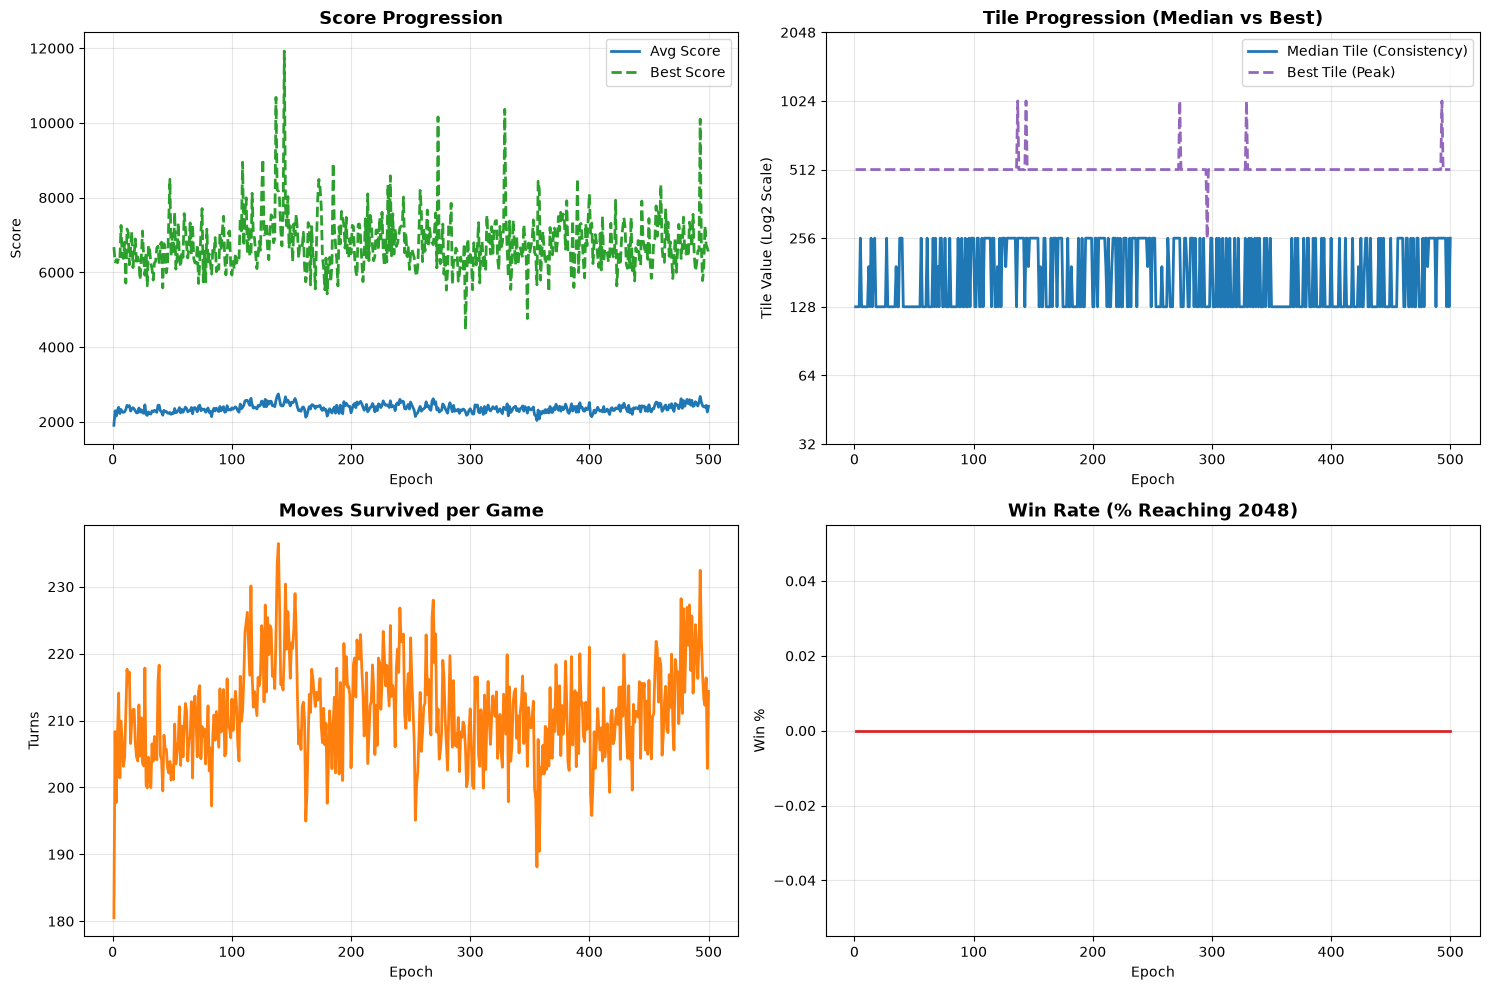

In [215]:
plot(history)

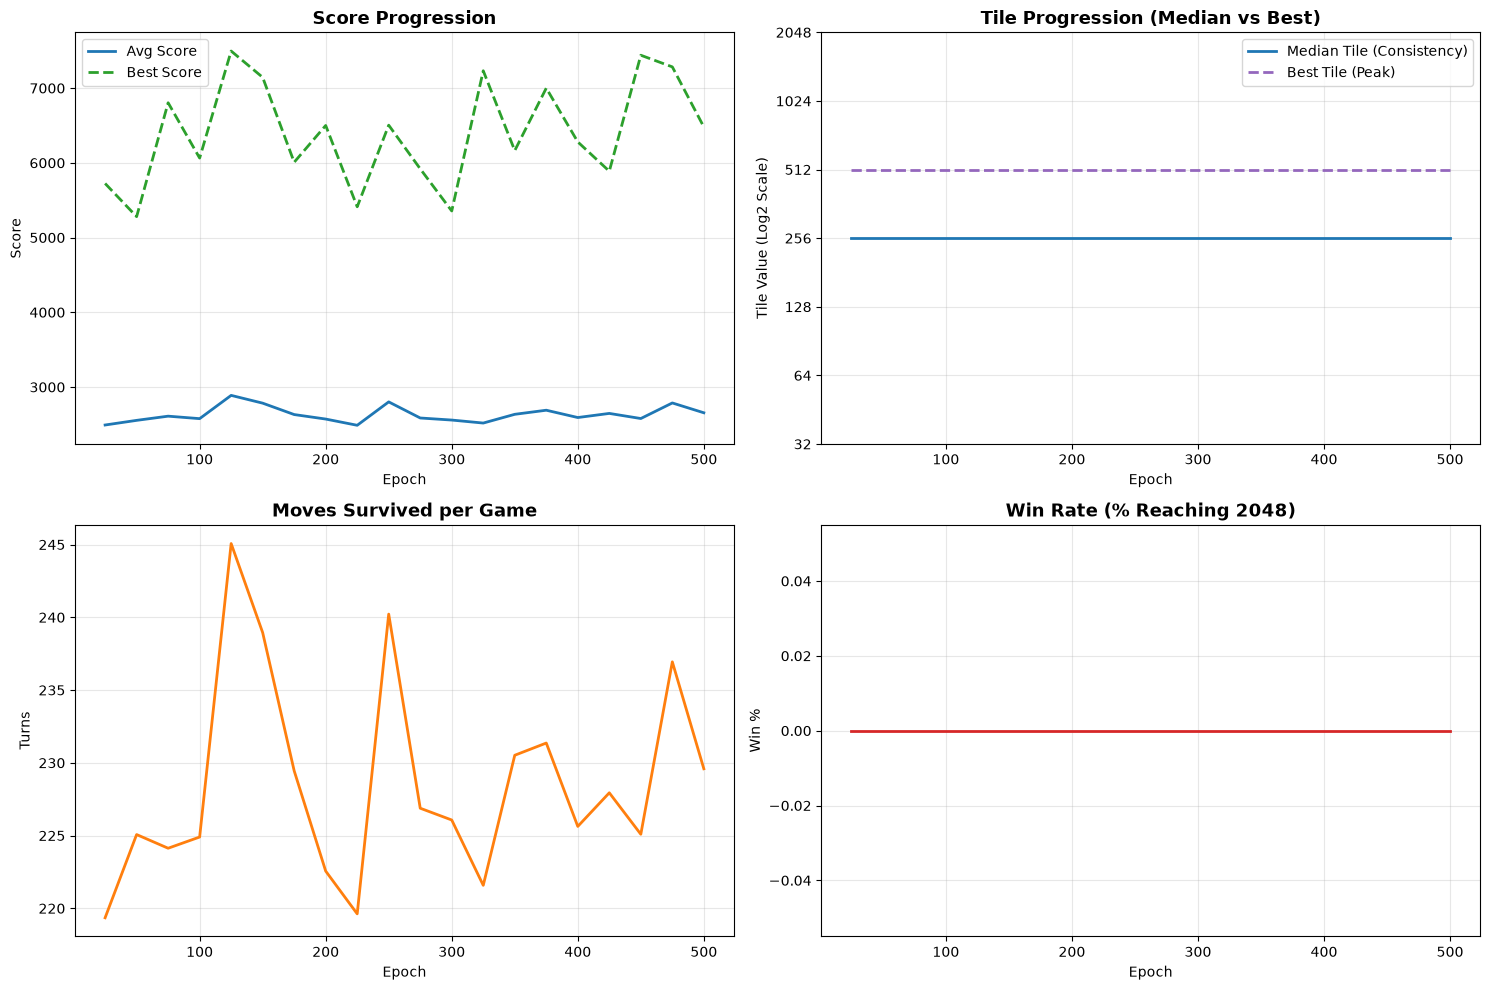

In [216]:
plot(parent_history)

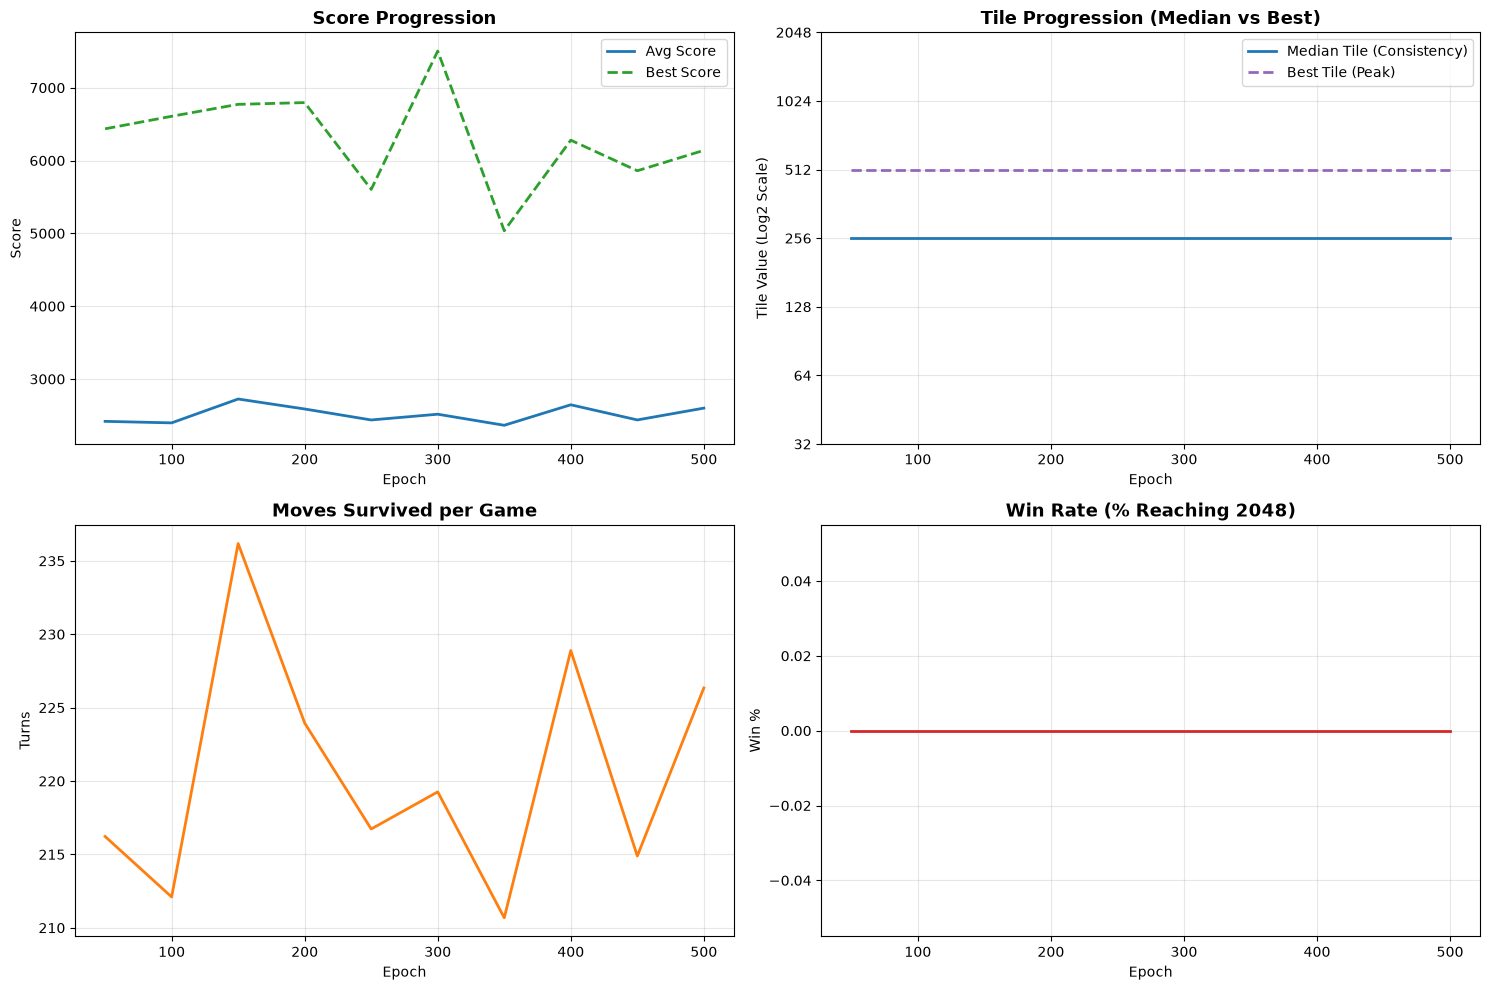

In [217]:
plot(elite_history)

In [76]:
history, parent_history, elite_history, leakyrelu_model_5_champions_2 = train(initialize_leakyrelu_model_3)

EPOCH 25: Parents Report (10 games each):
 Model  | Win Rate  | Median Tile  | Avg Score  | Best Score | Score Std  | Best Tile | Avg Moves
----------------------------------------------------------------------------------------------------------------------
  28    |   0.0%    |     256      |   3285.2   |    6468    |   1339.2   |    512    |   272.8  
  42    |   0.0%    |     256      |   3141.2   |    5536    |   1283.9   |    512    |   260.8  
  32    |   0.0%    |     256      |   2976.4   |    5352    |   1334.9   |    512    |   254.2  
  29    |   0.0%    |     256      |   3263.6   |    4332    |   783.1    |    256    |   276.8  
  31    |   0.0%    |     256      |   2988.8   |    3800    |   610.8    |    256    |   253.3  
  22    |   0.0%    |     256      |   2949.2   |    4480    |   1148.5   |    256    |   252.6  
  30    |   0.0%    |     256      |   2924.4   |    5636    |   1304.5   |    512    |   249.6  
  48    |   0.0%    |     256      |   2776.4   |    57

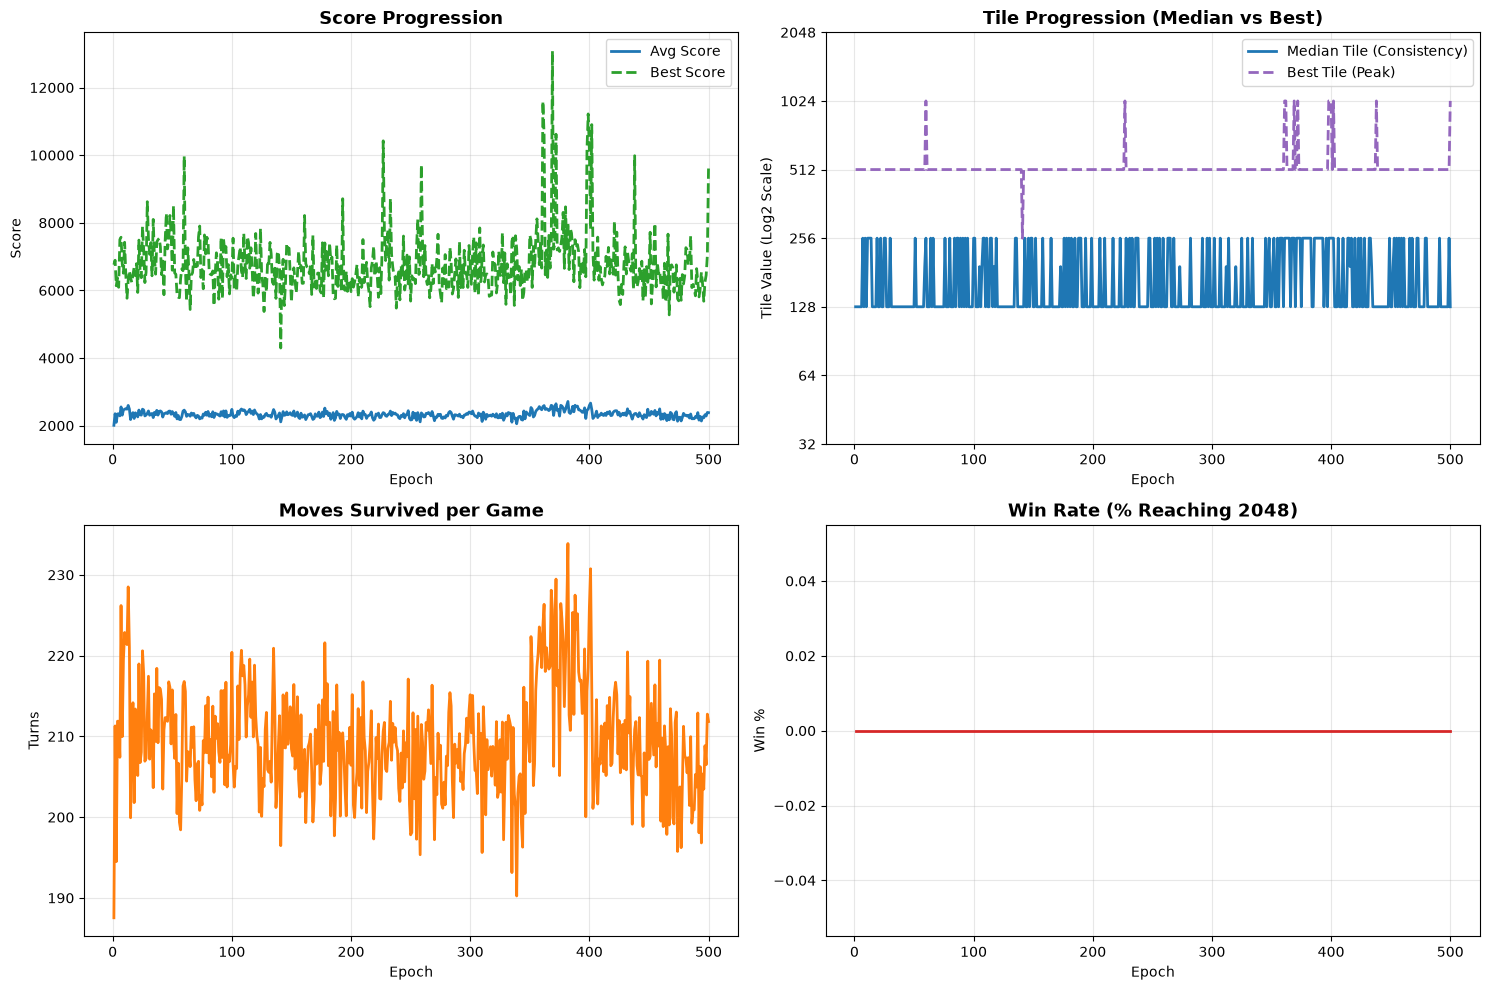

In [77]:
plot(history)

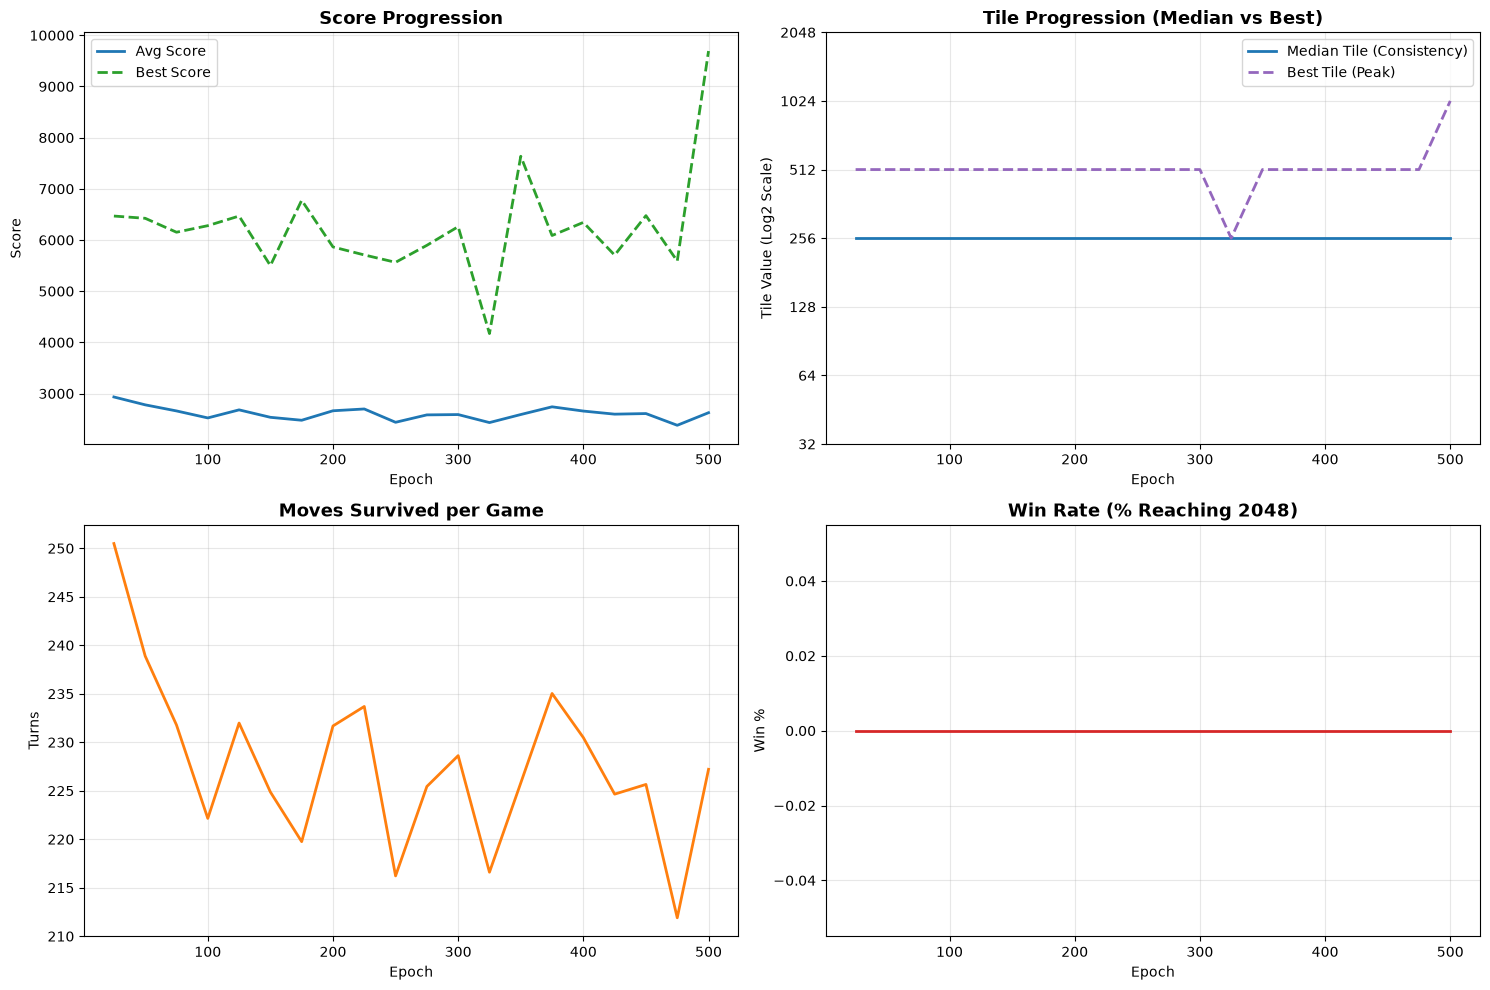

In [78]:
plot(parent_history)